# Analisis Survei Gen Z × PayLater × Kredivo
### Bukti Konsumen untuk **WOW Strategy** — *Widening the Mindshare · Owning the Preference · Winning the Market*

**Tim StacyTwo · Diponegoro Business Case Competition (DBCC) 2026 · Tahap Semifinal**

---

Notebook master ini mengolah hasil survei Google Form (**n = 103 responden Gen Z**) untuk menjawab pertanyaan inti case Kredivo:

> *"How would you increase Kredivo's brand awareness among Gen Z in big cities and turn awareness into conversions?"*

Seluruh analisis disusun untuk **menguji dan memperkuat logika WOW Strategy** yang sudah kami bangun di proposal preliminary:

| Gap yang diuji | Pertanyaan analisis | Pilar WOW | Perilaku |
|---|---|---|---|
| **Salience Gap** | Apakah Kredivo dikenal, tetapi belum menjadi brand pertama yang diingat Gen Z? | **Widening the Mindshare** → WOW Content + Community + Spots | REMEMBER |
| **Preference Gap** | Apa yang menghalangi awareness berubah menjadi trust dan preferensi? | **Owning the Preference** → Smart Choice + Proof + Fit | PREFER |
| **Activation Gap** | Kapan dan mengapa preferensi belum berubah menjadi transaksi? | **Winning the Market** → Kredivo NOW + Deals + WOW Loop | ACT & REPEAT |

### Alur Notebook
1. Setup & konfigurasi visual
2. Memuat, membersihkan & memvalidasi data
3. Snapshot eksekutif (angka kunci)
4. Profil responden
5. Perilaku & adopsi PayLater
6. Motivasi & momen kebutuhan
7. Decision drivers — apa yang menentukan pilihan PayLater
8. **Salience Gap** — dikenal, tetapi belum diingat pertama
9. **Brand Funnel Kredivo** — Remember → Prefer → Act
10. **Preference Gap** — trust, kejelasan biaya & hambatan
11. **Activation Gap** — dari preferensi ke transaksi
12. Analisis hubungan & key driver (data science)
13. Segmentasi responden (K-Means clustering)
14. Deep dive target inti: Gen Z Surabaya yang mulai mandiri finansial (Persona Raka)
15. Kata yang paling sering muncul (word cloud)
16. WOW Strategy Evidence Board
17. Kesimpulan, angka siap pakai untuk pitch deck & keterbatasan

### Cara Membaca
- **Top-2-Box (T2B)** = persentase responden yang menjawab **4 (Setuju)** atau **5 (Sangat Setuju)** pada skala Likert 1–5. Ini metrik utama karena lebih mudah dikomunikasikan di slide dibanding rata-rata.
- **Unaided Top-of-Mind (TOM)** = brand yang **pertama kali** disebut responden ketika mendengar kata "PayLater" tanpa diberi pilihan.
- Semua angka dihitung **otomatis dari `dataset.csv`**. Jika dataset diperbarui, cukup jalankan ulang notebook (*Run All*) — seluruh grafik, angka dan insight akan menyesuaikan.
- Semua grafik juga otomatis disimpan sebagai PNG resolusi tinggi di folder `outputs/figures/` agar bisa langsung dipakai di pitch deck.

## 1. Setup & Konfigurasi Visual

Palet warna mengikuti identitas Kredivo (biru `#45B7E1` dan oranye `#ED7D2A`) yang sudah **divalidasi untuk keterbacaan & ramah buta warna** (pasangan biru–oranye–ungu–hijau-toska lolos uji separasi CVD). Aturan warna yang dipakai konsisten di seluruh notebook:
- **Biru** = Kredivo / fokus utama / pilar *Widening*
- **Ungu** = pilar *Owning*
- **Oranye** = pilar *Winning* / titik masalah yang perlu perhatian
- **Abu-abu** = pembanding / brand lain

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(max(1, (os.cpu_count() or 2) // 2)))  # hindari warning joblib di Windows

import re
import textwrap
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch, FancyBboxPatch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from wordcloud import WordCloud
from IPython.display import display, Markdown

# ---------------------------------------------------------------------------
# KONFIGURASI
# ---------------------------------------------------------------------------
DATA_PATH = Path('dataset.csv')
OUT_DIR = Path('outputs')
FIG_DIR = OUT_DIR / 'figures'
SIMPAN_GAMBAR = True          # simpan setiap grafik ke outputs/figures/*.png
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Lihat penjelasan di Bagian 2.4. Ubah menjadi False HANYA jika seluruh respons
# di dataset.csv adalah respons asli dari Google Form.
DATA_MENGANDUNG_SIMULASI = True

SUMBER = 'Sumber: Survei Gen Z × PayLater, Tim StacyTwo — DBCC 2026'
if DATA_MENGANDUNG_SIMULASI:
    SUMBER += ' · dataset mengandung respons simulasi (prototipe analisis)'

# ---------------------------------------------------------------------------
# PALET WARNA (tervalidasi: lightness band, chroma, separasi CVD)
# ---------------------------------------------------------------------------
BIRU, BIRU_MUDA, BIRU_TUA = '#1B8EC2', '#45B7E1', '#0E4F70'
ORANYE, ORANYE_TUA = '#ED7D2A', '#C4521A'
UNGU, AQUA = '#4A3AA7', '#1BAF7A'
ABU, ABU_TUA, ABU_MUDA = '#C9CDD3', '#8A9099', '#F3F5F7'
TEKS, TEKS2, GRID = '#1F2328', '#57606A', '#E4E7EB'

KATEGORI = [BIRU, ORANYE, UNGU, AQUA]
ORDINAL3 = ['#45B7E1', '#1B8EC2', '#0E4F70']
LIKERT_WARNA = ['#C4521A', '#F2A36B', '#DADCE0', '#7CC6E8', '#1B8EC2']
PILAR_WARNA = {'Widening': BIRU, 'Owning': UNGU, 'Winning': ORANYE}
GRUP_WARNA = {'Pengguna Aktif': BIRU, 'Mantan Pengguna': UNGU,
              'Calon Pengguna': ORANYE, 'Tidak Tertarik': ABU_TUA}
CMAP_SEQ = LinearSegmentedColormap.from_list('seq_biru', ['#F4F9FC', '#A9D8EE', BIRU, BIRU_TUA])
CMAP_DIV = LinearSegmentedColormap.from_list('div', [ORANYE_TUA, '#F6C7A2', '#F0EFEC', '#A9D8EE', BIRU_TUA])

_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ['Segoe UI', 'Inter', 'Arial', 'DejaVu Sans'] if f in _fonts), 'DejaVu Sans')

plt.rcParams.update({
    'font.family': FONT, 'font.size': 11,
    'axes.titlesize': 13.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 12, 'axes.titlecolor': TEKS, 'axes.labelcolor': TEKS2, 'axes.labelsize': 11,
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': TEKS2, 'ytick.color': TEKS, 'xtick.labelsize': 10.5, 'ytick.labelsize': 10.5,
    'legend.frameon': False, 'legend.fontsize': 10.5, 'text.color': TEKS,
    'figure.dpi': 110, 'savefig.dpi': 200, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
pd.set_option('display.max_colwidth', 140)
pd.set_option('display.width', 200)

# ---------------------------------------------------------------------------
# FUNGSI BANTU
# ---------------------------------------------------------------------------
def fpct(x, d=0):
    """Format proporsi 0–1 menjadi persen gaya Indonesia (koma desimal)."""
    return f'{x * 100:.{d}f}%'.replace('.', ',')

def fnum(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

def wrap(s, w=28):
    return '\n'.join(textwrap.wrap(str(s), w, break_long_words=False))

def gaya(ax, grid='x'):
    ax.spines[['top', 'right']].set_visible(False)
    for sp in ['left', 'bottom']:
        ax.spines[sp].set_color(GRID)
    ax.tick_params(length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)

def bingkai(fig, judul, sub=None, catatan=None, sumber=True, legend=None, ncol=None):
    """Judul rata kiri + subjudul + legend (opsional) + catatan sumber, lalu rapikan layout."""
    h = fig.get_figheight()
    fig.text(0.012, 1 - 0.20 / h, judul, fontsize=17, fontweight='bold', color=TEKS, ha='left', va='top')
    pakai = 0.66
    if sub:
        n_baris = sub.count('\n') + 1
        fig.text(0.012, 1 - 0.60 / h, sub, fontsize=12, color=TEKS2, ha='left', va='top', linespacing=1.35)
        pakai = 0.72 + 0.25 * n_baris
    if legend:
        fig.legend(handles=legend, loc='upper left', bbox_to_anchor=(0.006, 1 - (pakai + 0.02) / h),
                   ncol=ncol or len(legend), fontsize=10.5, handlelength=1.3, columnspacing=1.8)
        pakai += 0.42
    top = 1 - pakai / h
    kaki = ' · '.join(x for x in [catatan, SUMBER if sumber else None] if x)
    bottom = 0
    if kaki:
        fig.text(0.012, 0.10 / h, kaki, fontsize=9, color=ABU_TUA, ha='left', va='bottom')
        bottom = 0.38 / h
    fig.tight_layout(rect=[0, bottom, 1, top])

def simpan(fig, nama):
    if SIMPAN_GAMBAR:
        fig.savefig(FIG_DIR / f'{nama}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def bar_h(ax, s, n=None, warna=BIRU, sorot=None, warna_sorot=BIRU, urut=True, lebar=30, d=0, xmax=None):
    """Bar horizontal berlabel persen. `s` = Series proporsi (0–1)."""
    s = s.sort_values() if urut else s.iloc[::-1]
    if sorot is not None:
        sorot = [sorot] if isinstance(sorot, str) else list(sorot)
        cols = [warna_sorot if k in sorot else ABU for k in s.index]
    elif isinstance(warna, dict):
        cols = [warna.get(k, ABU) for k in s.index]
    else:
        cols = [warna] * len(s)
    y = np.arange(len(s))
    bars = ax.barh(y, s.values, color=cols, height=0.68, edgecolor='white', linewidth=2)
    ax.set_yticks(y, [wrap(i, lebar) for i in s.index])
    lab = [fpct(v, d) + (f'  ({int(round(v * n))})' if n else '') for v in s.values]
    ax.bar_label(bars, lab, padding=5, fontsize=10.5, color=TEKS)
    ax.set_xlim(0, (xmax or s.max()) * 1.30)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    gaya(ax, 'x')
    ax.spines['left'].set_visible(False)
    return bars

def heatmap(ax, data, fmt='pct', cmap=CMAP_SEQ, vmin=None, vmax=None, cbar=False, fs=10.5, center=None):
    annot = data.map(lambda v: fpct(v) if fmt == 'pct' else (fnum(v) if fmt == 'num' else f'{int(v)}'))
    sns.heatmap(data, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, center=center, annot=annot, fmt='',
                cbar=cbar, linewidths=2, linecolor='white', annot_kws={'fontsize': fs})
    ax.tick_params(length=0)
    ax.set_xlabel(''); ax.set_ylabel('')

def likert_diverging(ax, data, lebar=34, label_t2b=True):
    """Stacked bar diverging untuk skala Likert 1–5. `data` = dict {label: Series skor}."""
    dist = pd.DataFrame({k: v.value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0)
                         for k, v in data.items()}).T
    dist['net'] = dist[4] + dist[5] - dist[1] - dist[2]
    dist = dist.sort_values('net')
    kiri = -(dist[1] + dist[2] + dist[3] / 2)
    y = np.arange(len(dist))
    start = kiri.values.copy()
    for skor, warna in zip([1, 2, 3, 4, 5], LIKERT_WARNA):
        w = dist[skor].values
        ax.barh(y, w, left=start, color=warna, height=0.7, edgecolor='white', linewidth=1.5)
        for yi, (st, wi) in enumerate(zip(start, w)):
            if wi >= 0.07:
                ax.text(st + wi / 2, yi, fpct(wi), ha='center', va='center', fontsize=9.5,
                        color='white' if skor in (1, 5) else TEKS)
        start = start + w
    if label_t2b:
        for yi, (end, t2b) in enumerate(zip(start, dist[4] + dist[5])):
            ax.text(end + 0.02, yi, f'T2B {fpct(t2b)}', va='center', fontsize=10.5, fontweight='bold', color=TEKS)
    ax.set_yticks(y, [wrap(i, lebar) for i in dist.index])
    ax.axvline(0, color=TEKS2, linewidth=0.8)
    ax.set_xlim(min(kiri.min(), -0.1) - 0.04, start.max() + 0.16)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fpct(abs(v))))
    gaya(ax, 'x'); ax.spines['left'].set_visible(False)
    handles = [Patch(color=c, label=l) for c, l in zip(LIKERT_WARNA,
               ['Sangat tidak setuju', 'Tidak setuju', 'Netral', 'Setuju', 'Sangat setuju'])]
    return dist, handles

def insight(judul, poin):
    teks = f'> ### 💡 {judul}\n>\n' + '\n'.join(f'> - {p}' for p in poin)
    display(Markdown(teks))

def uji_chi(a, b, data=None):
    data = df if data is None else data
    ct = pd.crosstab(data[a], data[b])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return {'chi2': round(chi2, 2), 'dof': dof, 'p-value': round(p, 4), "Cramér's V": round(v, 3),
            'Min. expected': round(exp.min(), 1)}

print(f'Setup selesai · font: {FONT} · grafik disimpan ke: {FIG_DIR.resolve()}')

Setup selesai · font: Segoe UI · grafik disimpan ke: C:\Users\ASUS\xStyNWx\Documents\BINUS University\Competition\2026\00. Bersama Stacy\03. DBCC\Repo\data-analysis\outputs\figures


## 2. Memuat, Membersihkan & Memvalidasi Data

### 2.1 Memuat data & kamus kolom
Nama kolom Google Form sangat panjang, sehingga kami ganti dengan nama pendek. Tabel di bawah adalah **kamus data** yang menghubungkan nama kolom baru dengan pertanyaan aslinya.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding='utf-8')
assert df_raw.shape[1] == 29, 'Struktur kolom dataset berubah — periksa kembali urutan pertanyaan Google Form.'

KOLOM = ['timestamp', 'usia', 'domisili', 'status', 'penghasilan', 'pengeluaran', 'frek_digital',
         'status_paylater', 'alasan_raw', 'kebutuhan_raw',
         'relevan', 'cashflow', 'paham', 'cepat', 'transparan', 'aman', 'merchant', 'promo',
         'teman', 'creator', 'konten', 'fisik',
         'tom', 'k_familiar', 'k_recall', 'k_trust', 'k_consider', 'k_intent', 'hambatan']

kamus = pd.DataFrame({'Kolom baru': KOLOM, 'Pertanyaan asli (Google Form)': [c.strip() for c in df_raw.columns]})
kamus.index = kamus.index + 1

df = df_raw.copy()
df.columns = KOLOM
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%m/%d/%Y %H:%M:%S', errors='coerce')
for c in df.select_dtypes('object').columns:
    df[c] = df[c].astype(str).str.strip()

print(f'Dataset dimuat: {df.shape[0]} responden × {df.shape[1]} kolom')
display(kamus)

Dataset dimuat: 103 responden × 29 kolom


,Kolom baru,Pertanyaan asli (Google Form)
1,timestamp,Timestamp
2,usia,Usia
3,domisili,Domisili
4,status,Status Saat Ini
5,penghasilan,Penghasilan Pribadi per Bulan
6,pengeluaran,Pengeluaran Pribadi Rata-rata per Bulan
7,frek_digital,Seberapa sering Anda melakukan transaksi digital?
8,status_paylater,Apakah Anda pernah menggunakan PayLater?
9,alasan_raw,Apa alasan utama Anda menggunakan atau tertarik menggunakan PayLater? (Pilih tepat 3 opsi)!
10,kebutuhan_raw,Untuk kebutuhan apa Anda paling mungkin menggunakan PayLater?


### 2.2 Label, urutan kategori & feature engineering
Beberapa langkah penting:
- **Parsing pertanyaan multi-pilihan.** Opsi *"Promo, cashback, atau diskon"* mengandung koma sehingga pemisahan biasa berdasarkan koma akan **salah menghitung** (terbaca 5 pilihan, padahal responden memilih tepat 3). Karena itu parsing dilakukan berdasarkan **daftar opsi yang diketahui**.
- **Grup status PayLater** (4 grup): *Pengguna Aktif* (sering + sesekali), *Mantan Pengguna*, *Calon Pengguna* (belum pernah tapi tertarik), *Tidak Tertarik*.
- **Mandiri finansial** = responden dengan penghasilan pribadi ≥ Rp1 juta/bulan — proxy dari target WOW: *Gen Z entering financial independence*.
- **Target Inti (Persona Raka)** = mandiri finansial **dan** berdomisili di **Surabaya** (kota pilihan WOW Strategy).

In [3]:
LIKERT_SIKAP = ['relevan', 'cashflow', 'paham', 'cepat', 'transparan', 'aman', 'merchant', 'promo',
                'teman', 'creator', 'konten', 'fisik']
LIKERT_KREDIVO = ['k_familiar', 'k_recall', 'k_trust', 'k_consider', 'k_intent']
LIKERT = LIKERT_SIKAP + LIKERT_KREDIVO

LABEL = {
    'relevan': 'PayLater relevan dengan kebutuhan finansial saya',
    'cashflow': 'PayLater membantu mengatur cash flow',
    'paham': 'Saya paham biaya, bunga, jatuh tempo & risiko',
    'cepat': 'Proses daftar & transaksi cepat memengaruhi pilihan',
    'transparan': 'Transparansi biaya & cicilan memengaruhi kepercayaan',
    'aman': 'Keamanan data & kredibilitas memengaruhi pilihan',
    'merchant': 'Banyaknya merchant online/offline memengaruhi pilihan',
    'promo': 'Promo, cashback & deals mendorong saya mencoba',
    'teman': 'Rekomendasi teman/keluarga memengaruhi pilihan',
    'creator': 'Rekomendasi creator/komunitas membuat saya tertarik',
    'konten': 'Konten lifestyle Gen Z membuat brand mudah diingat',
    'fisik': 'Kehadiran brand di kampus/mall/event membuat mudah diingat',
    'k_familiar': 'Familiar dengan Kredivo',
    'k_recall': 'Kredivo salah satu brand pertama yang diingat',
    'k_trust': 'Percaya Kredivo aman & andal',
    'k_consider': 'Akan mempertimbangkan Kredivo',
    'k_intent': 'Berniat pakai Kredivo dalam 6 bulan',
}
LABEL_PENDEK = {
    'relevan': 'Relevansi kebutuhan', 'cashflow': 'Bantu atur cash flow', 'paham': 'Paham biaya & risiko',
    'cepat': 'Proses cepat & mudah', 'transparan': 'Transparansi biaya', 'aman': 'Keamanan & kredibilitas',
    'merchant': 'Banyak merchant', 'promo': 'Promo & cashback', 'teman': 'Rekomendasi teman/keluarga',
    'creator': 'Rekomendasi creator/komunitas', 'konten': 'Konten lifestyle Gen Z', 'fisik': 'Kehadiran fisik (kampus/mall)',
    'k_familiar': 'Familiar Kredivo', 'k_recall': 'Kredivo diingat pertama', 'k_trust': 'Percaya Kredivo',
    'k_consider': 'Pertimbangkan Kredivo', 'k_intent': 'Niat pakai Kredivo',
}
DRIVER_GRUP = {
    'relevan': 'Kebutuhan & Relevansi', 'cashflow': 'Kontrol Finansial', 'paham': 'Kontrol Finansial',
    'cepat': 'Convenience', 'merchant': 'Aksesibilitas', 'transparan': 'Trust & Keamanan', 'aman': 'Trust & Keamanan',
    'promo': 'Promo & Value', 'teman': 'Pengaruh Sosial', 'creator': 'Pengaruh Sosial',
    'konten': 'Brand Salience', 'fisik': 'Brand Salience',
}
WOW_MAP = {  # item sikap -> pilar WOW yang paling relevan
    'konten': 'Widening', 'creator': 'Widening', 'fisik': 'Widening',
    'paham': 'Owning', 'transparan': 'Owning', 'aman': 'Owning', 'teman': 'Owning', 'relevan': 'Owning',
    'promo': 'Winning', 'merchant': 'Winning', 'cashflow': 'Winning', 'cepat': 'Winning',
}
FUNNEL = [  # (kolom, tahap, perilaku, pilar)
    ('k_familiar', 'Familiar', 'REMEMBER', 'Widening'),
    ('k_recall', 'Diingat (aided)', 'REMEMBER', 'Widening'),
    ('k_trust', 'Percaya', 'PREFER', 'Owning'),
    ('k_consider', 'Mempertimbangkan', 'PREFER', 'Owning'),
    ('k_intent', 'Niat pakai (6 bln)', 'ACT', 'Winning'),
]

ORDER = {
    'usia': ['18–20 tahun', '21–23 tahun', '24–26 tahun'],
    'domisili': ['Surabaya', 'Jawa Timur (di luar Surabaya)', 'Di luar Jawa Timur'],
    'status': ['Pelajar/Mahasiswa', 'Karyawan', 'Freelancer/Wirausaha', 'Sedang mencari kerja'],
    'penghasilan': ['Belum memiliki penghasilan', '< Rp1 juta', 'Rp1–<2 juta', 'Rp2–<4 juta',
                    'Rp4–<6 juta', 'Rp6–<10 juta', '≥ Rp10 juta'],
    'pengeluaran': ['< Rp1 juta', 'Rp1–<2 juta', 'Rp2–<4 juta', 'Rp4–<6 juta', '≥ Rp6 juta'],
    'frek_digital': ['Beberapa kali per bulan', '1–2 kali per minggu', '3–5 kali per minggu', 'Hampir setiap hari'],
    'status_paylater': ['Sering menggunakan', 'Masih menggunakan sesekali', 'Pernah menggunakan, tetapi sudah tidak',
                        'Belum pernah, tetapi tertarik mencoba', 'Belum pernah dan belum tertarik'],
    'grup_pengguna': ['Pengguna Aktif', 'Mantan Pengguna', 'Calon Pengguna', 'Tidak Tertarik'],
    'penghasilan_grup': ['Belum / < Rp1 jt', 'Rp1–<4 jt', '≥ Rp4 jt'],
}
for kol in ['usia', 'domisili', 'status', 'penghasilan', 'pengeluaran', 'frek_digital', 'status_paylater']:
    tak_dikenal = set(df[kol]) - set(ORDER[kol])
    assert not tak_dikenal, f'Kategori baru di kolom {kol}: {tak_dikenal}'

# --- Pertanyaan multi-pilihan ---
OPSI_ALASAN = {
    'Mengatur cash flow/pengeluaran': 'Mengatur cash flow',
    'Fleksibilitas waktu pembayaran': 'Fleksibilitas waktu bayar',
    'Memenuhi kebutuhan mendesak': 'Memenuhi kebutuhan mendesak',
    'Tersedia di merchant yang saya gunakan': 'Tersedia di merchant favorit',
    'Promo, cashback, atau diskon': 'Promo, cashback, diskon',
    'Mencicil pembelian bernilai besar': 'Mencicil barang bernilai besar',
    'Lebih mudah daripada kartu kredit': 'Lebih mudah dari kartu kredit',
    'Belum tertarik menggunakan PayLater': 'Belum tertarik PayLater',
}
OPSI_KEBUTUHAN = ['Gadget & elektronik', 'Pendidikan/kebutuhan kerja', 'Kebutuhan darurat', 'Makanan & minuman',
                  'Fashion', 'Beauty/personal care', 'Transportasi/travel', 'Token listrik']

def pecah(teks, opsi):
    return [o for o in opsi if o.lower() in str(teks).lower()]

def sisa(teks, opsi):
    t = str(teks)
    for o in opsi:
        t = t.replace(o, '')
    return t.replace(',', '').strip()

df['alasan'] = df['alasan_raw'].apply(lambda s: [OPSI_ALASAN[o] for o in pecah(s, OPSI_ALASAN)])
df['kebutuhan'] = df['kebutuhan_raw'].apply(lambda s: pecah(s, OPSI_KEBUTUHAN))
assert df['alasan_raw'].apply(lambda s: sisa(s, OPSI_ALASAN)).eq('').all(), 'Ada opsi alasan yang tidak dikenali'
assert df['kebutuhan_raw'].apply(lambda s: sisa(s, OPSI_KEBUTUHAN)).eq('').all(), 'Ada opsi kebutuhan yang tidak dikenali'

ALASAN = pd.DataFrame([{v: int(v in l) for v in OPSI_ALASAN.values()} for l in df['alasan']], index=df.index)
KEBUTUHAN = pd.DataFrame([{v: int(v in l) for v in OPSI_KEBUTUHAN} for l in df['kebutuhan']], index=df.index)

# --- Feature engineering ---
GRUP_MAP = {
    'Sering menggunakan': 'Pengguna Aktif', 'Masih menggunakan sesekali': 'Pengguna Aktif',
    'Pernah menggunakan, tetapi sudah tidak': 'Mantan Pengguna',
    'Belum pernah, tetapi tertarik mencoba': 'Calon Pengguna',
    'Belum pernah dan belum tertarik': 'Tidak Tertarik',
}
df['grup_pengguna'] = df['status_paylater'].map(GRUP_MAP)
df['pernah_pakai'] = df['grup_pengguna'].isin(['Pengguna Aktif', 'Mantan Pengguna'])
df['penghasilan_grup'] = df['penghasilan'].map({
    'Belum memiliki penghasilan': 'Belum / < Rp1 jt', '< Rp1 juta': 'Belum / < Rp1 jt',
    'Rp1–<2 juta': 'Rp1–<4 jt', 'Rp2–<4 juta': 'Rp1–<4 jt',
    'Rp4–<6 juta': '≥ Rp4 jt', 'Rp6–<10 juta': '≥ Rp4 jt', '≥ Rp10 juta': '≥ Rp4 jt'})
df['mandiri_finansial'] = ~df['penghasilan'].isin(['Belum memiliki penghasilan', '< Rp1 juta'])
df['target_inti'] = df['mandiri_finansial'] & df['domisili'].eq('Surabaya')
df['segmen_target'] = np.where(df['target_inti'], 'Target Inti (Raka)', 'Responden lain')
df['tom_kredivo'] = df['tom'].eq('Kredivo')
for c in LIKERT:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    df[f'{c}_t2b'] = df[c] >= 4

N = len(df)
T2B = {c: df[f'{c}_t2b'].mean() for c in LIKERT}

SEGMEN = {  # dimensi segmentasi yang dipakai berulang
    'Usia': 'usia', 'Domisili': 'domisili', 'Status': 'status',
    'Penghasilan': 'penghasilan_grup', 'Status PayLater': 'grup_pengguna',
}
print(f'Feature engineering selesai · {N} responden')
print(f'  Mandiri finansial (penghasilan ≥ Rp1 jt): {df.mandiri_finansial.sum()} responden')
print(f'  Target Inti (mandiri finansial + Surabaya): {df.target_inti.sum()} responden')
display(df[['usia', 'status', 'penghasilan', 'grup_pengguna', 'tom', 'alasan', 'kebutuhan', 'hambatan']].head())

Feature engineering selesai · 103 responden
  Mandiri finansial (penghasilan ≥ Rp1 jt): 76 responden
  Target Inti (mandiri finansial + Surabaya): 42 responden


,usia,status,penghasilan,grup_pengguna,tom,alasan,kebutuhan,hambatan
0,21–23 tahun,Pelajar/Mahasiswa,< Rp1 juta,Calon Pengguna,Kredivo,"[Mengatur cash flow, Tersedia di merchant favorit, Mencicil barang bernilai besar]","[Gadget & elektronik, Pendidikan/kebutuhan kerja, Kebutuhan darurat]",Khawatir terhadap bunga atau biaya tambahan
1,21–23 tahun,Pelajar/Mahasiswa,Belum memiliki penghasilan,Tidak Tertarik,SPayLater,"[Fleksibilitas waktu bayar, Lebih mudah dari kartu kredit, Belum tertarik PayLater]","[Gadget & elektronik, Pendidikan/kebutuhan kerja, Fashion]",Belum membutuhkan PayLater
2,18–20 tahun,Pelajar/Mahasiswa,Belum memiliki penghasilan,Pengguna Aktif,SPayLater,"[Fleksibilitas waktu bayar, Memenuhi kebutuhan mendesak, Tersedia di merchant favorit]","[Kebutuhan darurat, Beauty/personal care, Token listrik]",Khawatir terhadap bunga atau biaya tambahan
3,24–26 tahun,Pelajar/Mahasiswa,< Rp1 juta,Pengguna Aktif,SPayLater,"[Fleksibilitas waktu bayar, Tersedia di merchant favorit, Promo, cashback, diskon]","[Kebutuhan darurat, Makanan & minuman, Token listrik]",Khawatir terhadap bunga atau biaya tambahan
4,21–23 tahun,Karyawan,Rp4–<6 juta,Tidak Tertarik,SPayLater,"[Fleksibilitas waktu bayar, Tersedia di merchant favorit, Belum tertarik PayLater]","[Makanan & minuman, Beauty/personal care, Token listrik]",Khawatir terhadap bunga atau biaya tambahan


### 2.3 Pemeriksaan kualitas data
Sebelum menarik insight, kami memastikan data **lengkap, konsisten dan valid** sesuai aturan kuesioner.

In [4]:
naif_alasan = df['alasan_raw'].str.split(',').str.len()
straight = (df[LIKERT].nunique(axis=1) == 1).sum()
tidak_tertarik_konsisten = pd.crosstab(df['grup_pengguna'].eq('Tidak Tertarik'),
                                       ALASAN['Belum tertarik PayLater'].astype(bool))
cek = pd.DataFrame([
    ['Jumlah responden', f'{N}', '✔'],
    ['Nilai kosong (missing)', f'{int(df_raw.isna().sum().sum())} sel', '✔' if df_raw.isna().sum().sum() == 0 else '⚠'],
    ['Baris duplikat', f'{int(df_raw.duplicated().sum())}', '✔' if df_raw.duplicated().sum() == 0 else '⚠'],
    ['Semua responden Gen Z (18–26 tahun)', f'{df.usia.isin(ORDER["usia"]).mean():.0%}', '✔'],
    ['Skor Likert dalam rentang 1–5', 'Ya' if df[LIKERT].isin([1, 2, 3, 4, 5]).all().all() else 'Tidak', '✔'],
    ['Alasan: memilih tepat 3 opsi', f'{(df.alasan.str.len() == 3).sum()} dari {N}', '✔'],
    ['Alasan: salah hitung jika dipisah per koma', f'{(naif_alasan != 3).sum()} responden (sudah diperbaiki)', 'ℹ'],
    ['Kebutuhan: memilih 3 opsi', f'{(df.kebutuhan.str.len() == 3).sum()} dari {N}', '✔'],
    ['Straight-lining (semua jawaban Likert identik)', f'{straight} responden', '✔' if straight == 0 else '⚠'],
    ['Konsistensi "Tidak Tertarik" ↔ opsi "Belum tertarik PayLater"',
     f'{int(tidak_tertarik_konsisten.values.trace())} dari {N} konsisten', 'ℹ'],
], columns=['Pemeriksaan', 'Hasil', 'Status'])
display(cek.style.hide(axis='index'))

Pemeriksaan,Hasil,Status
Jumlah responden,103,✔
Nilai kosong (missing),0 sel,✔
Baris duplikat,0,✔
Semua responden Gen Z (18–26 tahun),100%,✔
Skor Likert dalam rentang 1–5,Ya,✔
Alasan: memilih tepat 3 opsi,103 dari 103,✔
Alasan: salah hitung jika dipisah per koma,39 responden (sudah diperbaiki),ℹ
Kebutuhan: memilih 3 opsi,103 dari 103,✔
Straight-lining (semua jawaban Likert identik),0 responden,✔
"Konsistensi ""Tidak Tertarik"" ↔ opsi ""Belum tertarik PayLater""",103 dari 103 konsisten,ℹ


### 2.4 Catatan integritas & asal-usul data (penting sebelum presentasi)
Master context tim (`docs/context.md`, poin 25) mencatat bahwa pernah dibuat **100 respons sintetis** (timestamp 26–28 September 2026) yang digabung dengan **3 respons observasi** untuk keperluan prototipe analisis. Sel berikut memeriksa pola dataset saat ini secara objektif:
- **Distribusi tanggal respons** — apakah cocok dengan pola simulasi tersebut?
- **Korelasi antar-item & Cronbach's α** — data survei asli biasanya menunjukkan korelasi positif antar pernyataan yang saling berkaitan (misalnya "percaya Kredivo" dengan "mempertimbangkan Kredivo"). Korelasi yang mendekati nol di semua pasangan adalah tanda jawaban dibangkitkan secara independen.

In [5]:
def cronbach_alpha(X):
    X = np.asarray(X, float)
    k = X.shape[1]
    return k / (k - 1) * (1 - X.var(axis=0, ddof=1).sum() / X.sum(axis=1).var(ddof=1))

per_tanggal = df['timestamp'].dt.date.value_counts().sort_index().rename('Jumlah respons').to_frame()
per_tanggal.index.name = 'Tanggal'
korelasi = df[LIKERT].corr('spearman').where(np.triu(np.ones((len(LIKERT),) * 2, bool), 1)).stack()
integritas = pd.DataFrame([
    ['Rentang tanggal respons', f"{df.timestamp.min():%d %b %Y} – {df.timestamp.max():%d %b %Y}"],
    ['Respons pada 26–28 Sep 2026', f"{df.timestamp.dt.date.astype(str).between('2026-09-26', '2026-09-28').sum()} responden"],
    ['Rata-rata |korelasi| antar 17 item Likert', fnum(korelasi.abs().mean(), 3)],
    ['Korelasi terkuat antar item', f"{fnum(korelasi.abs().max(), 3)}"],
    ["Cronbach's α — 5 item brand funnel Kredivo", fnum(cronbach_alpha(df[LIKERT_KREDIVO]), 3)],
    ["Cronbach's α — 12 item sikap PayLater", fnum(cronbach_alpha(df[LIKERT_SIKAP]), 3)],
], columns=['Indikator', 'Nilai'])
display(per_tanggal.T)
display(integritas.style.hide(axis='index'))

status_data = ('⚠️ **Dataset ditandai mengandung respons simulasi** (`DATA_MENGANDUNG_SIMULASI = True`). '
               'Seluruh angka di notebook ini valid sebagai **prototipe analisis & latihan storytelling**, tetapi '
               '**tidak boleh dipresentasikan sebagai 103 responden riil**. Setelah respons asli terkumpul, ganti '
               '`dataset.csv`, ubah flag menjadi `False`, lalu *Run All* — semua grafik & insight akan diperbarui otomatis.'
               if DATA_MENGANDUNG_SIMULASI else
               '✅ Dataset ditandai sebagai **respons asli**. Cantumkan label sumber *"Primary Survey, n = '
               f'{N}, Gen Z, 2026"* di setiap slide yang memakai angka dari notebook ini.')
display(Markdown(status_data))

Tanggal,2026-09-03,2026-09-26,2026-09-27,2026-09-28
Jumlah respons,3,26,38,36


Indikator,Nilai
Rentang tanggal respons,03 Sep 2026 – 28 Sep 2026
Respons pada 26–28 Sep 2026,100 responden
Rata-rata |korelasi| antar 17 item Likert,"0,080"
Korelasi terkuat antar item,"0,364"
Cronbach's α — 5 item brand funnel Kredivo,"0,153"
Cronbach's α — 12 item sikap PayLater,"0,084"


⚠️ **Dataset ditandai mengandung respons simulasi** (`DATA_MENGANDUNG_SIMULASI = True`). Seluruh angka di notebook ini valid sebagai **prototipe analisis & latihan storytelling**, tetapi **tidak boleh dipresentasikan sebagai 103 responden riil**. Setelah respons asli terkumpul, ganti `dataset.csv`, ubah flag menjadi `False`, lalu *Run All* — semua grafik & insight akan diperbarui otomatis.

**Cara membaca indikator di atas:** α < 0,5 dan korelasi rata-rata mendekati 0 berarti antar pernyataan hampir tidak saling berhubungan. Pada data survei riil, pernyataan seperti *percaya → mempertimbangkan → berniat memakai* biasanya bergerak searah (α ≥ 0,6). Karena itu, **analisis yang berbasis hubungan antar variabel (korelasi, key driver, clustering) di Bagian 12–13 harus dibaca sebagai indikatif**, sedangkan analisis **deskriptif (persentase, funnel, top-of-mind, hambatan)** tetap informatif untuk membangun narasi. Semua analisis tetap dijalankan item per item (bukan skor komposit) agar tidak bergantung pada reliabilitas konstruk.

## 3. Snapshot Eksekutif — Angka Kunci dalam Satu Layar
Delapan angka berikut adalah ringkasan paling penting dari survei. Garis warna di tiap kartu menunjukkan pilar WOW yang relevan (**biru** = Widening, **ungu** = Owning, **oranye** = Winning, **abu-abu** = profil).

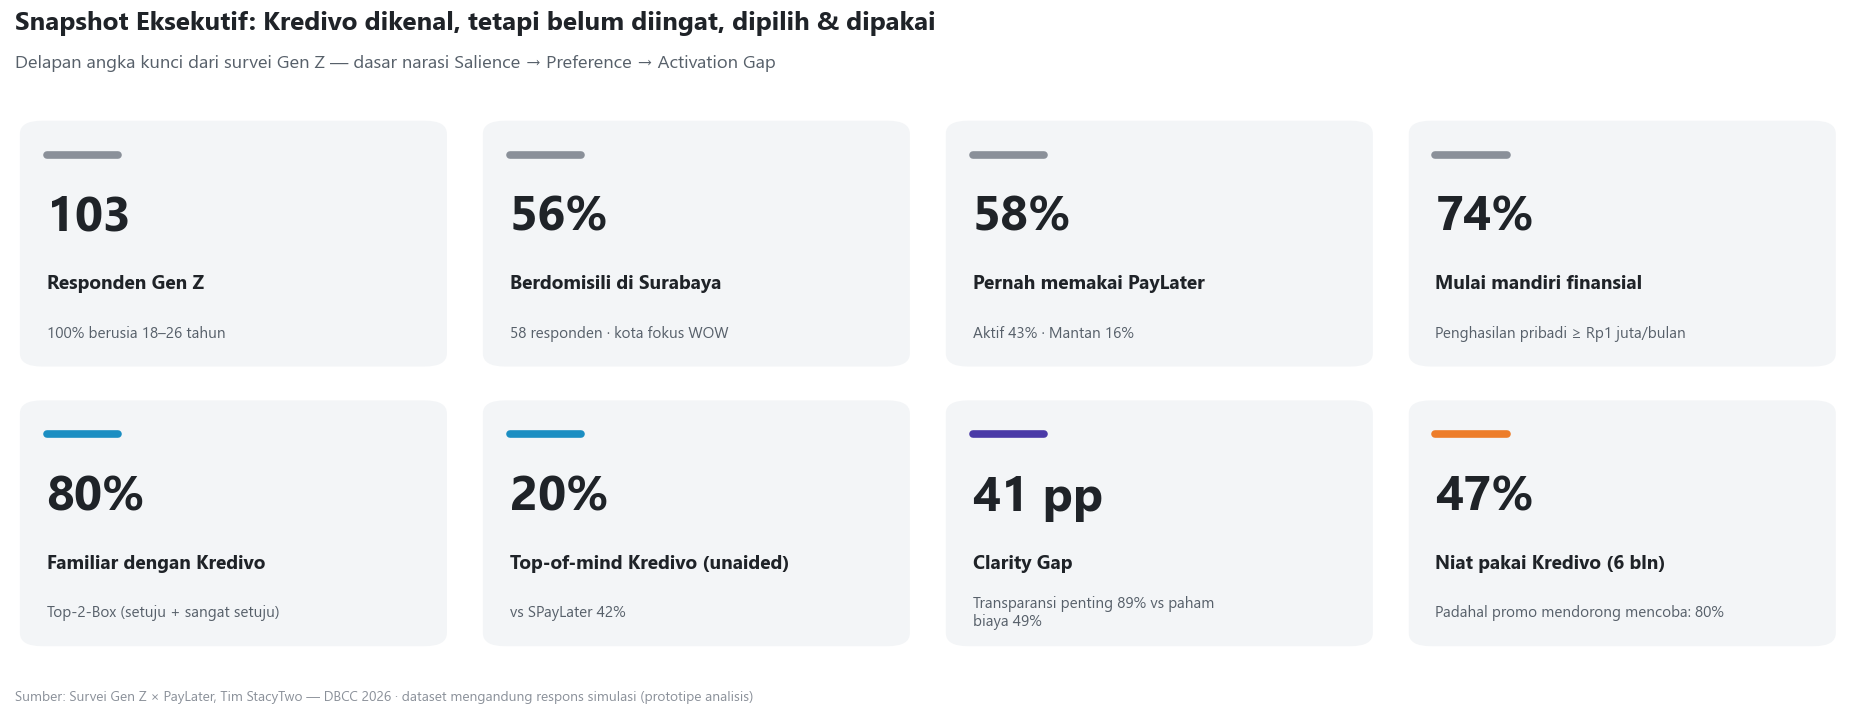

> ### 💡 Headline untuk pitch deck
>
> - **80%** Gen Z familiar dengan Kredivo, tetapi hanya **20%** yang menyebut Kredivo sebagai brand PayLater **pertama** (unaided) — SPayLater memimpin dengan **42%**.
> - Faktor terpenting dalam memilih PayLater adalah **transparansi biaya (89%)** dan **keamanan (88%)**, namun hanya **49%** yang benar-benar paham biaya, bunga & risiko → **Clarity Gap 41 poin**.
> - Promo mendorong **80%** responden untuk mencoba, tetapi niat memakai Kredivo 6 bulan ke depan baru **47%** → aktivasi belum otomatis terjadi.
> - **Kesimpulan:** *Kredivo is seen, but not yet consistently remembered, chosen, and used* — tepat seperti diagnosis WOW Strategy.

In [6]:
tom_share = df['tom'].value_counts(normalize=True)
pemimpin_tom = tom_share.index[0]
gap_clarity = T2B['transparan'] - T2B['paham']

kartu = [
    (f'{N}', 'Responden Gen Z', f"{df.usia.isin(ORDER['usia']).mean():.0%} berusia 18–26 tahun", ABU_TUA),
    (fpct(df.domisili.eq('Surabaya').mean()), 'Berdomisili di Surabaya', f"{df.domisili.eq('Surabaya').sum()} responden · kota fokus WOW", ABU_TUA),
    (fpct(df.pernah_pakai.mean()), 'Pernah memakai PayLater',
     f"Aktif {fpct(df.grup_pengguna.eq('Pengguna Aktif').mean())} · Mantan {fpct(df.grup_pengguna.eq('Mantan Pengguna').mean())}", ABU_TUA),
    (fpct(df.mandiri_finansial.mean()), 'Mulai mandiri finansial', 'Penghasilan pribadi ≥ Rp1 juta/bulan', ABU_TUA),
    (fpct(T2B['k_familiar']), 'Familiar dengan Kredivo', 'Top-2-Box (setuju + sangat setuju)', BIRU),
    (fpct(tom_share.get('Kredivo', 0)), 'Top-of-mind Kredivo (unaided)',
     f"vs {pemimpin_tom} {fpct(tom_share.iloc[0])}" if pemimpin_tom != 'Kredivo' else 'Kredivo memimpin', BIRU),
    (f"{gap_clarity * 100:.0f} pp", 'Clarity Gap',
     f"Transparansi penting {fpct(T2B['transparan'])} vs paham biaya {fpct(T2B['paham'])}", UNGU),
    (fpct(T2B['k_intent']), 'Niat pakai Kredivo (6 bln)', f"Padahal promo mendorong mencoba: {fpct(T2B['promo'])}", ORANYE),
]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.6))
for ax, (angka, label, catatan, warna) in zip(axes.flat, kartu):
    ax.axis('off')
    ax.add_patch(FancyBboxPatch((0.02, 0.03), 0.96, 0.94, boxstyle='round,pad=0,rounding_size=0.05',
                                transform=ax.transAxes, facecolor=ABU_MUDA, edgecolor='none'))
    ax.plot([0.08, 0.24], [0.84, 0.84], color=warna, linewidth=5, solid_capstyle='round', transform=ax.transAxes)
    ax.text(0.08, 0.60, angka, fontsize=32, fontweight='bold', color=TEKS, transform=ax.transAxes, va='center')
    ax.text(0.08, 0.35, label, fontsize=12.5, fontweight='bold', color=TEKS, transform=ax.transAxes, va='center')
    ax.text(0.08, 0.16, wrap(catatan, 38), fontsize=10, color=TEKS2, transform=ax.transAxes, va='center')
bingkai(fig, 'Snapshot Eksekutif: Kredivo dikenal, tetapi belum diingat, dipilih & dipakai',
        'Delapan angka kunci dari survei Gen Z — dasar narasi Salience → Preference → Activation Gap')
simpan(fig, '03_snapshot_eksekutif')

insight('Headline untuk pitch deck', [
    f"**{fpct(T2B['k_familiar'])}** Gen Z familiar dengan Kredivo, tetapi hanya **{fpct(tom_share.get('Kredivo', 0))}** yang menyebut Kredivo sebagai brand PayLater **pertama** (unaided) — {pemimpin_tom} memimpin dengan **{fpct(tom_share.iloc[0])}**.",
    f"Faktor terpenting dalam memilih PayLater adalah **transparansi biaya ({fpct(T2B['transparan'])})** dan **keamanan ({fpct(T2B['aman'])})**, namun hanya **{fpct(T2B['paham'])}** yang benar-benar paham biaya, bunga & risiko → **Clarity Gap {gap_clarity * 100:.0f} poin**.",
    f"Promo mendorong **{fpct(T2B['promo'])}** responden untuk mencoba, tetapi niat memakai Kredivo 6 bulan ke depan baru **{fpct(T2B['k_intent'])}** → aktivasi belum otomatis terjadi.",
    '**Kesimpulan:** *Kredivo is seen, but not yet consistently remembered, chosen, and used* — tepat seperti diagnosis WOW Strategy.',
])

## 4. Profil Responden — Siapa Gen Z yang Kami Survei?
Bagian ini memastikan bahwa sampel **sesuai dengan target WOW Strategy**: Gen Z usia 18–26, digital-native, sebagian besar di Surabaya/Jawa Timur, dan sedang dalam transisi menuju kemandirian finansial.

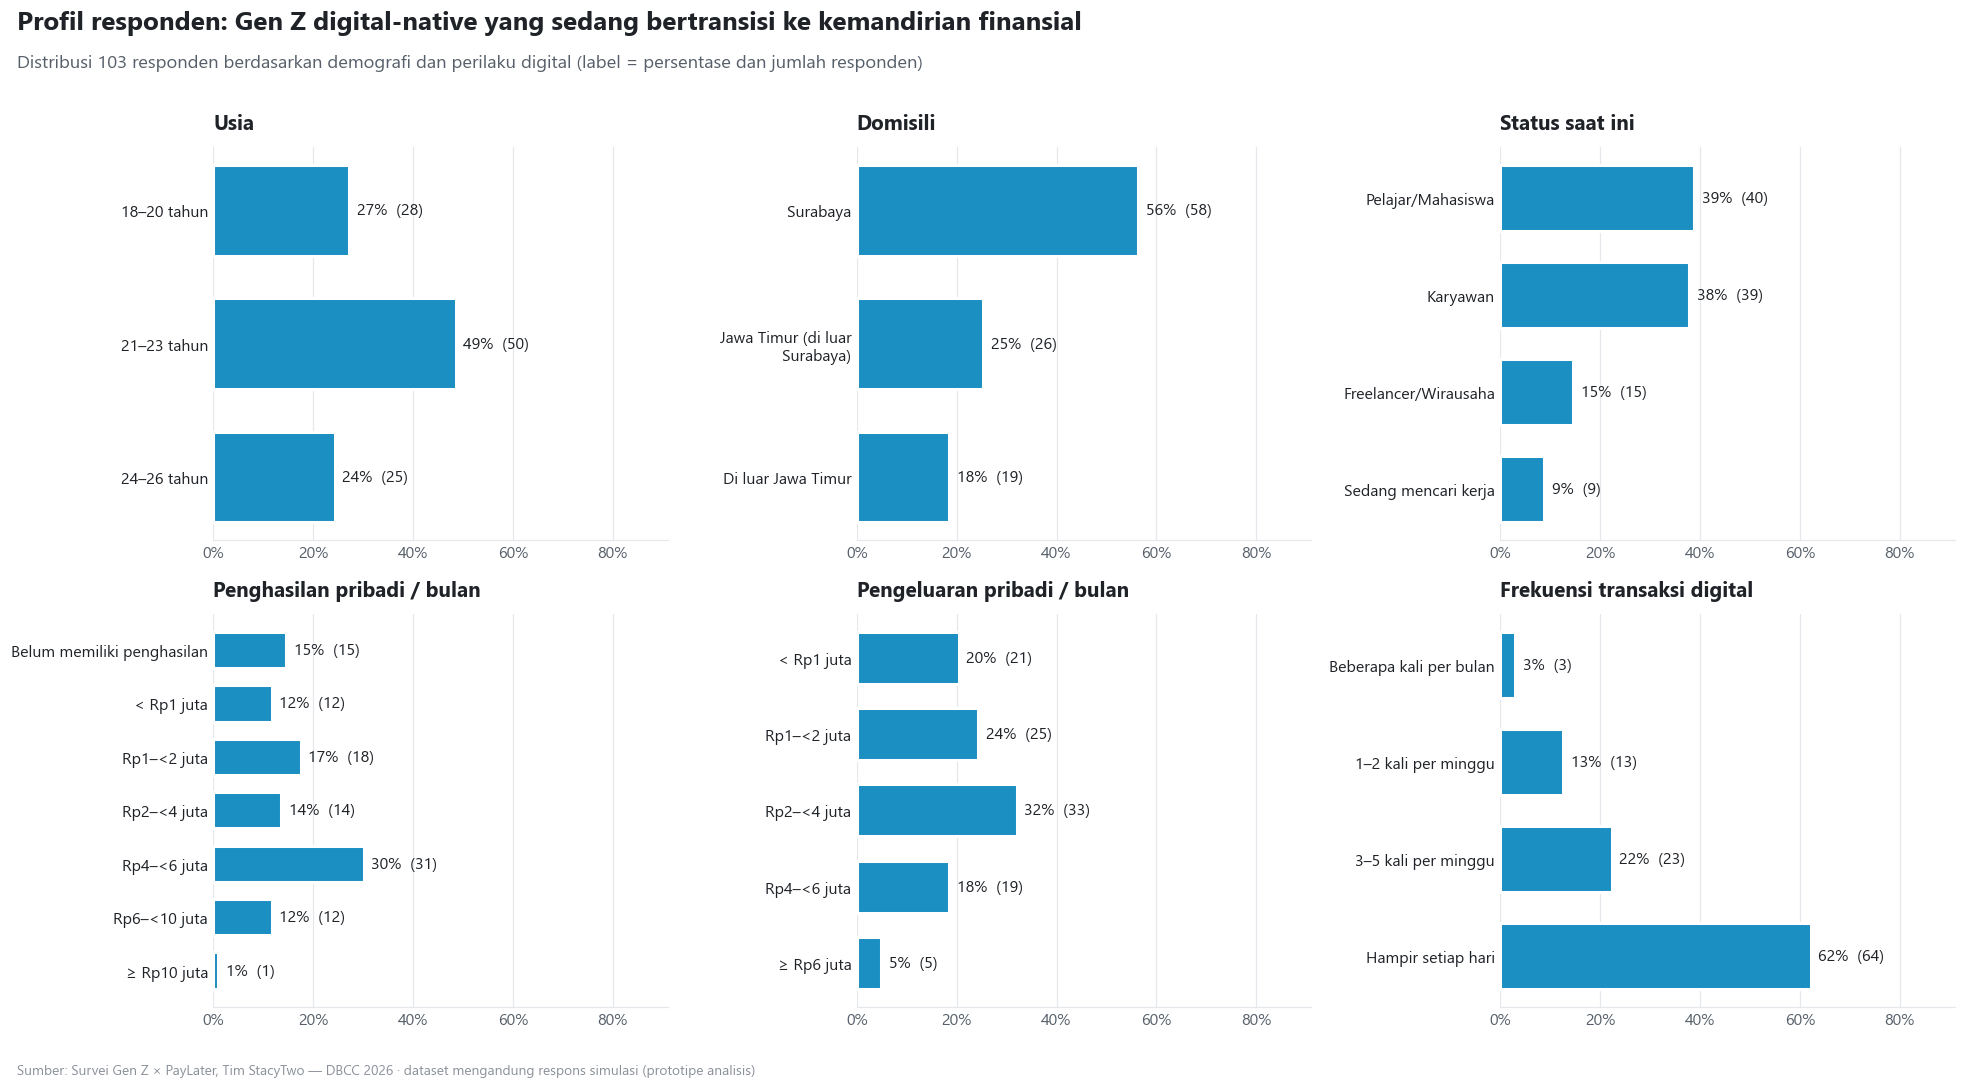

In [7]:
panel = [('usia', 'Usia'), ('domisili', 'Domisili'), ('status', 'Status saat ini'),
         ('penghasilan', 'Penghasilan pribadi / bulan'), ('pengeluaran', 'Pengeluaran pribadi / bulan'),
         ('frek_digital', 'Frekuensi transaksi digital')]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (kol, judul) in zip(axes.flat, panel):
    s = df[kol].value_counts(normalize=True).reindex(ORDER[kol]).fillna(0)
    bar_h(ax, s, n=N, urut=False, lebar=26, xmax=0.7)
    ax.set_title(judul)
bingkai(fig, 'Profil responden: Gen Z digital-native yang sedang bertransisi ke kemandirian finansial',
        f'Distribusi {N} responden berdasarkan demografi dan perilaku digital (label = persentase dan jumlah responden)')
simpan(fig, '04a_profil_responden')

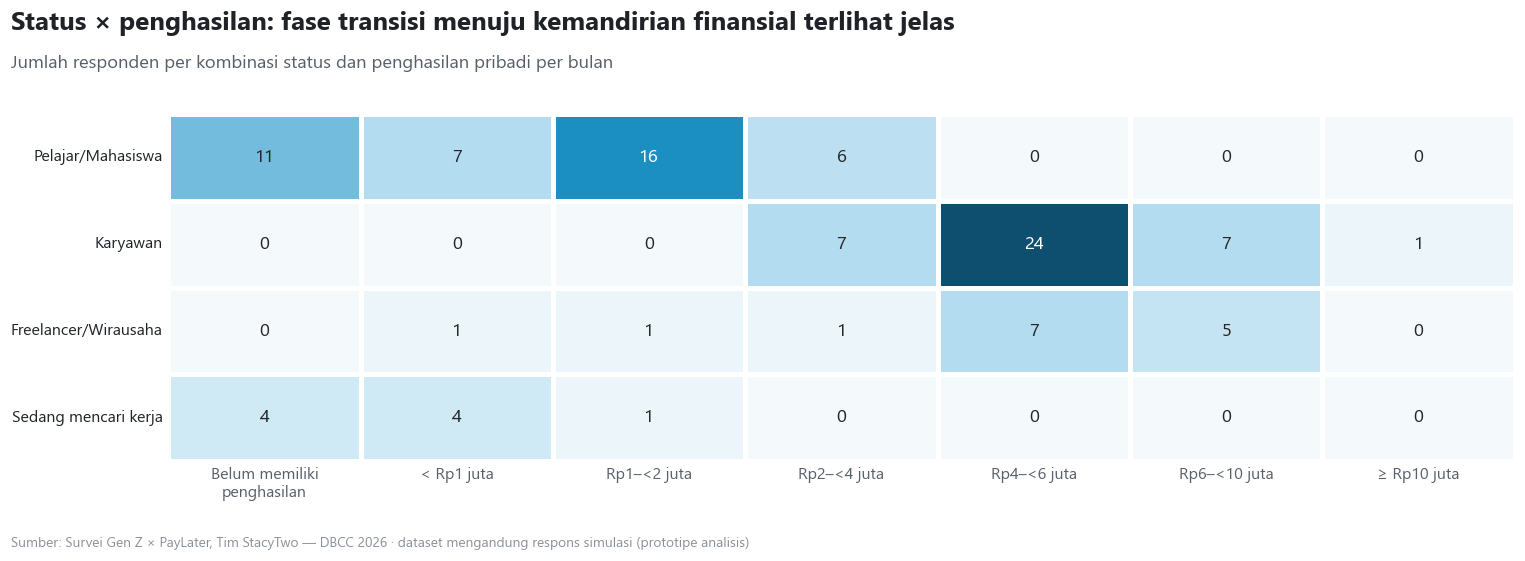

> ### 💡 Insight profil responden
>
> - Sampel **100% Gen Z** dengan kelompok usia terbesar **21–23 tahun** (49%) — sesuai persona Raka (22 tahun).
> - **56%** responden di Surabaya dan **82%** di Jawa Timur → relevan dengan fokus kota WOW Strategy.
> - **74%** sudah berpenghasilan ≥ Rp1 juta; bahkan **55%** mahasiswa sudah memiliki penghasilan ≥ Rp1 juta (magang/part-time) → segmen *'entering financial independence'* nyata ada.
> - **62%** bertransaksi digital hampir setiap hari → Gen Z sangat terbiasa dengan pembayaran digital; tantangannya bukan adopsi digital, melainkan **memenangkan pilihan brand**.

In [8]:
ct = pd.crosstab(df['status'], df['penghasilan']).reindex(index=ORDER['status'], columns=ORDER['penghasilan']).fillna(0)
fig, ax = plt.subplots(figsize=(14, 5.2))
heatmap(ax, ct, fmt='int', fs=12)
ax.set_xticklabels([wrap(t.get_text(), 14) for t in ax.get_xticklabels()], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
bingkai(fig, 'Status × penghasilan: fase transisi menuju kemandirian finansial terlihat jelas',
        'Jumlah responden per kombinasi status dan penghasilan pribadi per bulan')
simpan(fig, '04b_status_x_penghasilan')

mhs = df[df.status == 'Pelajar/Mahasiswa']
insight('Insight profil responden', [
    f"Sampel **100% Gen Z** dengan kelompok usia terbesar **{df.usia.value_counts().index[0]}** ({fpct(df.usia.value_counts(normalize=True).iloc[0])}) — sesuai persona Raka (22 tahun).",
    f"**{fpct(df.domisili.eq('Surabaya').mean())}** responden di Surabaya dan **{fpct(df.domisili.ne('Di luar Jawa Timur').mean())}** di Jawa Timur → relevan dengan fokus kota WOW Strategy.",
    f"**{fpct(df.mandiri_finansial.mean())}** sudah berpenghasilan ≥ Rp1 juta; bahkan **{fpct(mhs.mandiri_finansial.mean())}** mahasiswa sudah memiliki penghasilan ≥ Rp1 juta (magang/part-time) → segmen *'entering financial independence'* nyata ada.",
    f"**{fpct(df.frek_digital.eq('Hampir setiap hari').mean())}** bertransaksi digital hampir setiap hari → Gen Z sangat terbiasa dengan pembayaran digital; tantangannya bukan adopsi digital, melainkan **memenangkan pilihan brand**.",
])

## 5. Perilaku & Adopsi PayLater
Seberapa jauh Gen Z sudah memakai PayLater? Siapa yang aktif, siapa yang berhenti, dan siapa yang masih bisa dimenangkan? Sebagai pembanding eksternal kami memakai **Laporan Perilaku Pengguna PayLater Indonesia 2024 (Kredivo × Katadata Insight Center, n = 6.815)**: di antara non-pengguna PayLater, **50,8%** berminat menggunakan PayLater ke depannya.

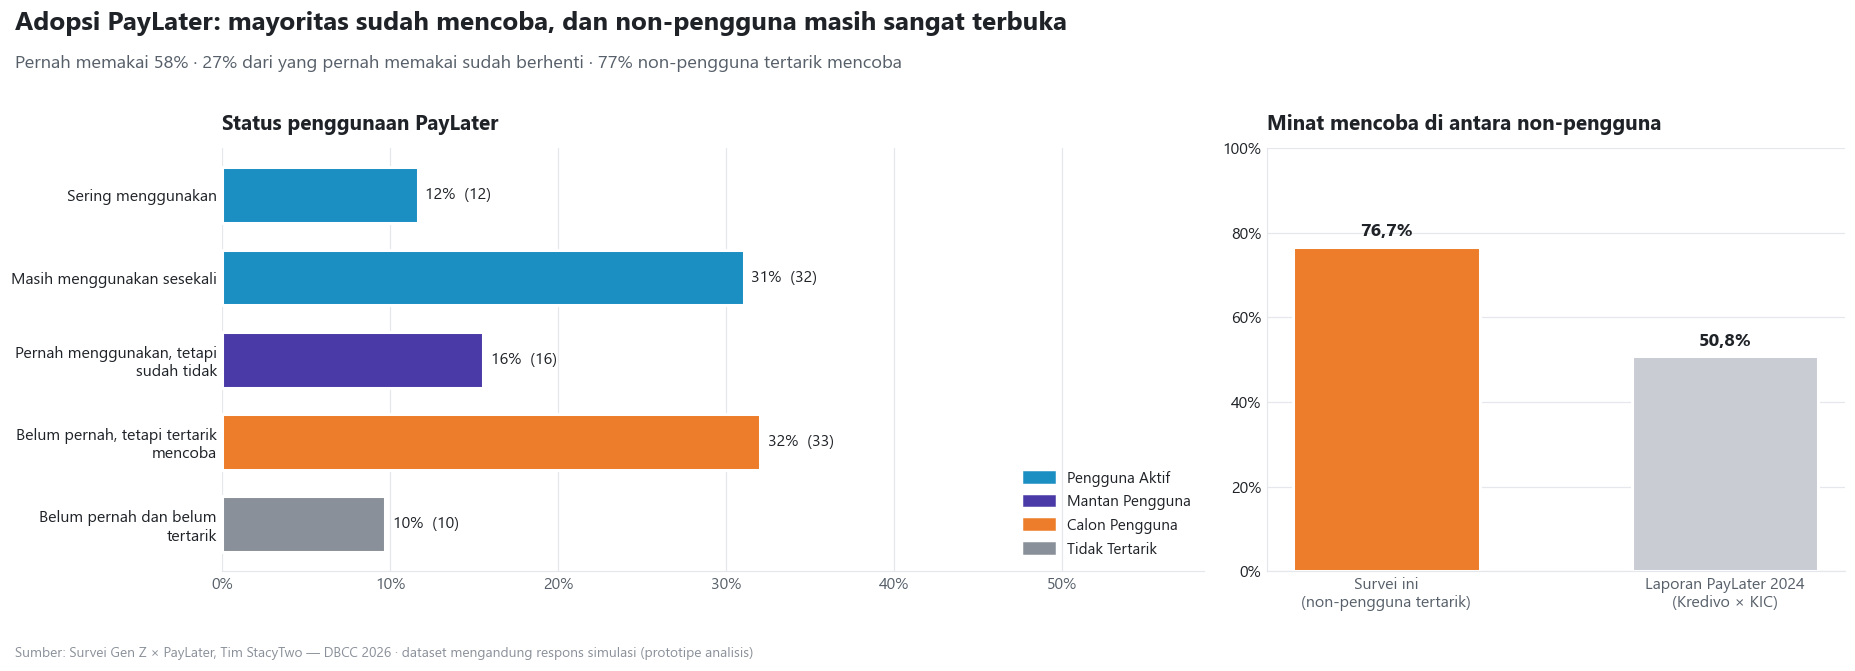

In [9]:
BENCH_MINAT_NONUSER = 0.508   # Laporan PayLater Indonesia 2024 (Kredivo × KIC), Grafik 3.6

s = df['status_paylater'].value_counts(normalize=True).reindex(ORDER['status_paylater'])
warna_status = {k: GRUP_WARNA[GRUP_MAP[k]] for k in s.index}
belum = df[~df.pernah_pakai]
pernah = df[df.pernah_pakai]
minat_nonuser = belum.grup_pengguna.eq('Calon Pengguna').mean()
churn = pernah.grup_pengguna.eq('Mantan Pengguna').mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={'width_ratios': [1.7, 1]})
bar_h(ax1, s, n=N, warna=warna_status, urut=False, lebar=30, xmax=0.45)
ax1.set_title('Status penggunaan PayLater')
ax1.legend(handles=[Patch(color=c, label=g) for g, c in GRUP_WARNA.items()], loc='lower right', fontsize=10)

bm = pd.Series({'Survei ini\n(non-pengguna tertarik)': minat_nonuser, 'Laporan PayLater 2024\n(Kredivo × KIC)': BENCH_MINAT_NONUSER})
b = ax2.bar(range(2), bm.values, color=[ORANYE, ABU], width=0.55, edgecolor='white', linewidth=2)
ax2.bar_label(b, [fpct(v, 1) for v in bm.values], padding=4, fontsize=12, fontweight='bold')
ax2.set_xticks(range(2), bm.index)
ax2.set_ylim(0, 1); ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax2, 'y')
ax2.set_title('Minat mencoba di antara non-pengguna')
bingkai(fig, 'Adopsi PayLater: mayoritas sudah mencoba, dan non-pengguna masih sangat terbuka',
        f'Pernah memakai {fpct(df.pernah_pakai.mean())} · {fpct(churn)} dari yang pernah memakai sudah berhenti · '
        f'{fpct(minat_nonuser)} non-pengguna tertarik mencoba')
simpan(fig, '05a_adopsi_paylater')

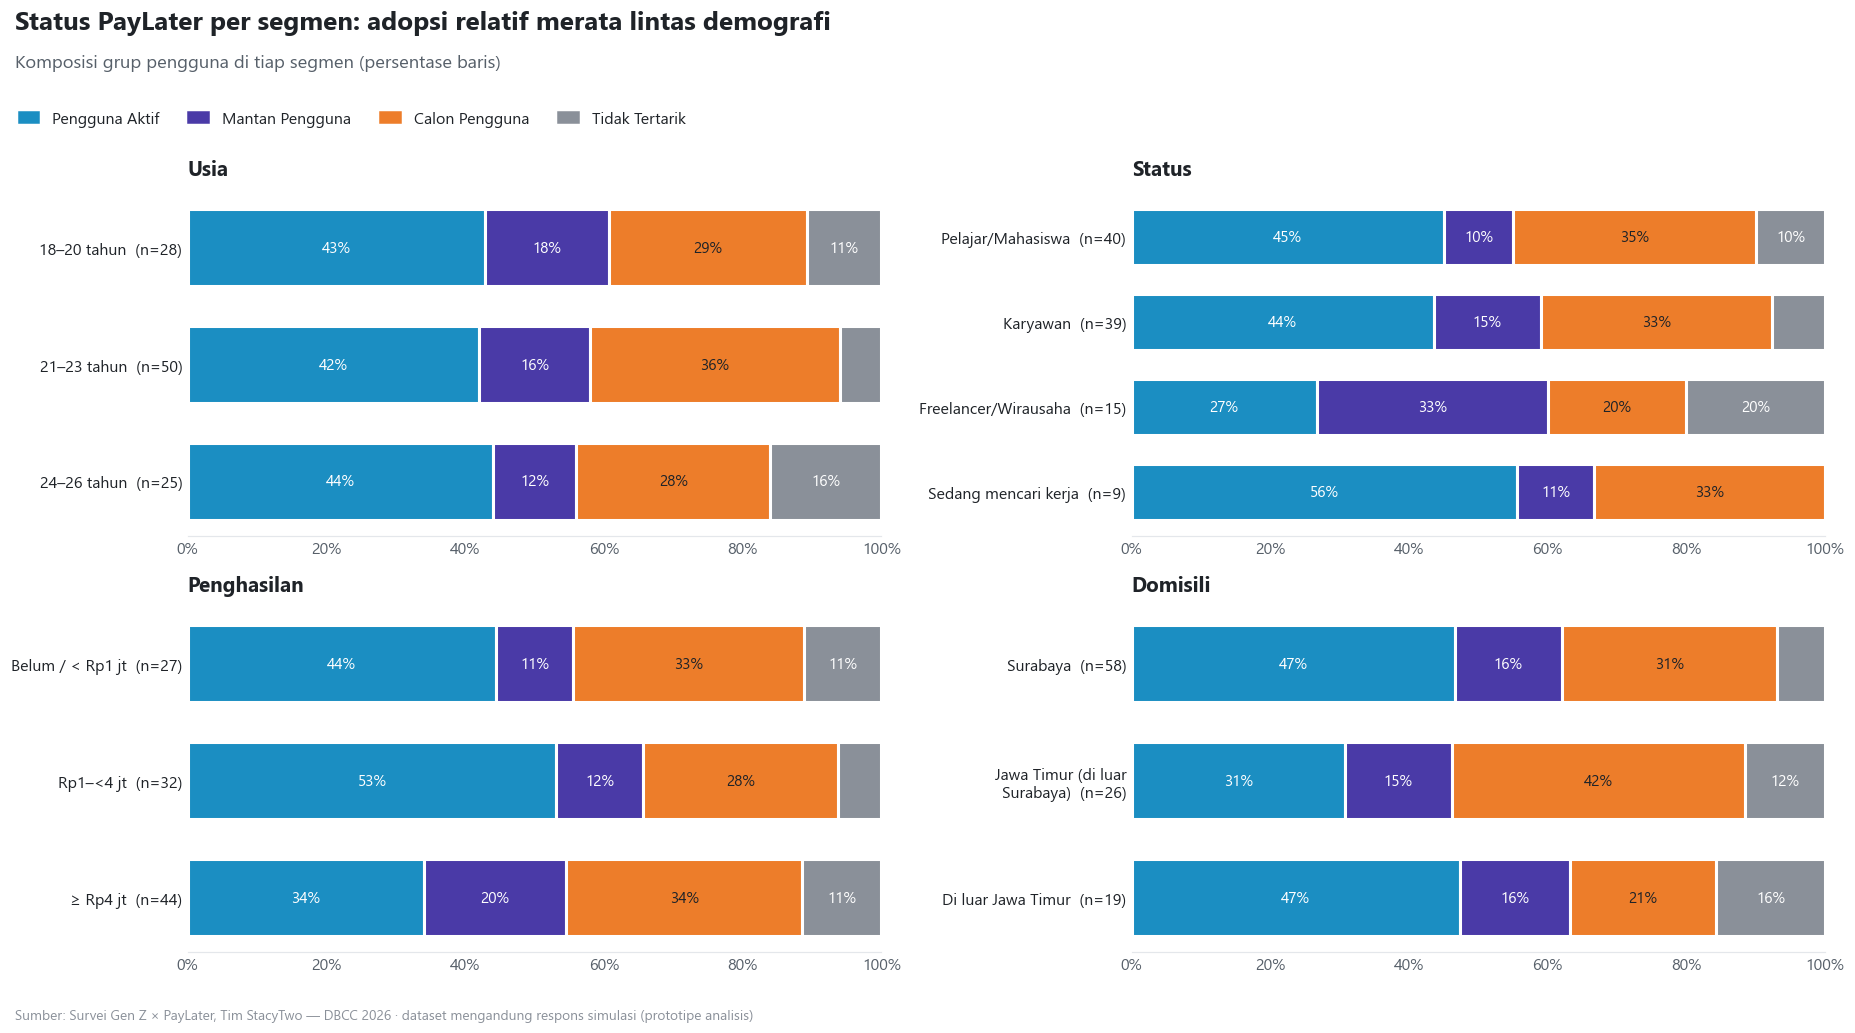

Uji Chi-square: apakah status PayLater berbeda antar segmen demografi?


,chi2,dof,p-value,Cramér's V,Min. expected,"Kesimpulan (α = 0,05)"
Usia,2.55,6.0,0.8623,0.111,2.4,Tidak berbeda signifikan
Status,8.76,9.0,0.4598,0.168,0.9,Tidak berbeda signifikan
Penghasilan,3.61,6.0,0.7293,0.132,2.6,Tidak berbeda signifikan
Domisili,4.04,6.0,0.6711,0.140,1.8,Tidak berbeda signifikan


> ### 💡 Insight adopsi PayLater
>
> - **58%** responden pernah memakai PayLater; **43%** masih aktif memakai.
> - **77%** non-pengguna tertarik mencoba — lebih tinggi dari benchmark nasional 50,8% → ada **pool 33 calon pengguna** yang siap dikonversi oleh *Winning the Market*.
> - **27%** dari yang pernah memakai PayLater sudah berhenti (16 responden) → masalah bukan hanya akuisisi, tetapi juga **retensi & repeat** — alasan **WOW Loop** dibutuhkan.
> - Uji Chi-square menunjukkan status PayLater tidak berbeda signifikan antar usia/status/penghasilan/domisili → pembeda perilaku **bukan demografi, melainkan sikap & persepsi** (trust, kejelasan biaya, relevansi). Ini mendukung strategi berbasis *mindset* ketimbang sekadar targeting demografis.

In [10]:
dims = [('Usia', 'usia'), ('Status', 'status'), ('Penghasilan', 'penghasilan_grup'), ('Domisili', 'domisili')]
fig, axes = plt.subplots(2, 2, figsize=(17, 9.5))
for ax, (judul, kol) in zip(axes.flat, dims):
    ct = pd.crosstab(df[kol], df['grup_pengguna'], normalize='index').reindex(index=ORDER[kol], columns=ORDER['grup_pengguna']).fillna(0)
    nn = df[kol].value_counts().reindex(ORDER[kol])
    ct = ct.iloc[::-1]
    kiri = np.zeros(len(ct))
    for g in ct.columns:
        ax.barh(range(len(ct)), ct[g], left=kiri, color=GRUP_WARNA[g], height=0.66, edgecolor='white', linewidth=2)
        for i, (l, w) in enumerate(zip(kiri, ct[g])):
            if w >= 0.08:
                ax.text(l + w / 2, i, fpct(w), ha='center', va='center', fontsize=10,
                        color='white' if g != 'Calon Pengguna' else TEKS)
        kiri += ct[g].values
    ax.set_yticks(range(len(ct)), [f'{wrap(i, 22)}  (n={nn[i]})' for i in ct.index])
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    gaya(ax, None); ax.spines['left'].set_visible(False)
    ax.set_title(judul)
bingkai(fig, 'Status PayLater per segmen: adopsi relatif merata lintas demografi',
        'Komposisi grup pengguna di tiap segmen (persentase baris)',
        legend=[Patch(color=c, label=g) for g, c in GRUP_WARNA.items()])
simpan(fig, '05b_status_paylater_per_segmen')

uji = pd.DataFrame({judul: uji_chi('grup_pengguna', kol) for judul, kol in dims}).T
uji['Kesimpulan (α = 0,05)'] = np.where(uji['p-value'] < 0.05, 'Berbeda signifikan', 'Tidak berbeda signifikan')
print('Uji Chi-square: apakah status PayLater berbeda antar segmen demografi?')
display(uji)

insight('Insight adopsi PayLater', [
    f"**{fpct(df.pernah_pakai.mean())}** responden pernah memakai PayLater; **{fpct(df.grup_pengguna.eq('Pengguna Aktif').mean())}** masih aktif memakai.",
    f"**{fpct(minat_nonuser)}** non-pengguna tertarik mencoba — {'lebih tinggi' if minat_nonuser > BENCH_MINAT_NONUSER else 'lebih rendah'} dari benchmark nasional {fpct(BENCH_MINAT_NONUSER, 1)} → ada **pool {df.grup_pengguna.eq('Calon Pengguna').sum()} calon pengguna** yang siap dikonversi oleh *Winning the Market*.",
    f"**{fpct(churn)}** dari yang pernah memakai PayLater sudah berhenti ({df.grup_pengguna.eq('Mantan Pengguna').sum()} responden) → masalah bukan hanya akuisisi, tetapi juga **retensi & repeat** — alasan **WOW Loop** dibutuhkan.",
    f"Uji Chi-square menunjukkan status PayLater {'tidak' if (uji['p-value'] >= 0.05).all() else 'tidak seluruhnya'} berbeda signifikan antar usia/status/penghasilan/domisili → pembeda perilaku **bukan demografi, melainkan sikap & persepsi** (trust, kejelasan biaya, relevansi). Ini mendukung strategi berbasis *mindset* ketimbang sekadar targeting demografis.",
])

## 6. Mengapa Gen Z Memakai PayLater & Untuk Apa?
Dua pertanyaan multi-pilihan (masing-masing **3 pilihan per responden**) membantu kami memahami **Jobs-to-be-Done** Gen Z dan **momen transaksi** yang menjadi dasar *Kredivo NOW* dan *Kredivo Fit*.

> Pembanding eksternal (dikutip dalam Laporan PayLater Indonesia 2024): alasan utama konsumen memakai PayLater adalah **kebutuhan mendesak (58%)**, **cicilan jangka pendek (52%)** dan **promo menarik (45%)**.

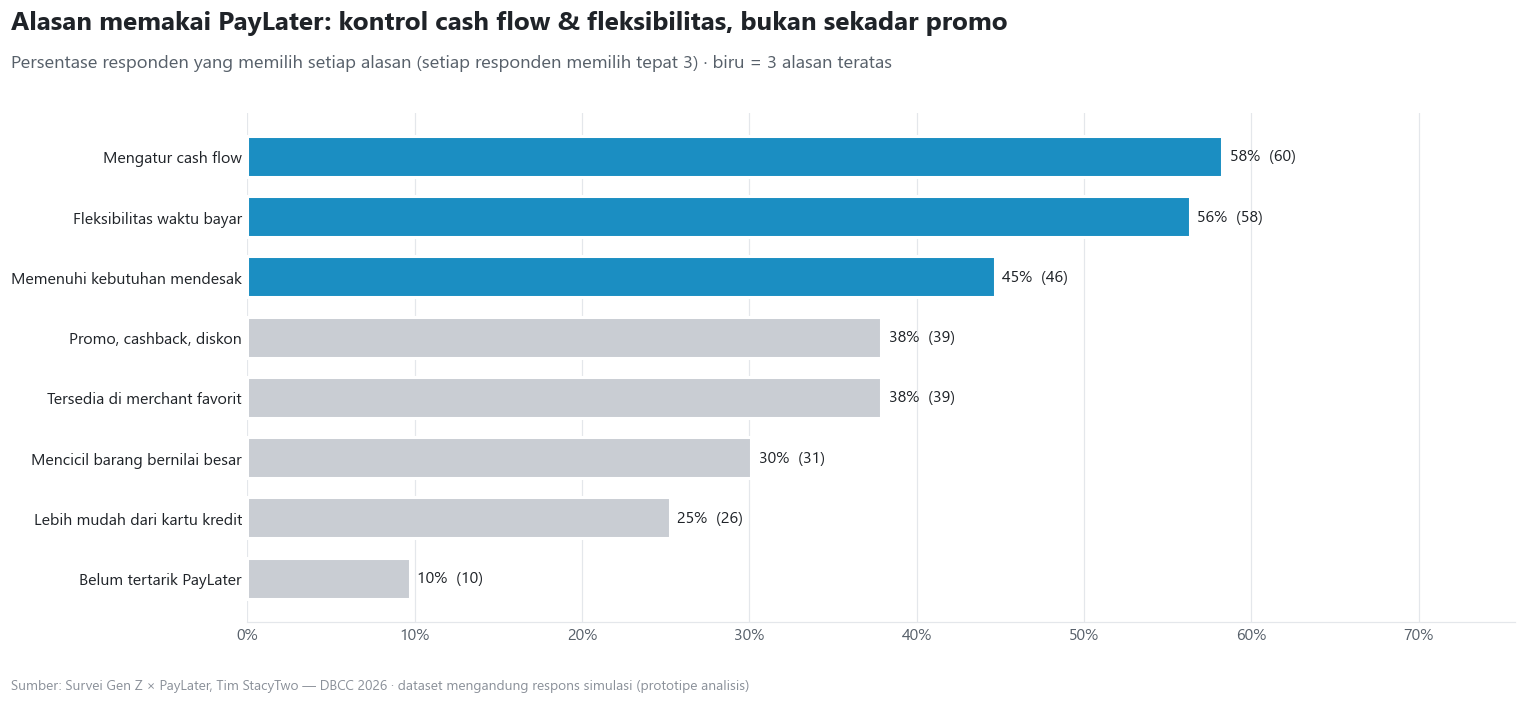

In [11]:
alasan_pct = ALASAN.mean()
top3_alasan = alasan_pct.drop('Belum tertarik PayLater').nlargest(3).index
fig, ax = plt.subplots(figsize=(14, 6.5))
bar_h(ax, alasan_pct, n=N, sorot=top3_alasan, warna_sorot=BIRU, lebar=34)
bingkai(fig, 'Alasan memakai PayLater: kontrol cash flow & fleksibilitas, bukan sekadar promo',
        'Persentase responden yang memilih setiap alasan (setiap responden memilih tepat 3) · biru = 3 alasan teratas')
simpan(fig, '06a_alasan_paylater')

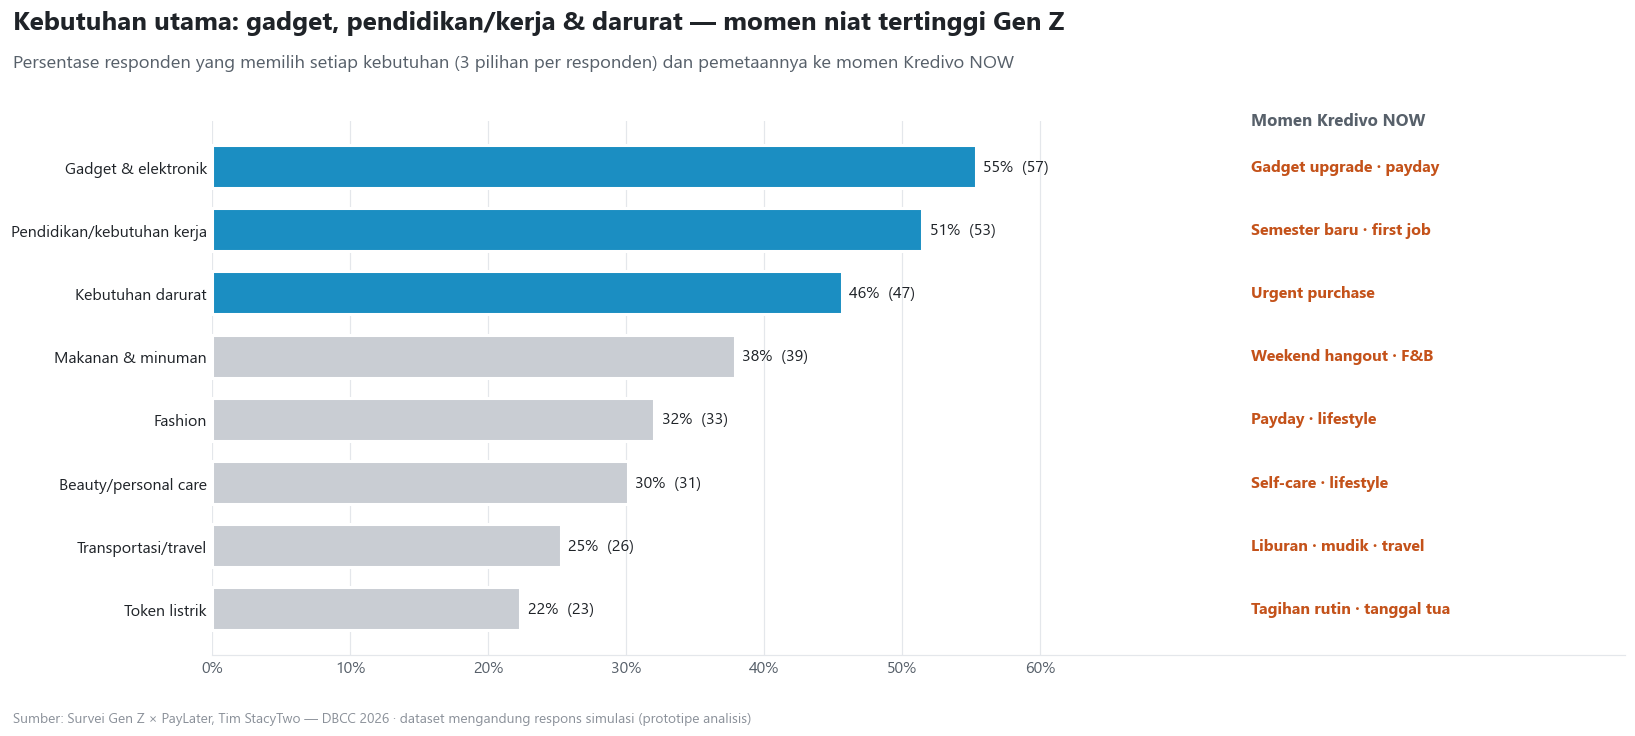

In [12]:
MOMEN_NOW = {  # kebutuhan -> momen Kredivo NOW / Kredivo Fit
    'Gadget & elektronik': 'Gadget upgrade · payday',
    'Pendidikan/kebutuhan kerja': 'Semester baru · first job',
    'Kebutuhan darurat': 'Urgent purchase',
    'Makanan & minuman': 'Weekend hangout · F&B',
    'Fashion': 'Payday · lifestyle',
    'Beauty/personal care': 'Self-care · lifestyle',
    'Transportasi/travel': 'Liburan · mudik · travel',
    'Token listrik': 'Tagihan rutin · tanggal tua',
}
keb_pct = KEBUTUHAN.mean()
fig, ax = plt.subplots(figsize=(15, 6.8))
bars = bar_h(ax, keb_pct, n=N, sorot=keb_pct.nlargest(3).index, warna_sorot=BIRU, lebar=30)
xm = keb_pct.max()
ax.set_xlim(0, xm * 1.85)
ax.set_xticks(np.arange(0, xm + 0.05, 0.1))
urut = keb_pct.sort_values()
for i, k in enumerate(urut.index):
    ax.text(xm * 1.36, i, MOMEN_NOW[k], va='center', fontsize=10.5, color=ORANYE_TUA, fontweight='bold')
ax.text(xm * 1.36, len(urut) - 0.35, 'Momen Kredivo NOW', fontsize=11, color=TEKS2, fontweight='bold')
bingkai(fig, 'Kebutuhan utama: gadget, pendidikan/kerja & darurat — momen niat tertinggi Gen Z',
        'Persentase responden yang memilih setiap kebutuhan (3 pilihan per responden) dan pemetaannya ke momen Kredivo NOW')
simpan(fig, '06b_kebutuhan_momen')

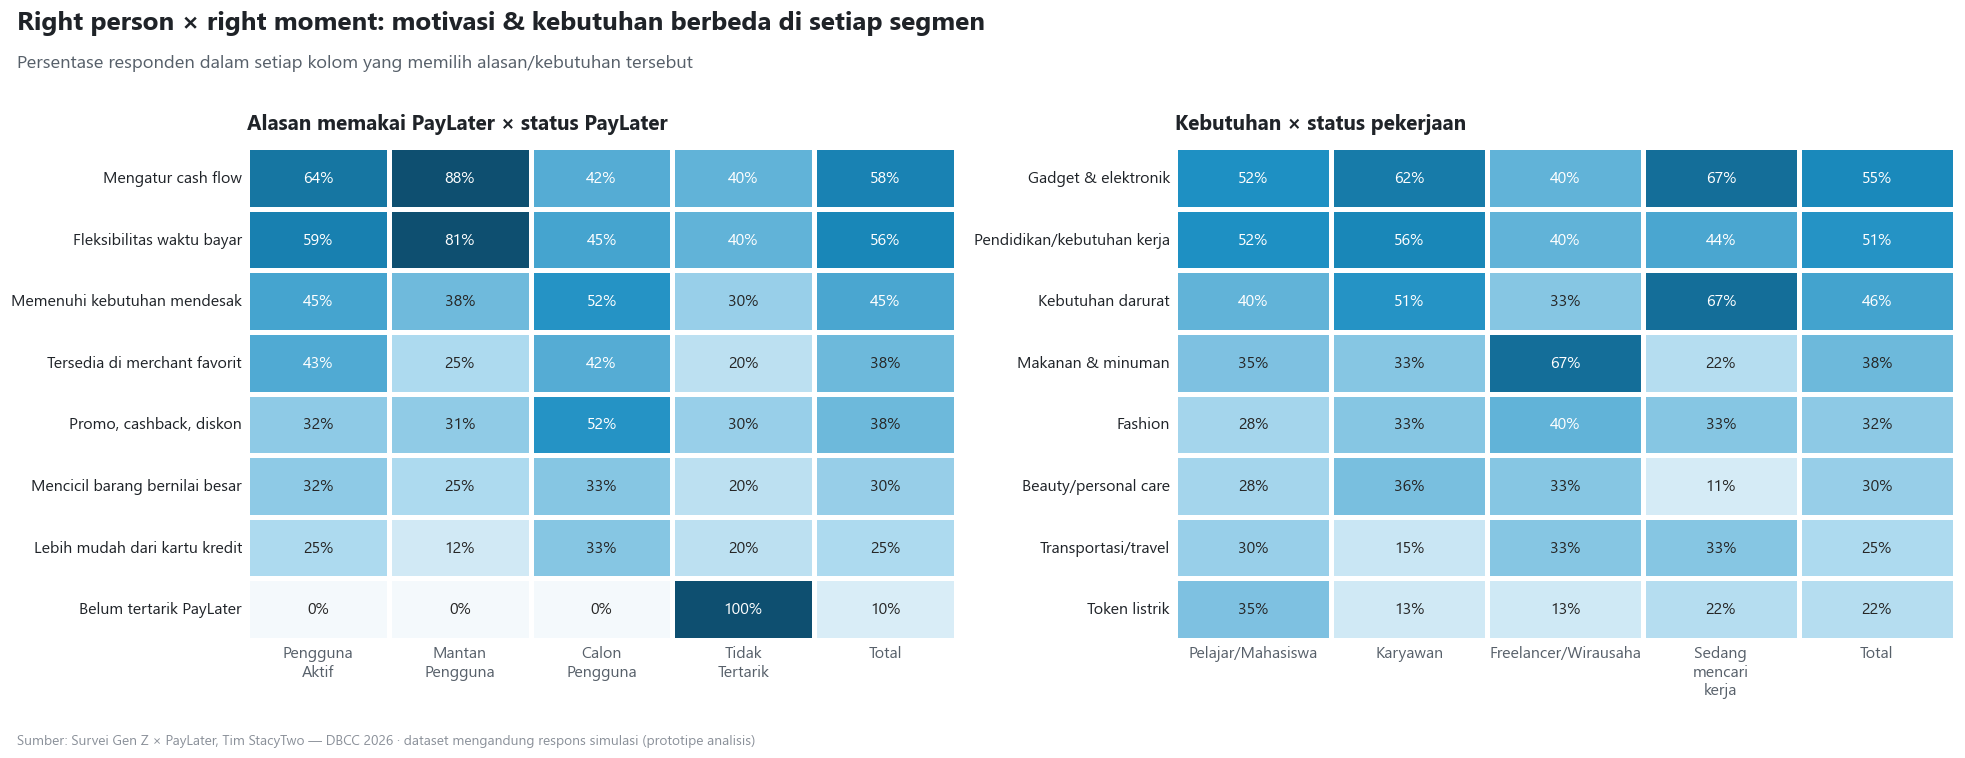

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.1]})
al = pd.concat([ALASAN, df['grup_pengguna']], axis=1).groupby('grup_pengguna').mean().T.reindex(columns=ORDER['grup_pengguna'])
al['Total'] = alasan_pct
al = al.sort_values('Total', ascending=False)
heatmap(ax1, al, vmin=0, vmax=0.8)
ax1.set_xticklabels([wrap(t.get_text(), 12) for t in ax1.get_xticklabels()], rotation=0)
ax1.set_title('Alasan memakai PayLater × status PayLater')
kb = pd.concat([KEBUTUHAN, df['status']], axis=1).groupby('status').mean().T.reindex(columns=ORDER['status'])
kb['Total'] = keb_pct
kb = kb.sort_values('Total', ascending=False)
heatmap(ax2, kb, vmin=0, vmax=0.8)
ax2.set_xticklabels([wrap(t.get_text(), 12) for t in ax2.get_xticklabels()], rotation=0)
ax2.set_title('Kebutuhan × status pekerjaan')
bingkai(fig, 'Right person × right moment: motivasi & kebutuhan berbeda di setiap segmen',
        'Persentase responden dalam setiap kolom yang memilih alasan/kebutuhan tersebut')
simpan(fig, '06c_alasan_kebutuhan_per_segmen')

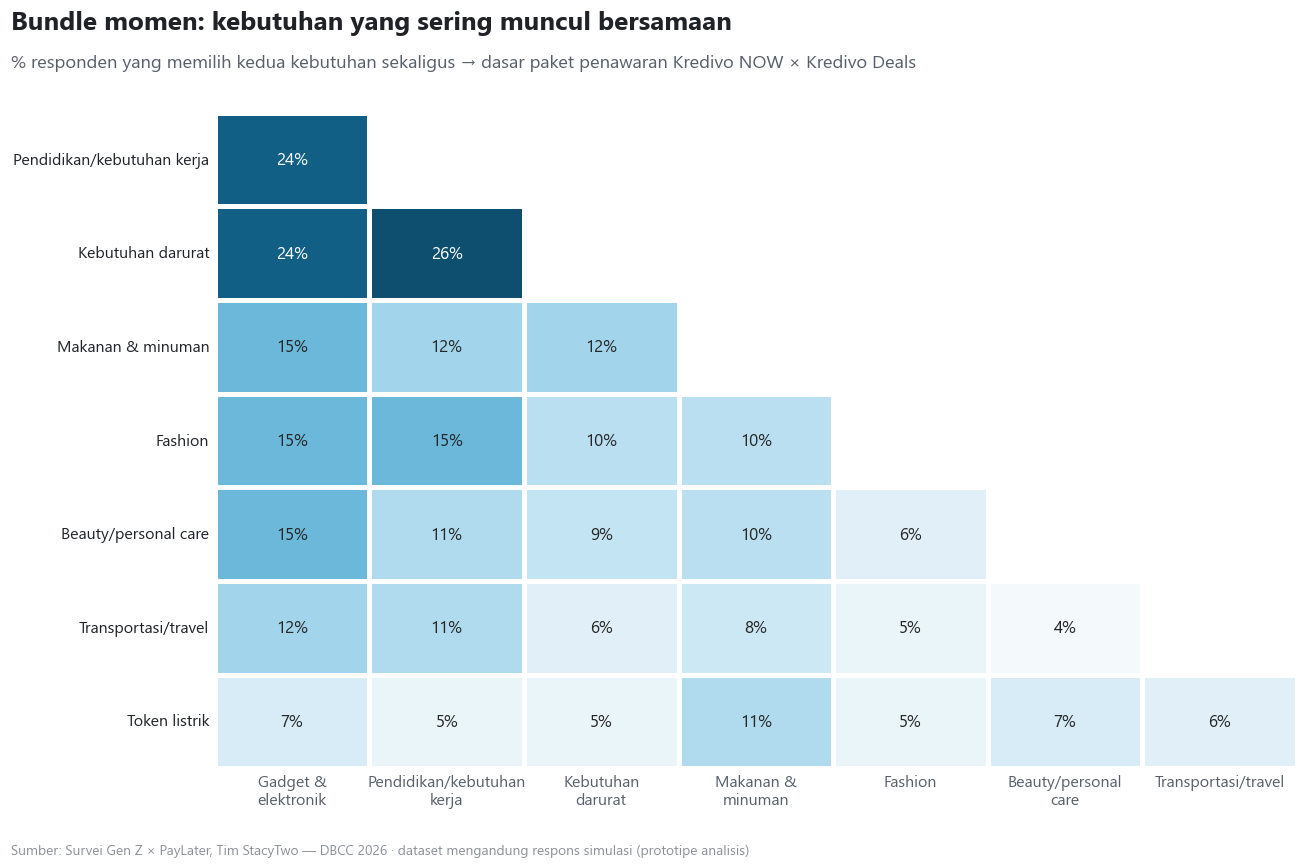

> ### 💡 Insight motivasi & momen
>
> - Tiga alasan teratas: **Mengatur cash flow (58%)**, **Fleksibilitas waktu bayar (56%)**, dan **Memenuhi kebutuhan mendesak (45%)**. Promo hanya dipilih **38%** → Gen Z memandang PayLater terutama sebagai **alat kontrol & fleksibilitas finansial**, sesuai positioning **Responsible Financial Flexibility**.
> - Kebutuhan teratas: **Gadget & elektronik (55%)**, **Pendidikan/kebutuhan kerja (51%)**, **Kebutuhan darurat (46%)** → konten & penawaran Kredivo NOW sebaiknya diprioritaskan pada momen *gadget upgrade*, *semester/first job* dan *urgent purchase*.
> - Bundle kebutuhan paling sering: **Kebutuhan darurat + Pendidikan/kebutuhan kerja** (26%); **Pendidikan/kebutuhan kerja + Gadget & elektronik** (24%); **Kebutuhan darurat + Gadget & elektronik** (24%) → peluang merancang *moment bundle* di Kredivo Deals.
> - Motivasi dan kebutuhan **berbeda antar segmen** (heatmap) → personalisasi pesan dan penawaran per segmen adalah inti prinsip *Right Person × Right Moment × Right Merchant × Right Offer*.

In [14]:
pair = pd.DataFrame(0.0, index=OPSI_KEBUTUHAN, columns=OPSI_KEBUTUHAN)
for l in df['kebutuhan']:
    for a, b in combinations(sorted(l), 2):
        pair.loc[a, b] += 1; pair.loc[b, a] += 1
pair = pair / N
urutan = keb_pct.sort_values(ascending=False).index
pair = pair.loc[urutan, urutan]
mask = np.triu(np.ones_like(pair, bool))
tampil = pair.iloc[1:, :-1]
fig, ax = plt.subplots(figsize=(12, 8))
annot = tampil.map(fpct)
sns.heatmap(tampil, mask=mask[1:, :-1], cmap=CMAP_SEQ, annot=annot, fmt='', linewidths=2, linecolor='white', cbar=False,
            ax=ax, annot_kws={'fontsize': 11})
ax.set_xticklabels([wrap(t.get_text(), 12) for t in ax.get_xticklabels()], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.tick_params(length=0)
bingkai(fig, 'Bundle momen: kebutuhan yang sering muncul bersamaan',
        '% responden yang memilih kedua kebutuhan sekaligus → dasar paket penawaran Kredivo NOW × Kredivo Deals')
simpan(fig, '06d_bundle_kebutuhan')

top_pair = pair.where(~mask).stack().sort_values(ascending=False).head(3)
insight('Insight motivasi & momen', [
    f"Tiga alasan teratas: **{top3_alasan[0]} ({fpct(alasan_pct[top3_alasan[0]])})**, **{top3_alasan[1]} ({fpct(alasan_pct[top3_alasan[1]])})**, dan **{top3_alasan[2]} ({fpct(alasan_pct[top3_alasan[2]])})**. Promo hanya dipilih **{fpct(alasan_pct['Promo, cashback, diskon'])}** → Gen Z memandang PayLater terutama sebagai **alat kontrol & fleksibilitas finansial**, sesuai positioning **Responsible Financial Flexibility**.",
    f"Kebutuhan teratas: **{urutan[0]} ({fpct(keb_pct[urutan[0]])})**, **{urutan[1]} ({fpct(keb_pct[urutan[1]])})**, **{urutan[2]} ({fpct(keb_pct[urutan[2]])})** → konten & penawaran Kredivo NOW sebaiknya diprioritaskan pada momen *gadget upgrade*, *semester/first job* dan *urgent purchase*.",
    'Bundle kebutuhan paling sering: ' + '; '.join(f"**{a} + {b}** ({fpct(v)})" for (a, b), v in top_pair.items()) + ' → peluang merancang *moment bundle* di Kredivo Deals.',
    'Motivasi dan kebutuhan **berbeda antar segmen** (heatmap) → personalisasi pesan dan penawaran per segmen adalah inti prinsip *Right Person × Right Moment × Right Merchant × Right Offer*.',
])

## 7. Decision Drivers — Apa yang Menentukan Pilihan PayLater Gen Z?
Dua belas pernyataan sikap mengukur **enam decision driver** dari master context: *Convenience, Accessibility, Trust & Security, Social Influence, Promotion & Value, Financial Control* — ditambah *Brand Salience* (konten & kehadiran fisik) dan *Relevansi kebutuhan*.

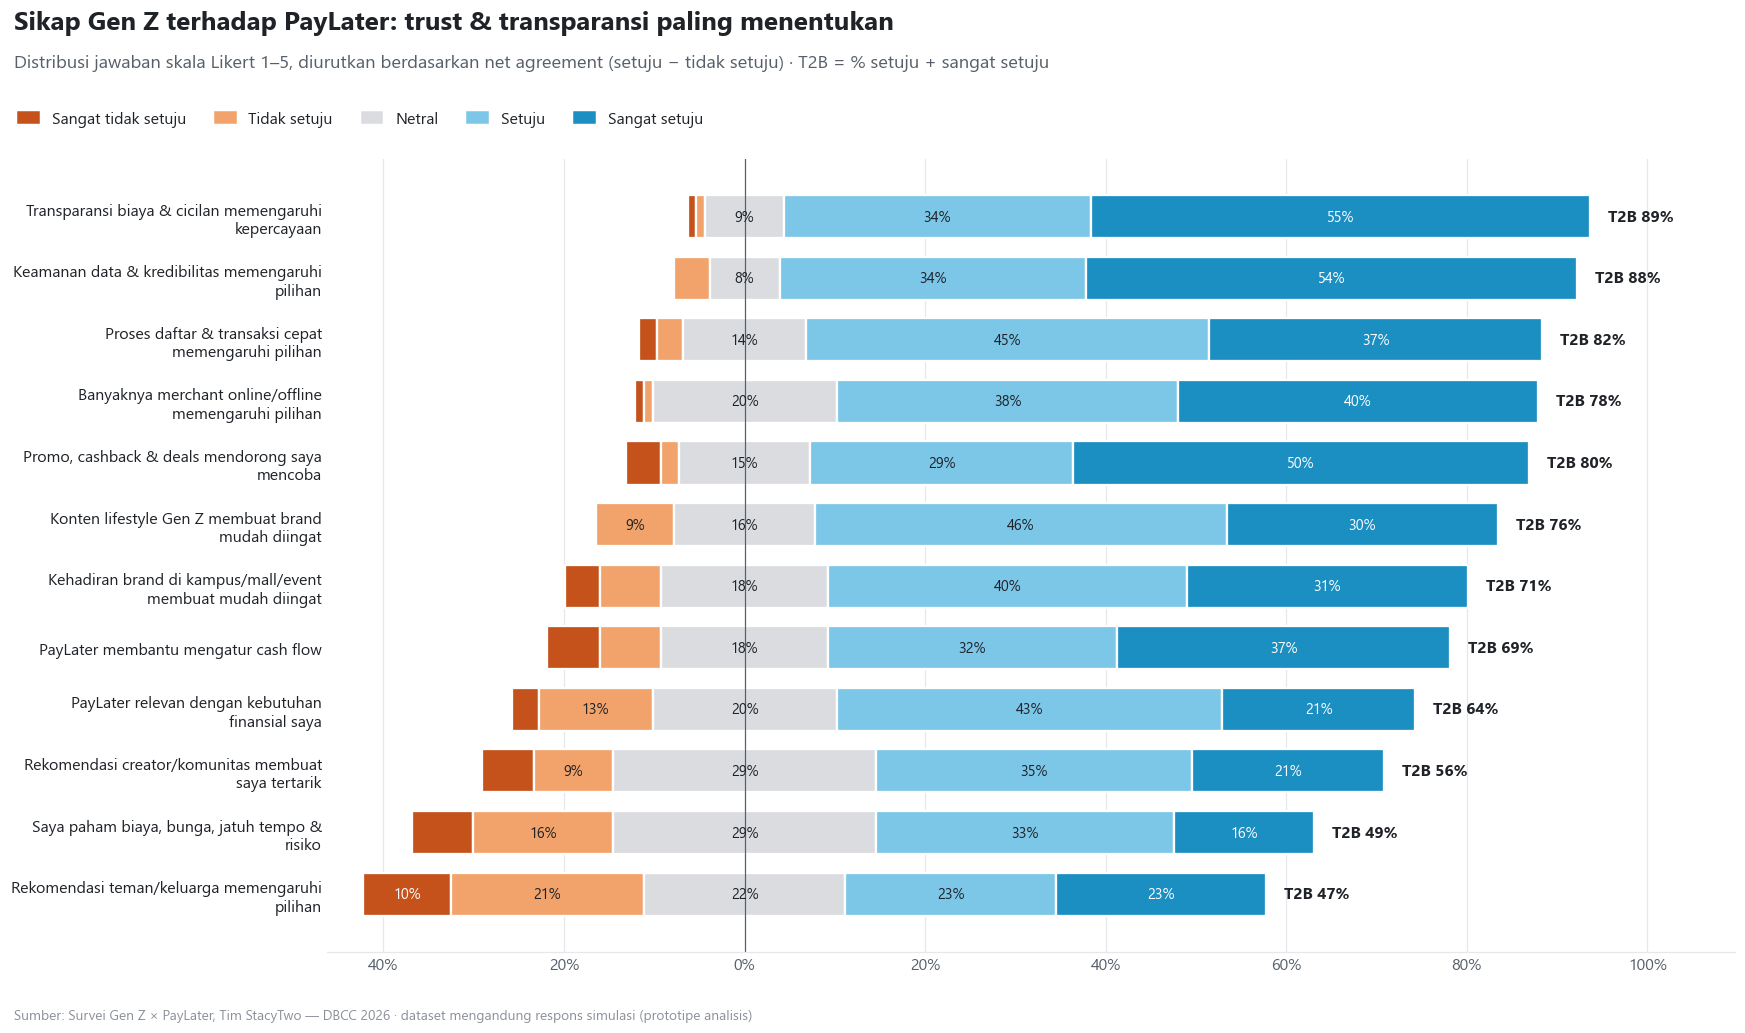

In [15]:
fig, ax = plt.subplots(figsize=(16, 9.5))
dist_sikap, handles = likert_diverging(ax, {LABEL[c]: df[c] for c in LIKERT_SIKAP}, lebar=40)
bingkai(fig, 'Sikap Gen Z terhadap PayLater: trust & transparansi paling menentukan',
        'Distribusi jawaban skala Likert 1–5, diurutkan berdasarkan net agreement (setuju − tidak setuju) · T2B = % setuju + sangat setuju',
        legend=handles)
simpan(fig, '07a_likert_sikap_paylater')

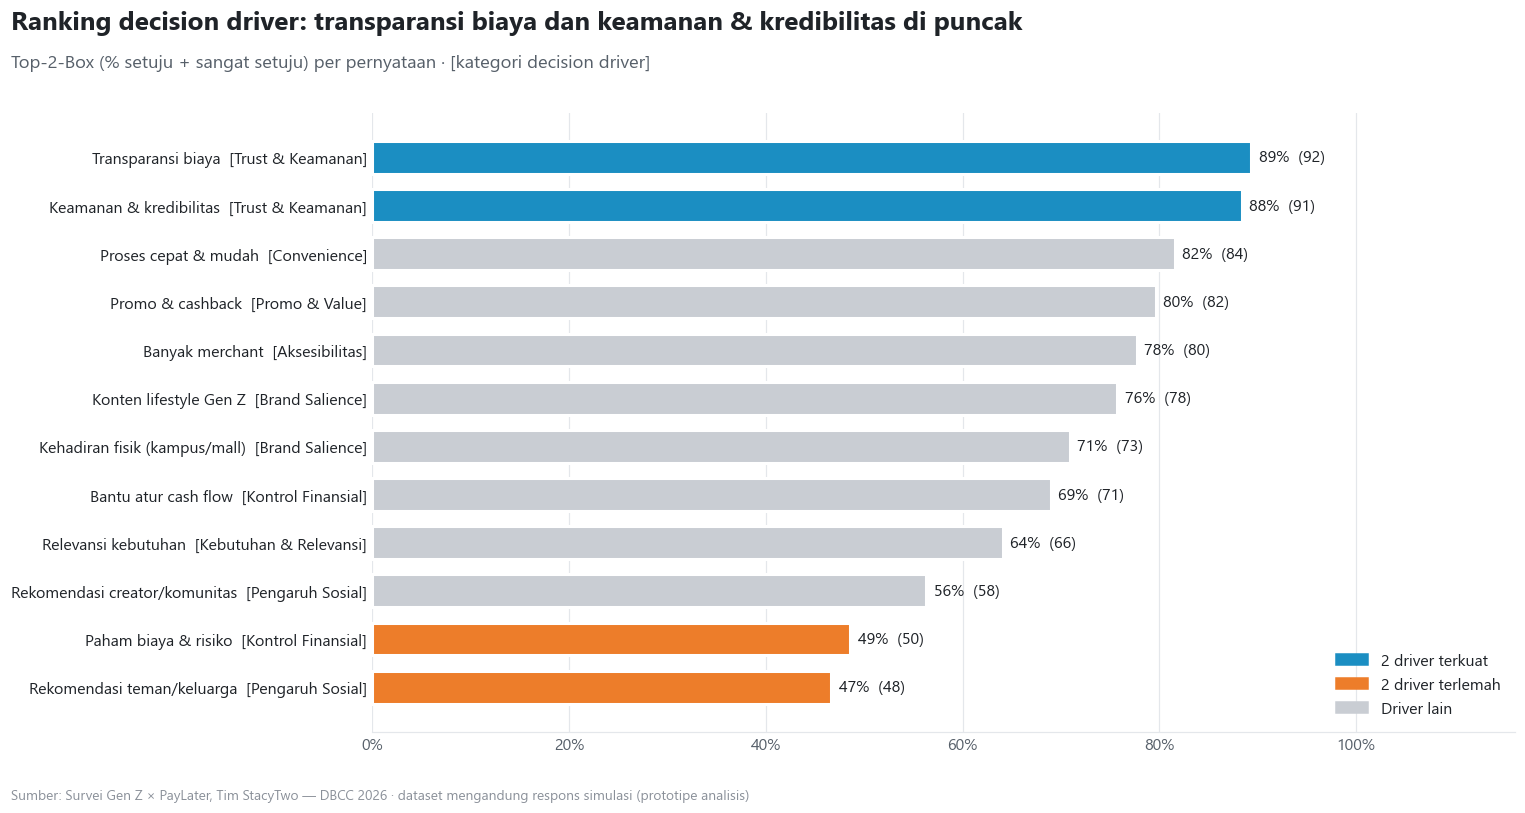

In [16]:
drv = pd.Series({c: T2B[c] for c in LIKERT_SIKAP})
drv_lbl = pd.Series({f"{LABEL_PENDEK[c]}  [{DRIVER_GRUP[c]}]": v for c, v in drv.items()})
top2 = drv.nlargest(2).index; bot2 = drv.nsmallest(2).index
warna = {f"{LABEL_PENDEK[c]}  [{DRIVER_GRUP[c]}]": (BIRU if c in top2 else ORANYE if c in bot2 else ABU) for c in LIKERT_SIKAP}
fig, ax = plt.subplots(figsize=(14, 7.5))
bar_h(ax, drv_lbl, n=N, warna=warna, lebar=60)
ax.legend(handles=[Patch(color=BIRU, label='2 driver terkuat'), Patch(color=ORANYE, label='2 driver terlemah'),
                   Patch(color=ABU, label='Driver lain')], loc='lower right')
bingkai(fig, f'Ranking decision driver: {LABEL_PENDEK[top2[0]].lower()} dan {LABEL_PENDEK[top2[1]].lower()} di puncak',
        'Top-2-Box (% setuju + sangat setuju) per pernyataan · [kategori decision driver]')
simpan(fig, '07b_ranking_driver')

### 7.1 Clarity Gap — "Saya butuh transparansi, tapi saya belum paham"
Ini adalah salah satu temuan paling penting untuk **Owning the Preference**. Kami membandingkan dua hal di setiap segmen:
- **Pentingnya transparansi** biaya, bunga & cicilan terhadap kepercayaan (`transparan`), dan
- **Pemahaman aktual** tentang biaya, bunga, jatuh tempo & risiko (`paham`).

Selisih keduanya = **Clarity Gap** → ruang yang diisi oleh **Kredivo Smart Choice** (decision-support: simulasi tenor, cicilan per bulan, total biaya).

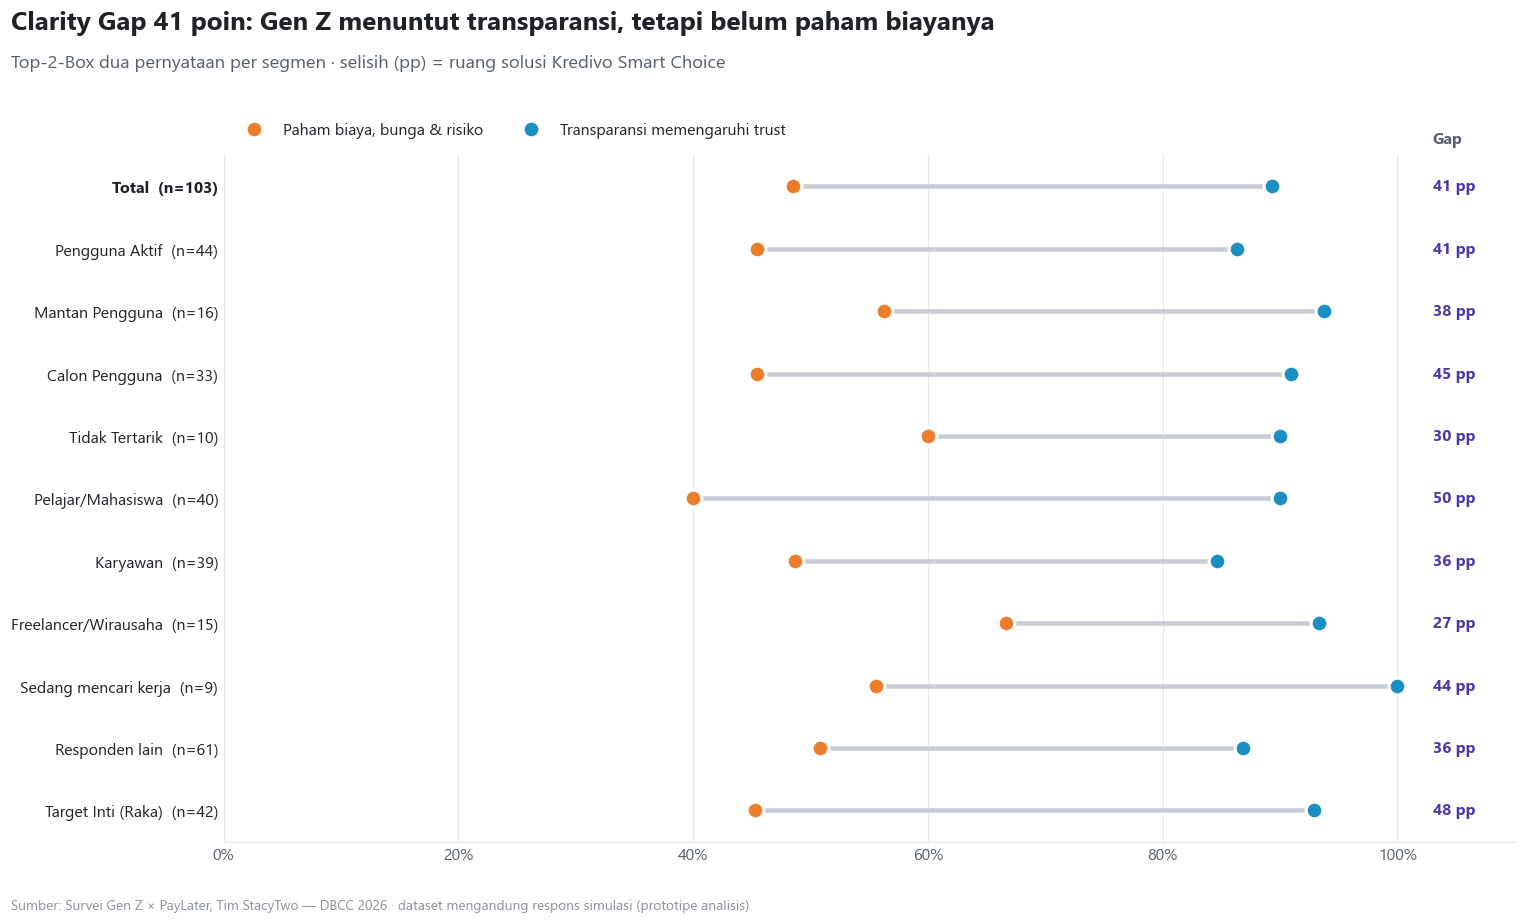

In [17]:
baris = [('Total', df)]
for judul, kol in [('Status PayLater', 'grup_pengguna'), ('Status', 'status'), ('Segmen', 'segmen_target')]:
    urutan_kol = ORDER.get(kol, sorted(df[kol].unique()))
    for lvl in urutan_kol:
        baris.append((f'{lvl}', df[df[kol] == lvl]))
cg = pd.DataFrame([{'segmen': f'{nm}  (n={len(d)})', 'penting': d.transparan_t2b.mean(), 'paham': d.paham_t2b.mean()}
                   for nm, d in baris]).iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(14, 8.5))
for i, r in cg.iterrows():
    ax.plot([r.paham, r.penting], [i, i], color=ABU, linewidth=3, zorder=1)
    ax.text(1.03, i, f'{(r.penting - r.paham) * 100:.0f} pp', va='center', fontsize=10.5, fontweight='bold', color=UNGU)
ax.scatter(cg.paham, cg.index, s=120, color=ORANYE, zorder=3, edgecolor='white', linewidth=2, label='Paham biaya, bunga & risiko')
ax.scatter(cg.penting, cg.index, s=120, color=BIRU, zorder=3, edgecolor='white', linewidth=2, label='Transparansi memengaruhi trust')
ax.set_yticks(cg.index, cg.segmen)
ax.get_yticklabels()[-1].set_fontweight('bold')
ax.set_xlim(0, 1.1); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.text(1.03, len(cg) - 0.3, 'Gap', fontsize=10.5, color=TEKS2, fontweight='bold')
gaya(ax, 'x'); ax.spines['left'].set_visible(False)
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.07), ncol=2)
bingkai(fig, f'Clarity Gap {gap_clarity * 100:.0f} poin: Gen Z menuntut transparansi, tetapi belum paham biayanya',
        'Top-2-Box dua pernyataan per segmen · selisih (pp) = ruang solusi Kredivo Smart Choice')
simpan(fig, '07c_clarity_gap')

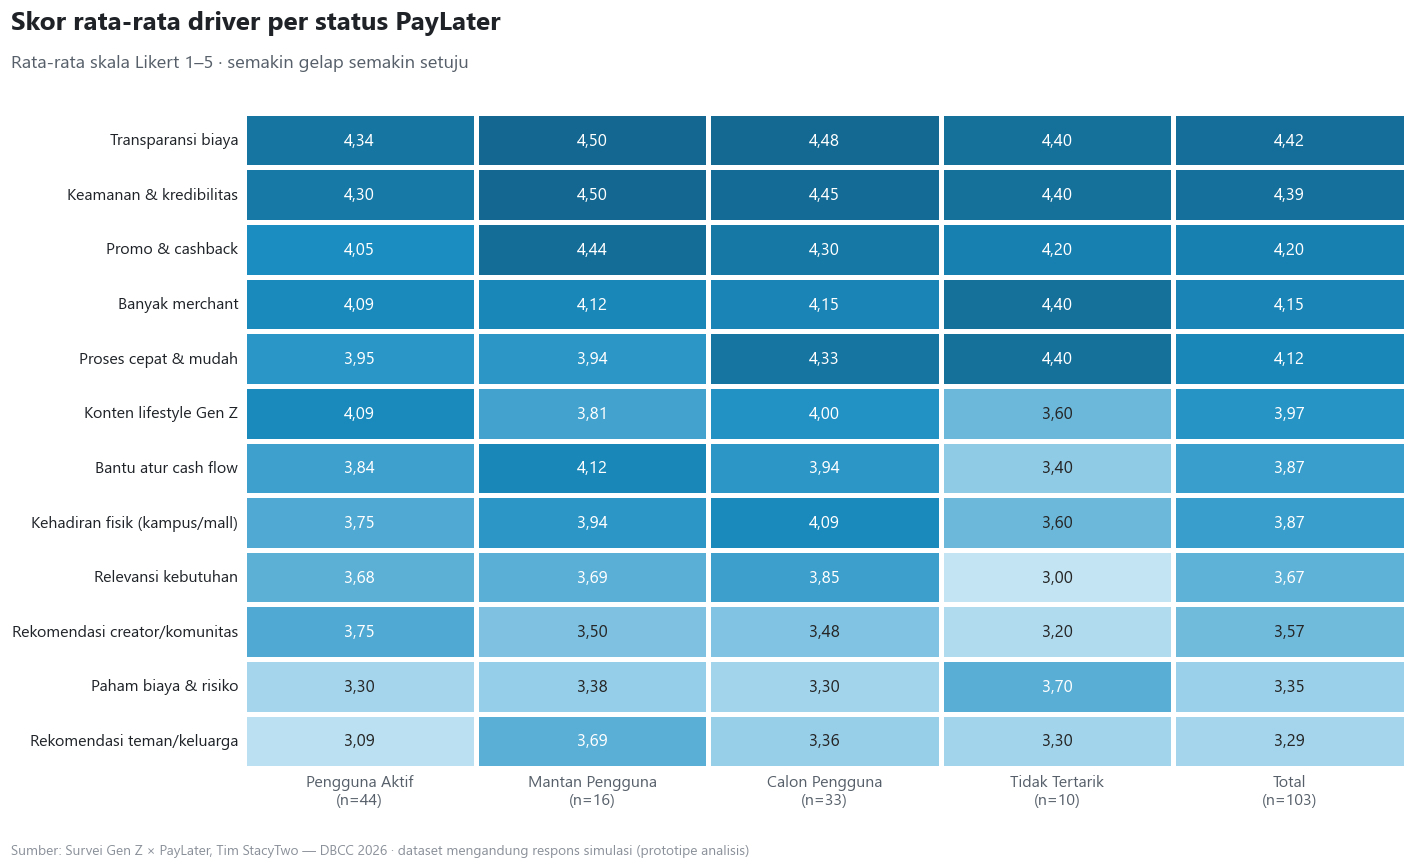

> ### 💡 Insight decision drivers
>
> - Driver terkuat: **Transparansi biaya (89%)** dan **Keamanan & kredibilitas (88%)** → **trust adalah tiket masuk**. Pesan Kredivo harus menonjolkan *transparent, secure & licensed*, bukan hanya *fast & easy*.
> - Convenience (82%), merchant (78%) dan promo (80%) juga tinggi, tetapi fitur ini dimiliki hampir semua pemain → **hygiene factor**, bukan pembeda (sesuai root cause *Low Functional Differentiation*).
> - Pengaruh sosial paling lemah: teman/keluarga **47%**, creator/komunitas **56%**. Artinya rekomendasi *saja* tidak cukup — **Kredivo Proof** perlu berbasis bukti nyata (transparansi, user stories, rating), bukan sekadar endorsement.
> - Konten lifestyle Gen Z (76%) dan kehadiran fisik di kampus/mall/event (71%) efektif membuat brand diingat → validasi langsung untuk **WOW Content** dan **Kredivo Spots**.
> - **Clarity Gap 41 pp**: 89% menilai transparansi penting, tetapi hanya 49% yang paham biaya & risiko → **Kredivo Smart Choice** menjawab kebutuhan yang belum terpenuhi ini.

In [18]:
mean_grp = df.groupby('grup_pengguna')[LIKERT_SIKAP].mean().T.reindex(columns=ORDER['grup_pengguna'])
mean_grp['Total'] = df[LIKERT_SIKAP].mean()
mean_grp = mean_grp.sort_values('Total', ascending=False)
mean_grp.index = [LABEL_PENDEK[c] for c in mean_grp.index]
fig, ax = plt.subplots(figsize=(13, 8))
heatmap(ax, mean_grp, fmt='num', vmin=2.5, vmax=4.8, fs=11)
ax.set_xticklabels([f"{t.get_text()}\n(n={(df.grup_pengguna == t.get_text()).sum() if t.get_text() != 'Total' else N})"
                    for t in ax.get_xticklabels()], rotation=0)
bingkai(fig, 'Skor rata-rata driver per status PayLater',
        'Rata-rata skala Likert 1–5 · semakin gelap semakin setuju')
simpan(fig, '07d_driver_per_grup')

insight('Insight decision drivers', [
    f"Driver terkuat: **{LABEL_PENDEK[top2[0]]} ({fpct(T2B[top2[0]])})** dan **{LABEL_PENDEK[top2[1]]} ({fpct(T2B[top2[1]])})** → **trust adalah tiket masuk**. Pesan Kredivo harus menonjolkan *transparent, secure & licensed*, bukan hanya *fast & easy*.",
    f"Convenience ({fpct(T2B['cepat'])}), merchant ({fpct(T2B['merchant'])}) dan promo ({fpct(T2B['promo'])}) juga tinggi, tetapi fitur ini dimiliki hampir semua pemain → **hygiene factor**, bukan pembeda (sesuai root cause *Low Functional Differentiation*).",
    f"Pengaruh sosial paling lemah: teman/keluarga **{fpct(T2B['teman'])}**, creator/komunitas **{fpct(T2B['creator'])}**. Artinya rekomendasi *saja* tidak cukup — **Kredivo Proof** perlu berbasis bukti nyata (transparansi, user stories, rating), bukan sekadar endorsement.",
    f"Konten lifestyle Gen Z ({fpct(T2B['konten'])}) dan kehadiran fisik di kampus/mall/event ({fpct(T2B['fisik'])}) efektif membuat brand diingat → validasi langsung untuk **WOW Content** dan **Kredivo Spots**.",
    f"**Clarity Gap {gap_clarity * 100:.0f} pp**: {fpct(T2B['transparan'])} menilai transparansi penting, tetapi hanya {fpct(T2B['paham'])} yang paham biaya & risiko → **Kredivo Smart Choice** menjawab kebutuhan yang belum terpenuhi ini.",
])

## 8. SALIENCE GAP — Dikenal, tetapi Belum Diingat Pertama
Pertanyaan terbuka *"Ketika mendengar kata PayLater, brand apa yang pertama kali terlintas?"* adalah ukuran paling jujur untuk **top-of-mind (unaided recall)**. Kami bandingkan dengan tingkat familiaritas (aided) untuk melihat seberapa besar kebocoran dari **dikenal → diingat**.

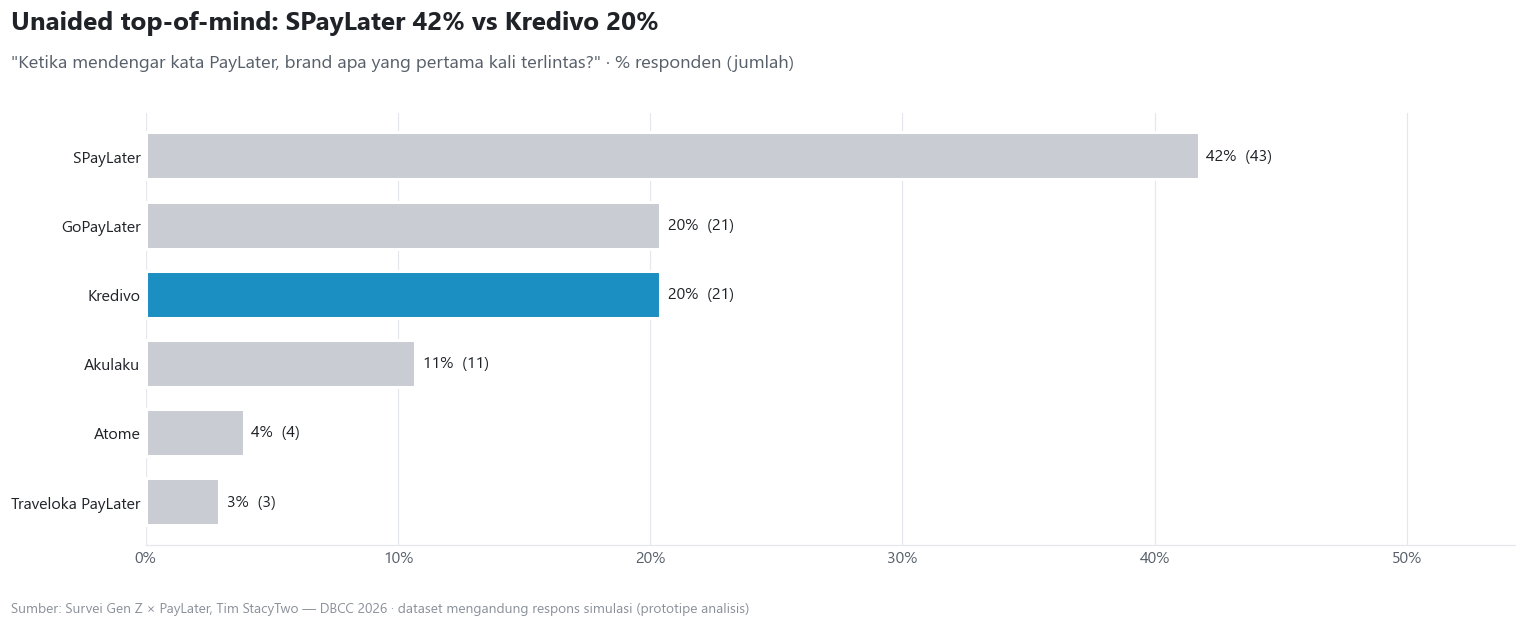

In [19]:
tom_cnt = df['tom'].value_counts()
fig, ax = plt.subplots(figsize=(14, 5.8))
bar_h(ax, tom_share, n=N, sorot='Kredivo', warna_sorot=BIRU, lebar=24)
bingkai(fig, f"Unaided top-of-mind: {pemimpin_tom} {fpct(tom_share.iloc[0])} vs Kredivo {fpct(tom_share.get('Kredivo', 0))}",
        '"Ketika mendengar kata PayLater, brand apa yang pertama kali terlintas?" · % responden (jumlah)')
simpan(fig, '08a_top_of_mind')

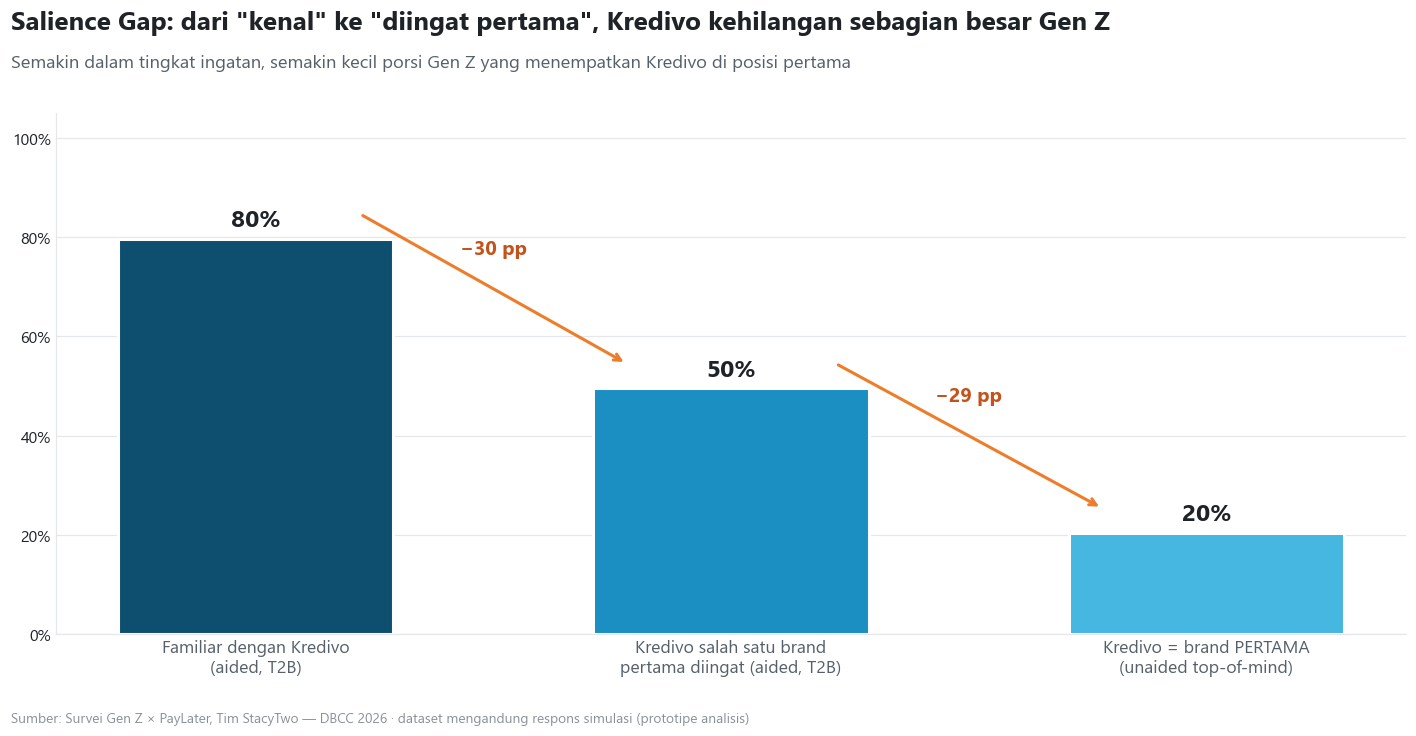

In [20]:
tangga = pd.Series({
    'Familiar dengan Kredivo\n(aided, T2B)': T2B['k_familiar'],
    'Kredivo salah satu brand\npertama diingat (aided, T2B)': T2B['k_recall'],
    'Kredivo = brand PERTAMA\n(unaided top-of-mind)': tom_share.get('Kredivo', 0),
})
fig, ax = plt.subplots(figsize=(13, 6.8))
b = ax.bar(range(3), tangga.values, color=ORDINAL3[::-1], width=0.58, edgecolor='white', linewidth=2)
ax.bar_label(b, [fpct(v) for v in tangga.values], padding=5, fontsize=16, fontweight='bold')
for i in range(2):
    turun = tangga.iloc[i + 1] - tangga.iloc[i]
    ax.annotate('', xy=(i + 0.78, tangga.iloc[i + 1] + 0.05), xytext=(i + 0.22, tangga.iloc[i] + 0.05),
                arrowprops=dict(arrowstyle='->', color=ORANYE, linewidth=2))
    ax.text(i + 0.5, (tangga.iloc[i] + tangga.iloc[i + 1]) / 2 + 0.12, f'−{abs(turun) * 100:.0f} pp', ha='center',
            fontsize=13, fontweight='bold', color=ORANYE_TUA)
ax.set_xticks(range(3), tangga.index, fontsize=11.5)
ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'y')
bingkai(fig, 'Salience Gap: dari "kenal" ke "diingat pertama", Kredivo kehilangan sebagian besar Gen Z',
        'Semakin dalam tingkat ingatan, semakin kecil porsi Gen Z yang menempatkan Kredivo di posisi pertama')
simpan(fig, '08b_salience_ladder')

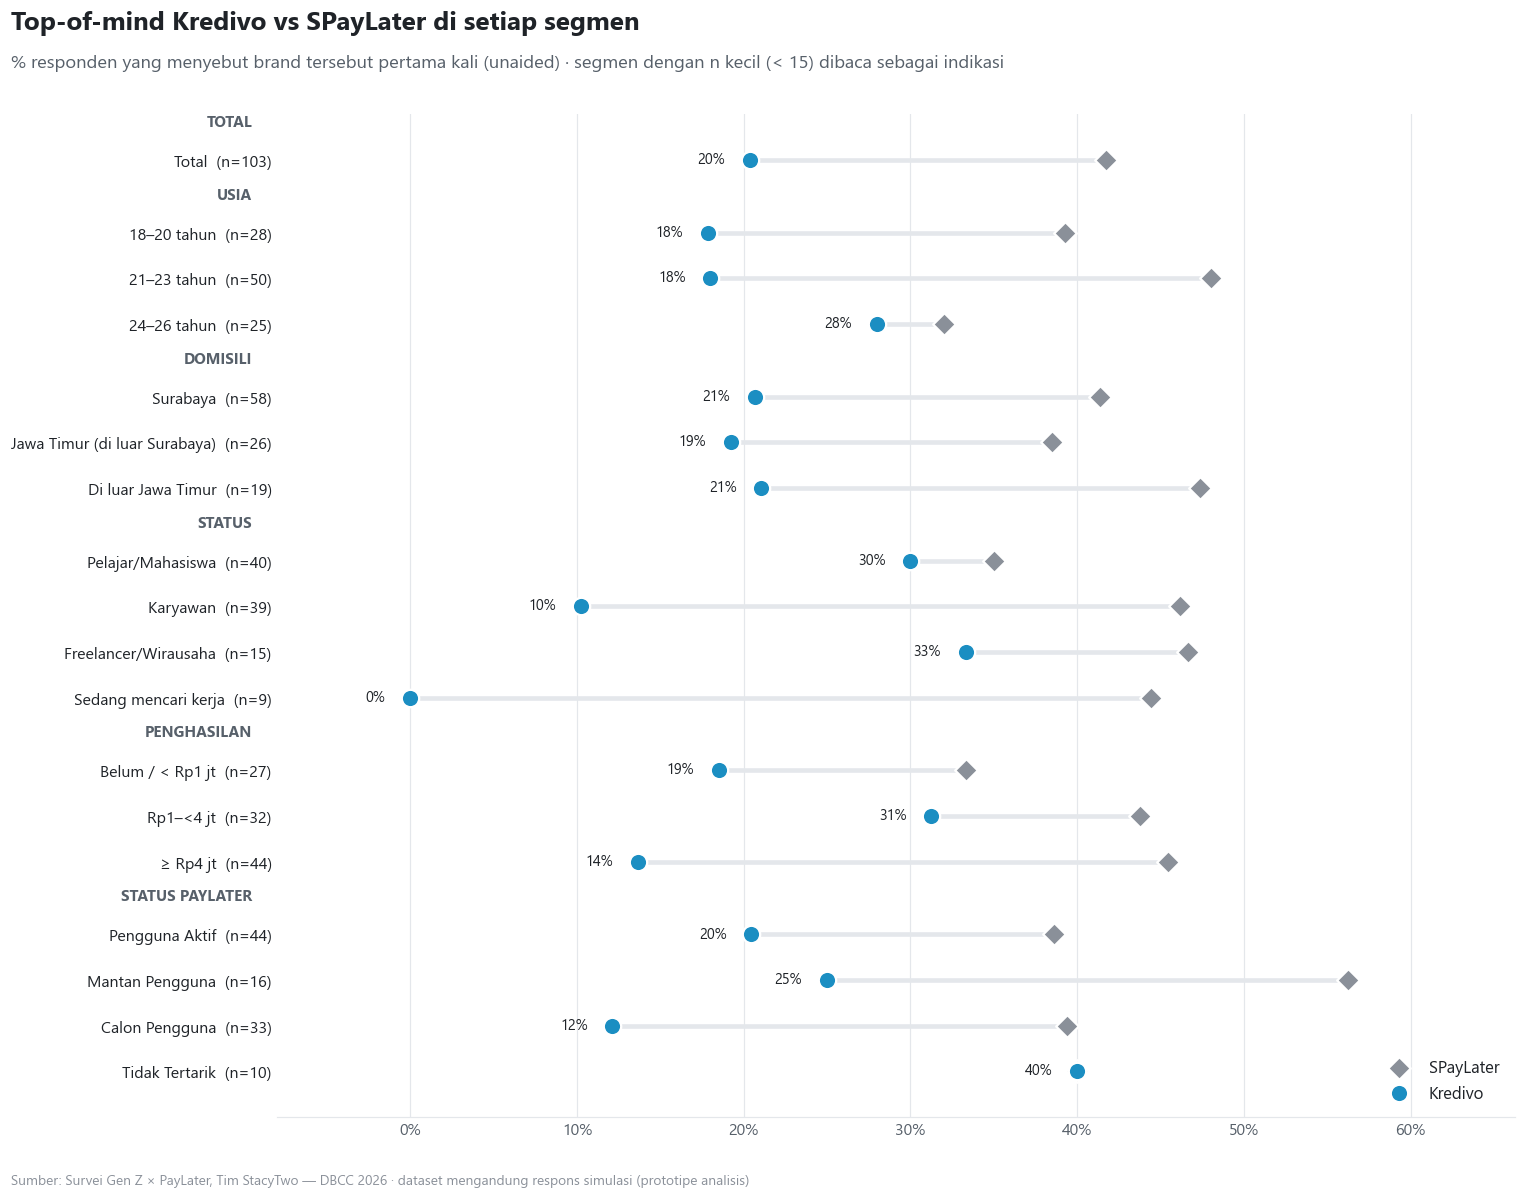

> ### 💡 Insight Salience Gap
>
> - **80%** familiar dengan Kredivo, turun menjadi **50%** yang menganggap Kredivo salah satu brand pertama, dan hanya **20%** yang benar-benar menyebut Kredivo pertama → **kebocoran 59 pp dari 'kenal' ke 'diingat pertama'**.
> - SPayLater mendominasi top-of-mind (42%), kemungkinan karena melekat pada ekosistem e-commerce/super-app yang dipakai setiap hari. Kredivo tidak punya 'rumah' ekosistem seperti itu → Kredivo perlu **distinctive brand asset** sendiri: inilah peran **WOW Content** (lagu ikonik + hero video + short-form).
> - Segmen dengan top-of-mind Kredivo **terendah**: **Karyawan** (10%, n=39), **Calon Pengguna** (12%, n=33); **tertinggi**: **Freelancer/Wirausaha** (33%), **Rp1–<4 jt** (31%).
> - Top-of-mind Kredivo di kalangan **Karyawan** hanya **10%** dan di penghasilan **≥ Rp4 jt** hanya **14%** — padahal segmen berpenghasilan inilah yang paling *monetizable* dan *eligible* kredit. Salience Gap paling tajam justru di target bisnis utama.

In [21]:
rows = [('Total', 'Total', df)]
for judul, kol in SEGMEN.items():
    for lvl in ORDER.get(kol, sorted(df[kol].unique())):
        rows.append((judul, lvl, df[df[kol] == lvl]))
tb = pd.DataFrame([{'dim': d, 'lvl': l, 'n': len(x), 'Kredivo': x.tom_kredivo.mean(), 'pemimpin': x.tom.eq(pemimpin_tom).mean()}
                   for d, l, x in rows])
fig, ax = plt.subplots(figsize=(14, 11))
y, ypos, ylab, prev = 0, [], [], None
for _, r in tb.iloc[::-1].iterrows():
    if prev is not None and r.dim != prev:
        y += 0.6
    ypos.append(y); ylab.append(f'{r.lvl}  (n={r.n})'); prev = r.dim; y += 1
tb_r = tb.iloc[::-1].assign(y=ypos)
for _, r in tb_r.iterrows():
    ax.plot([r.Kredivo, r.pemimpin], [r.y, r.y], color=GRID, linewidth=3, zorder=1)
ax.scatter(tb_r.pemimpin, tb_r.y, s=110, marker='D', color=ABU_TUA, zorder=3, edgecolor='white', linewidth=1.5, label=pemimpin_tom)
ax.scatter(tb_r.Kredivo, tb_r.y, s=130, color=BIRU, zorder=3, edgecolor='white', linewidth=1.5, label='Kredivo')
for _, r in tb_r.iterrows():
    ax.text(r.Kredivo - 0.015, r.y + 0.02, fpct(r.Kredivo), ha='right', va='center', fontsize=9.5, color=TEKS)
ax.set_yticks(tb_r.y, ylab)
for _, r in tb_r.drop_duplicates('dim', keep='last').iterrows():
    ax.text(-0.02, r.y + 0.75, r.dim.upper(), transform=ax.get_yaxis_transform(), ha='right', fontsize=10,
            fontweight='bold', color=TEKS2)
ax.set_xlim(-0.08, max(tb.pemimpin.max(), tb.Kredivo.max()) + 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'x'); ax.spines['left'].set_visible(False)
ax.legend(loc='lower right', fontsize=11)
bingkai(fig, f'Top-of-mind Kredivo vs {pemimpin_tom} di setiap segmen',
        '% responden yang menyebut brand tersebut pertama kali (unaided) · segmen dengan n kecil (< 15) dibaca sebagai indikasi')
simpan(fig, '08c_tom_per_segmen')

sub_valid = tb[(tb.n >= 12) & (tb.dim != 'Total')]
terendah = sub_valid.nsmallest(2, 'Kredivo')
tertinggi = sub_valid.nlargest(2, 'Kredivo')
insight('Insight Salience Gap', [
    f"**{fpct(T2B['k_familiar'])}** familiar dengan Kredivo, turun menjadi **{fpct(T2B['k_recall'])}** yang menganggap Kredivo salah satu brand pertama, dan hanya **{fpct(tom_share.get('Kredivo', 0))}** yang benar-benar menyebut Kredivo pertama → **kebocoran {(T2B['k_familiar'] - tom_share.get('Kredivo', 0)) * 100:.0f} pp dari 'kenal' ke 'diingat pertama'**.",
    f"{pemimpin_tom} mendominasi top-of-mind ({fpct(tom_share.iloc[0])}), kemungkinan karena melekat pada ekosistem e-commerce/super-app yang dipakai setiap hari. Kredivo tidak punya 'rumah' ekosistem seperti itu → Kredivo perlu **distinctive brand asset** sendiri: inilah peran **WOW Content** (lagu ikonik + hero video + short-form).",
    'Segmen dengan top-of-mind Kredivo **terendah**: ' + ', '.join(f"**{r.lvl}** ({fpct(r.Kredivo)}, n={r.n})" for _, r in terendah.iterrows()) + '; **tertinggi**: ' + ', '.join(f"**{r.lvl}** ({fpct(r.Kredivo)})" for _, r in tertinggi.iterrows()) + '.',
    f"Top-of-mind Kredivo di kalangan **Karyawan** hanya **{fpct(df[df.status == 'Karyawan'].tom_kredivo.mean())}** dan di penghasilan **≥ Rp4 jt** hanya **{fpct(df[df.penghasilan_grup == '≥ Rp4 jt'].tom_kredivo.mean())}** — padahal segmen berpenghasilan inilah yang paling *monetizable* dan *eligible* kredit. Salience Gap paling tajam justru di target bisnis utama.",
])

## 9. Brand Funnel Kredivo — Remember → Prefer → Act
Lima pernyataan tentang Kredivo membentuk funnel yang sejalan dengan journey WOW Strategy:

| Tahap funnel | Pernyataan | Perilaku | Pilar WOW |
|---|---|---|---|
| Familiar | Saya familiar dengan Kredivo | REMEMBER | Widening |
| Diingat (aided) | Kredivo salah satu brand pertama yang saya ingat | REMEMBER | Widening |
| Percaya | Saya percaya Kredivo aman & andal | PREFER | Owning |
| Mempertimbangkan | Saya akan mempertimbangkan Kredivo | PREFER | Owning |
| Niat pakai | Saya berniat memakai Kredivo 6 bulan ke depan | ACT | Winning |

Kami melihat funnel dengan dua cara: **(1) per tahap** (T2B tiap pernyataan) dan **(2) kumulatif** — responden yang *lolos semua tahap sebelumnya* (setuju di tahap 1 **dan** 2 **dan** seterusnya). Cara kedua menunjukkan konversi riil dari awareness ke niat bertransaksi.

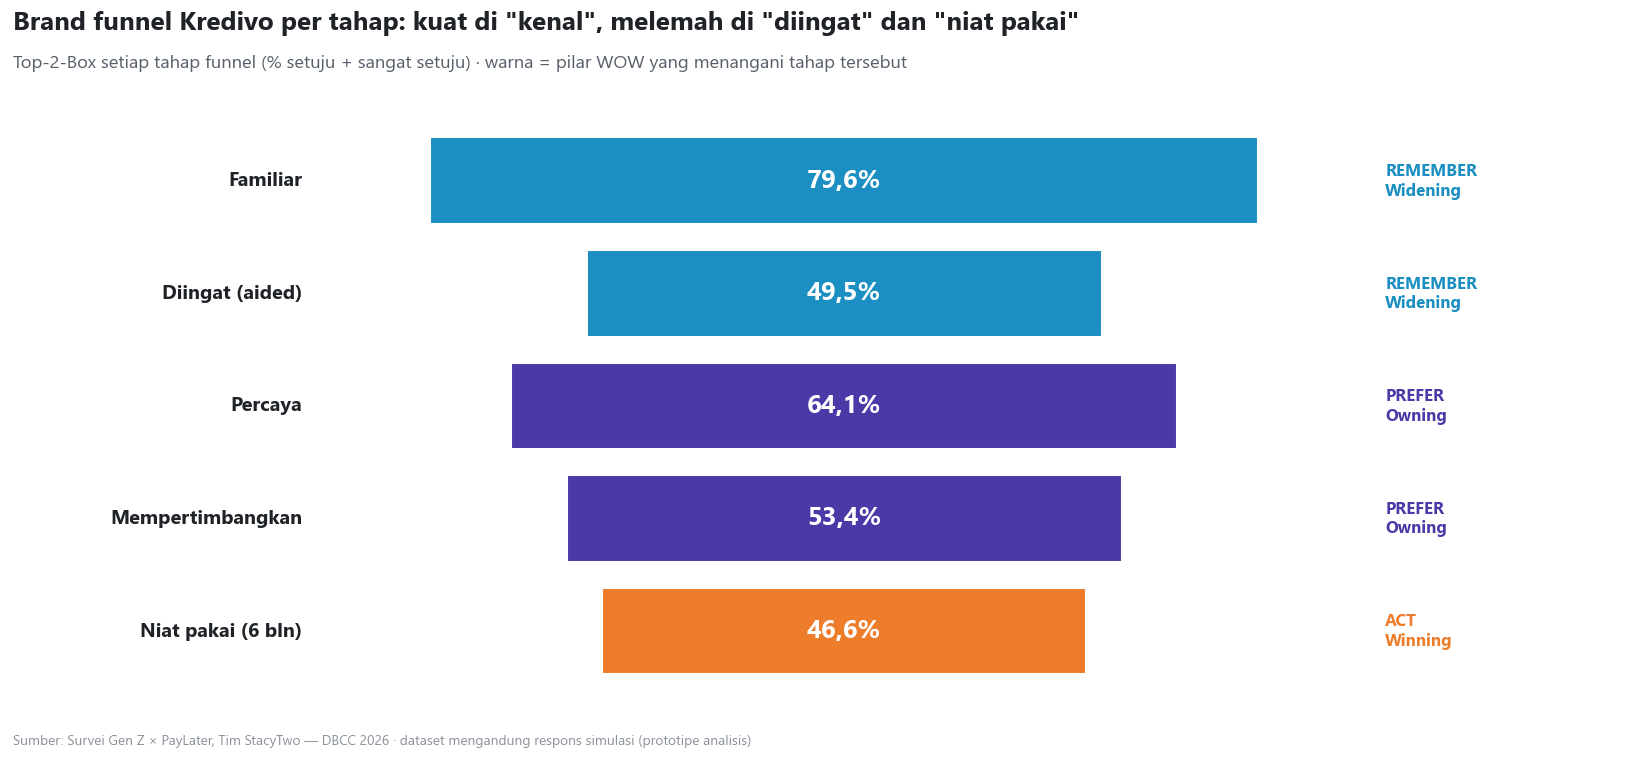

In [22]:
f_t2b = pd.Series({tahap: T2B[k] for k, tahap, _, _ in FUNNEL})
f_warna = [PILAR_WARNA[p] for _, _, _, p in FUNNEL]
fig, ax = plt.subplots(figsize=(15, 7))
for i, ((k, tahap, perilaku, pilar), v) in enumerate(zip(FUNNEL, f_t2b.values)):
    yy = len(FUNNEL) - 1 - i
    ax.barh(yy, v, left=(1 - v) / 2, color=PILAR_WARNA[pilar], height=0.78, edgecolor='white', linewidth=2)
    ax.text(0.5, yy, fpct(v, 1), ha='center', va='center', fontsize=17, fontweight='bold', color='white')
    ax.text(-0.02, yy, tahap, ha='right', va='center', fontsize=13, fontweight='bold', color=TEKS)
    ax.text(1.02, yy, f'{perilaku}\n{pilar}', ha='left', va='center', fontsize=11, color=PILAR_WARNA[pilar], fontweight='bold')
ax.set_xlim(-0.3, 1.25); ax.set_ylim(-0.6, len(FUNNEL) - 0.4)
ax.axis('off')
bingkai(fig, 'Brand funnel Kredivo per tahap: kuat di "kenal", melemah di "diingat" dan "niat pakai"',
        'Top-2-Box setiap tahap funnel (% setuju + sangat setuju) · warna = pilar WOW yang menangani tahap tersebut')
simpan(fig, '09a_funnel_per_tahap')

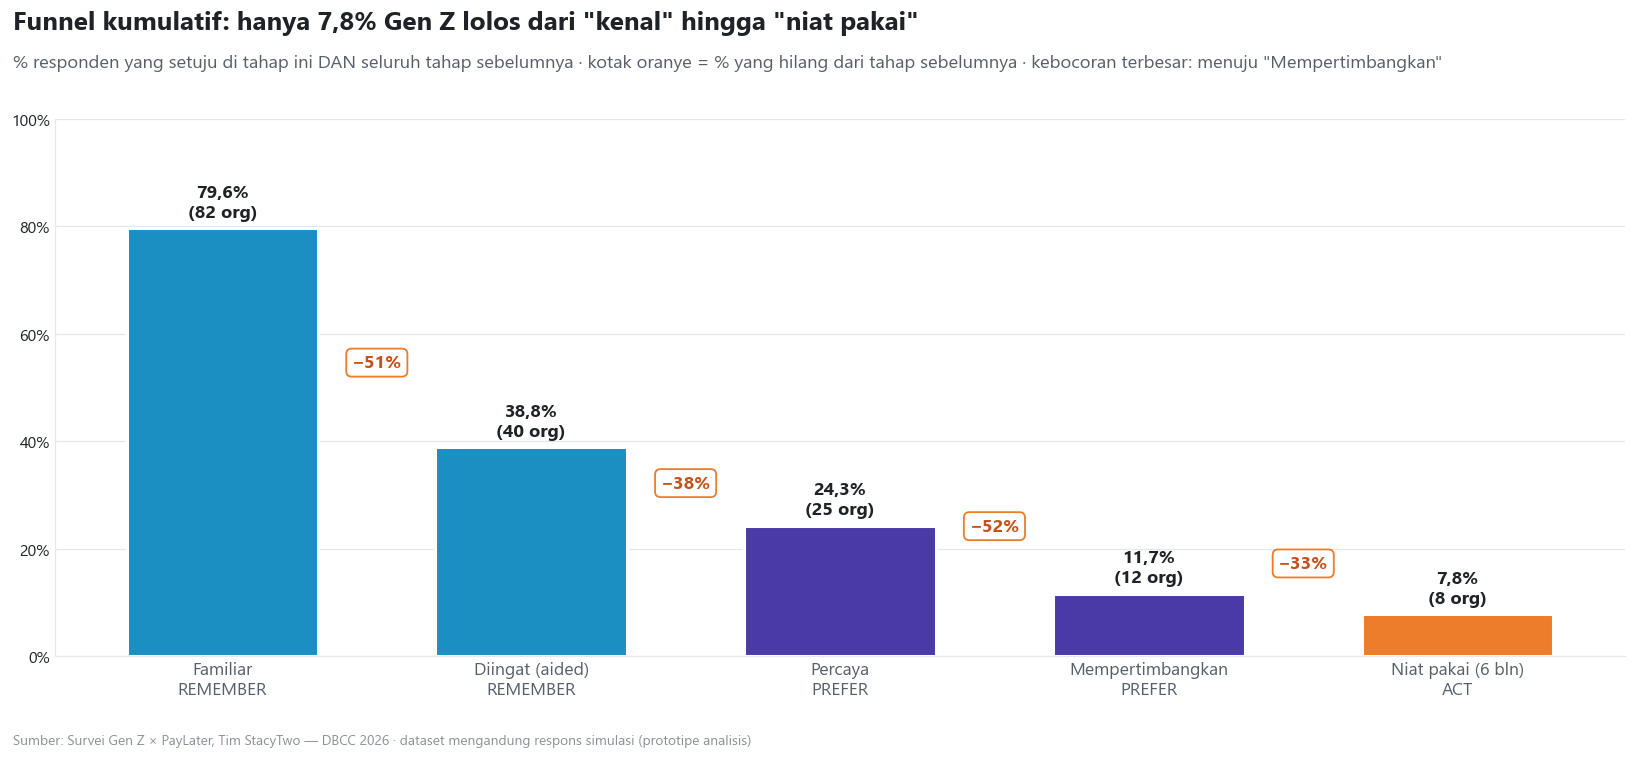

In [23]:
lolos = pd.Series(True, index=df.index)
kum = {}
for k, tahap, _, _ in FUNNEL:
    lolos = lolos & df[f'{k}_t2b']
    kum[tahap] = lolos.mean()
kum = pd.Series(kum)
fig, ax = plt.subplots(figsize=(15, 7))
b = ax.bar(range(len(kum)), kum.values, color=f_warna, width=0.62, edgecolor='white', linewidth=2)
ax.bar_label(b, [f'{fpct(v, 1)}\n({int(round(v * N))} org)' for v in kum.values], padding=5, fontsize=12, fontweight='bold')
retensi = kum / kum.shift(1)
for i in range(1, len(kum)):
    ax.text(i - 0.5, max(kum.iloc[i - 1], kum.iloc[i]) * 0.55 + 0.1, f'−{(1 - retensi.iloc[i]) * 100:.0f}%',
            ha='center', fontsize=12, fontweight='bold', color=ORANYE_TUA,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=ORANYE, linewidth=1.2))
ax.set_xticks(range(len(kum)), [f'{t}\n{p}' for (_, t, p, _) in FUNNEL], fontsize=11.5)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'y')
bocor_terbesar = (1 - retensi).iloc[1:].idxmax()
bingkai(fig, f'Funnel kumulatif: hanya {fpct(kum.iloc[-1], 1)} Gen Z lolos dari "kenal" hingga "niat pakai"',
        f'% responden yang setuju di tahap ini DAN seluruh tahap sebelumnya · kotak oranye = % yang hilang dari tahap sebelumnya · '
        f'kebocoran terbesar: menuju "{bocor_terbesar}"')
simpan(fig, '09b_funnel_kumulatif')

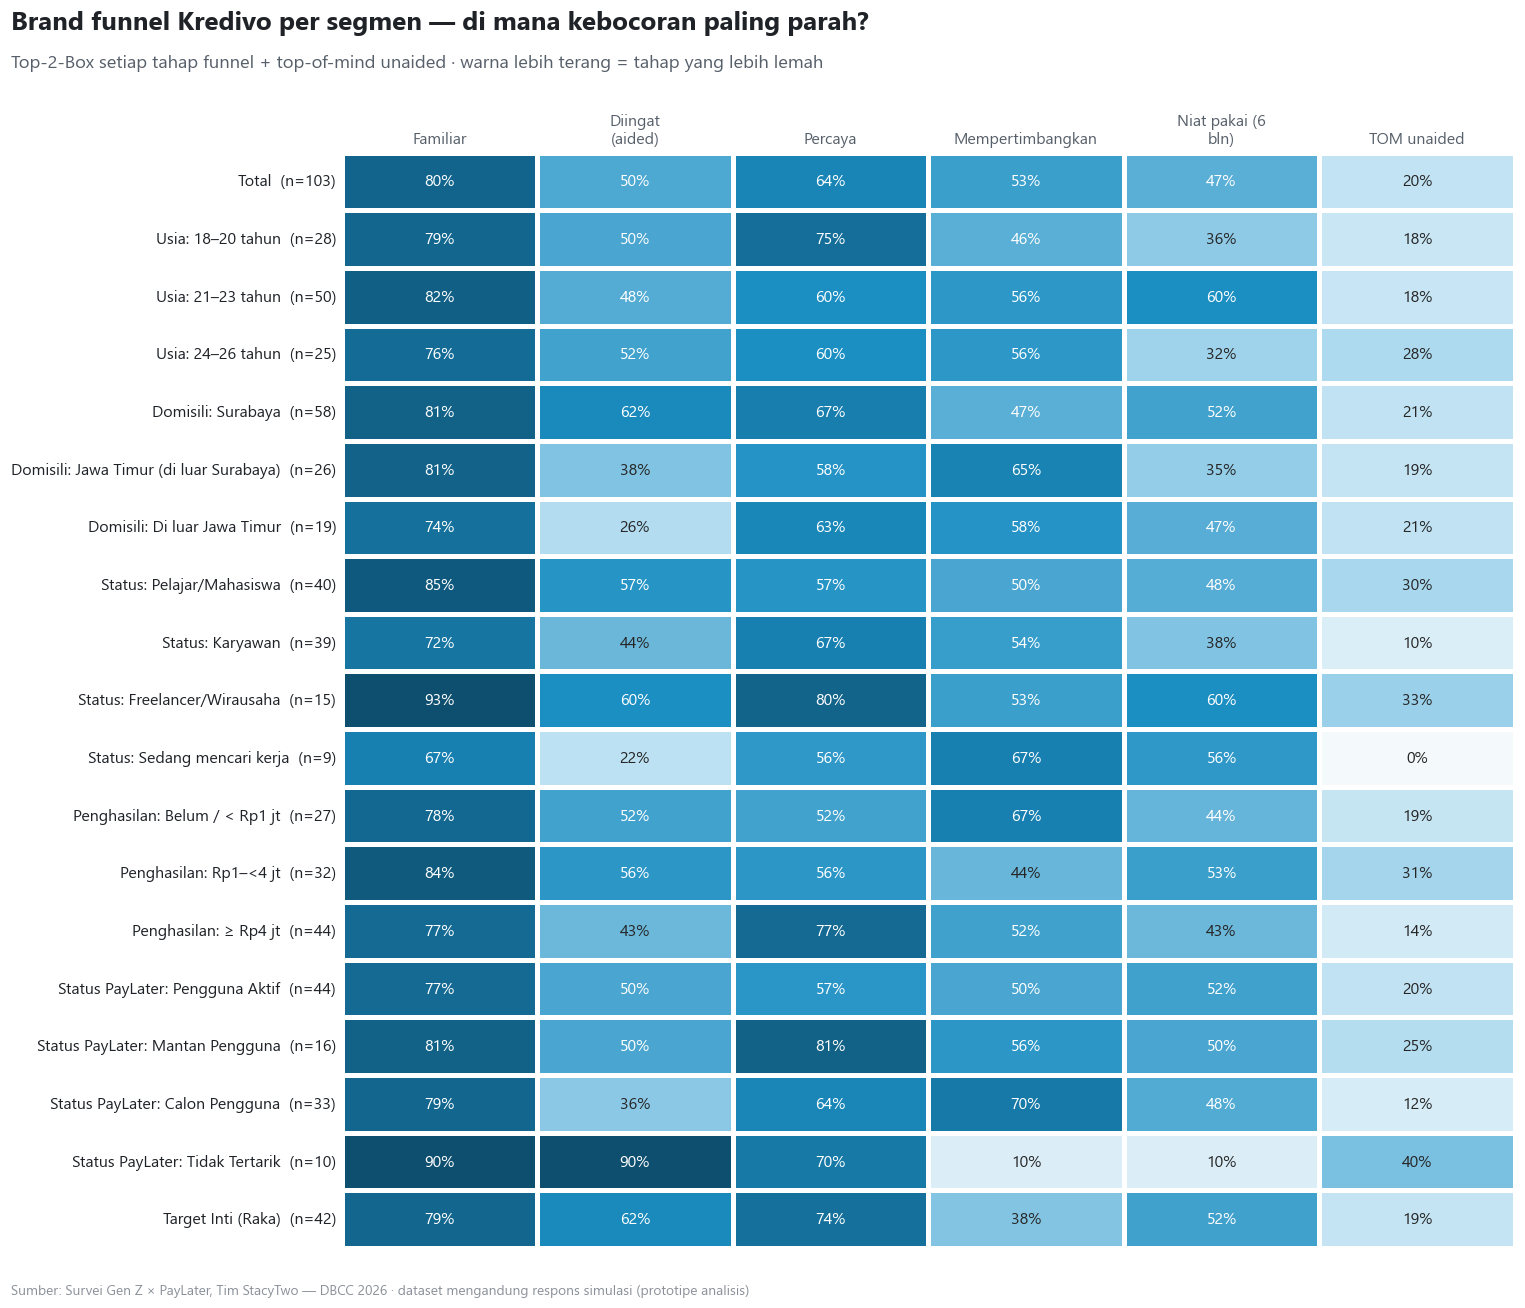

> ### 💡 Insight brand funnel
>
> - Per tahap: Familiar **80%** → Diingat (aided) **50%** → Percaya **64%** → Mempertimbangkan **53%** → Niat pakai **47%**.
> - Secara kumulatif, dari **80%** yang familiar hanya **7,8%** (8 orang) yang lolos hingga niat pakai. Kebocoran terbesar terjadi pada tahap **"Mempertimbangkan"** (−52%).
> - Kebocoran pertama (Familiar → Diingat, −51%) = **Salience Gap** → *Widening*; kebocoran di Percaya/Mempertimbangkan = **Preference Gap** → *Owning*; kebocoran ke Niat pakai = **Activation Gap** → *Winning*. Ketiga gap **terjadi berurutan dan saling memperbesar**, sehingga solusi harus terintegrasi (bukan kampanye tunggal).
> - Angka funnel kumulatif ini adalah versi **berbasis data primer** dari ilustrasi funnel di proposal preliminary — gunakan angka ini (dengan label sumber survei) sebagai pengganti angka yang belum tertrace sumbernya.

In [24]:
rows = [('Total', df)]
for judul, kol in SEGMEN.items():
    for lvl in ORDER.get(kol, sorted(df[kol].unique())):
        rows.append((f'{judul}: {lvl}', df[df[kol] == lvl]))
rows.append(('Target Inti (Raka)', df[df.target_inti]))
fh = pd.DataFrame({f'{nm}  (n={len(d)})': {tahap: d[f'{k}_t2b'].mean() for k, tahap, _, _ in FUNNEL} | {'TOM unaided': d.tom_kredivo.mean()}
                   for nm, d in rows}).T
fig, ax = plt.subplots(figsize=(14, 12))
heatmap(ax, fh, vmin=0, vmax=0.9, fs=10.5)
ax.set_xticklabels([wrap(t.get_text(), 14) for t in ax.get_xticklabels()], rotation=0)
ax.xaxis.tick_top()
bingkai(fig, 'Brand funnel Kredivo per segmen — di mana kebocoran paling parah?',
        'Top-2-Box setiap tahap funnel + top-of-mind unaided · warna lebih terang = tahap yang lebih lemah')
simpan(fig, '09c_funnel_per_segmen')

insight('Insight brand funnel', [
    f"Per tahap: Familiar **{fpct(f_t2b.iloc[0])}** → Diingat (aided) **{fpct(f_t2b.iloc[1])}** → Percaya **{fpct(f_t2b.iloc[2])}** → Mempertimbangkan **{fpct(f_t2b.iloc[3])}** → Niat pakai **{fpct(f_t2b.iloc[4])}**.",
    f"Secara kumulatif, dari **{fpct(kum.iloc[0])}** yang familiar hanya **{fpct(kum.iloc[-1], 1)}** ({int(round(kum.iloc[-1] * N))} orang) yang lolos hingga niat pakai. Kebocoran terbesar terjadi pada tahap **\"{bocor_terbesar}\"** (−{(1 - retensi[bocor_terbesar]) * 100:.0f}%).",
    f"Kebocoran pertama (Familiar → Diingat, −{(1 - retensi.iloc[1]) * 100:.0f}%) = **Salience Gap** → *Widening*; kebocoran di Percaya/Mempertimbangkan = **Preference Gap** → *Owning*; kebocoran ke Niat pakai = **Activation Gap** → *Winning*. Ketiga gap **terjadi berurutan dan saling memperbesar**, sehingga solusi harus terintegrasi (bukan kampanye tunggal).",
    'Angka funnel kumulatif ini adalah versi **berbasis data primer** dari ilustrasi funnel di proposal preliminary — gunakan angka ini (dengan label sumber survei) sebagai pengganti angka yang belum tertrace sumbernya.',
])

## 10. PREFERENCE GAP — Trust, Kejelasan Biaya & Hambatan
Mengapa awareness belum berubah menjadi preferensi? Kami menganalisis **hambatan utama** yang disebut responden dan mengelompokkannya ke dalam tema, lalu memetakan setiap tema ke mekanisme WOW yang menjawabnya.

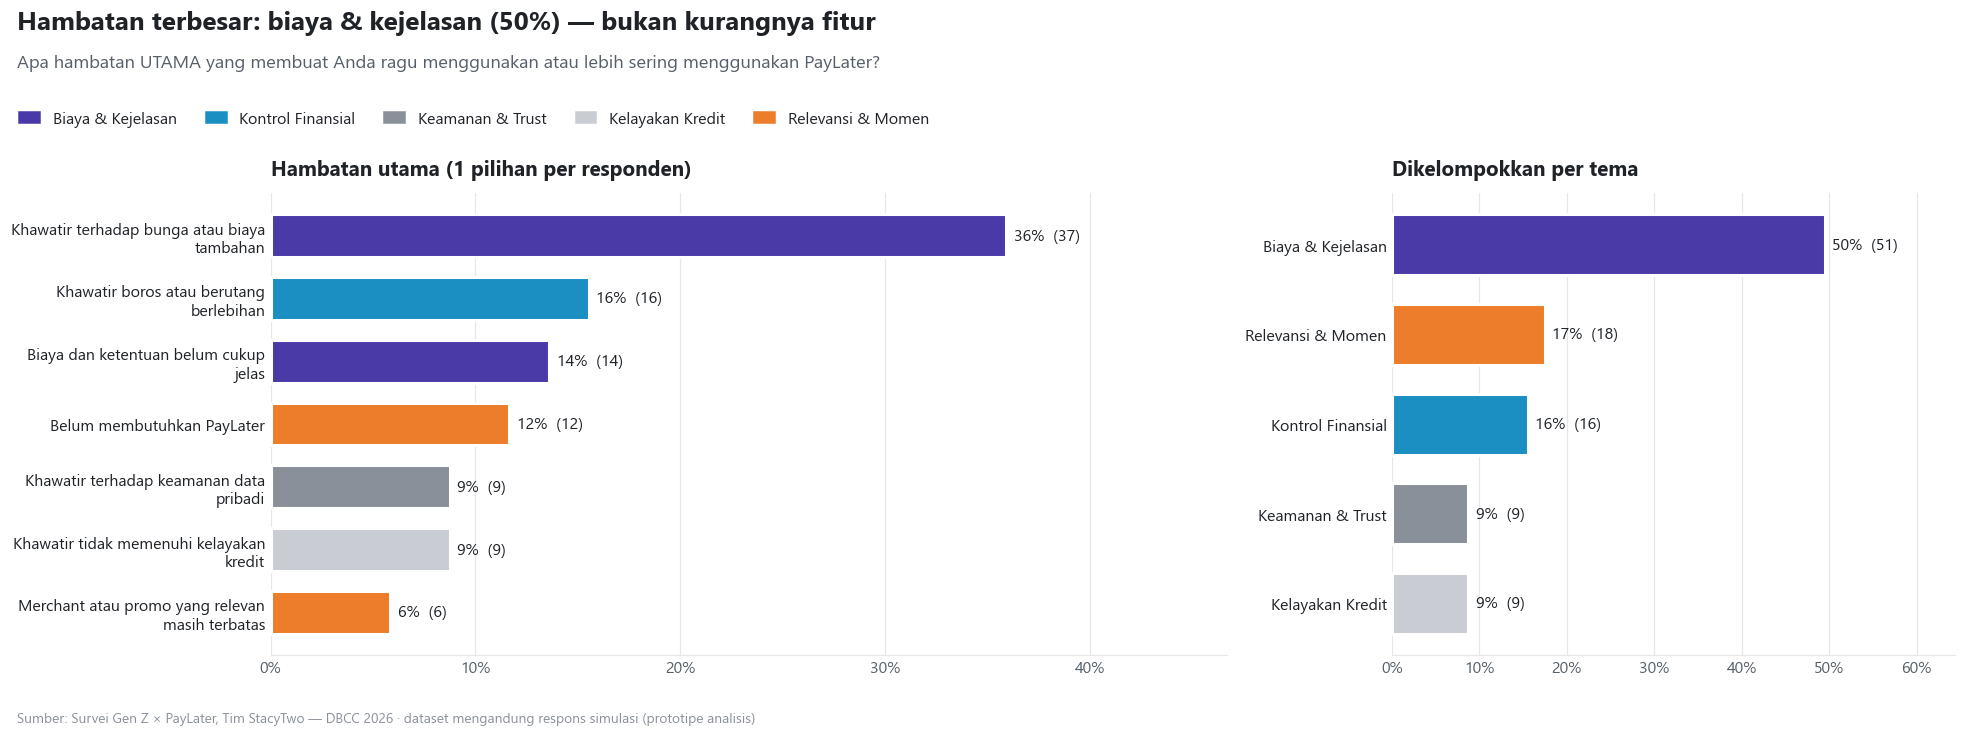

Pemetaan hambatan → solusi WOW Strategy


Hambatan,Tema,% responden,Pilar WOW,Jawaban WOW Strategy
Khawatir terhadap bunga atau biaya tambahan,Biaya & Kejelasan,36%,Owning,Smart Choice — simulasi total biaya & cicilan sebelum checkout
Khawatir boros atau berutang berlebihan,Kontrol Finansial,16%,Owning,Smart Choice — rekomendasi tenor sesuai kemampuan (responsible use)
Biaya dan ketentuan belum cukup jelas,Biaya & Kejelasan,14%,Owning,Smart Choice + Proof — penjelasan biaya yang transparan & sederhana
Belum membutuhkan PayLater,Relevansi & Momen,12%,Winning,Kredivo Fit + NOW — hadir di momen kebutuhan yang relevan
Khawatir tidak memenuhi kelayakan kredit,Kelayakan Kredit,9%,Winning,Eligibility communication di Kredivo NOW & Fit
Khawatir terhadap keamanan data pribadi,Keamanan & Trust,9%,Owning,"Kredivo Proof — trust signal, izin & pengawasan OJK, user stories"
Merchant atau promo yang relevan masih terbatas,Relevansi & Momen,6%,Winning,Kredivo Deals — penawaran kontekstual di merchant Gen Z


In [25]:
TEMA_HAMBATAN = {
    'Khawatir terhadap bunga atau biaya tambahan': 'Biaya & Kejelasan',
    'Biaya dan ketentuan belum cukup jelas': 'Biaya & Kejelasan',
    'Khawatir boros atau berutang berlebihan': 'Kontrol Finansial',
    'Khawatir terhadap keamanan data pribadi': 'Keamanan & Trust',
    'Khawatir tidak memenuhi kelayakan kredit': 'Kelayakan Kredit',
    'Belum membutuhkan PayLater': 'Relevansi & Momen',
    'Merchant atau promo yang relevan masih terbatas': 'Relevansi & Momen',
}
JAWABAN_WOW = {
    'Khawatir terhadap bunga atau biaya tambahan': ('Owning', 'Smart Choice — simulasi total biaya & cicilan sebelum checkout'),
    'Biaya dan ketentuan belum cukup jelas': ('Owning', 'Smart Choice + Proof — penjelasan biaya yang transparan & sederhana'),
    'Khawatir boros atau berutang berlebihan': ('Owning', 'Smart Choice — rekomendasi tenor sesuai kemampuan (responsible use)'),
    'Khawatir terhadap keamanan data pribadi': ('Owning', 'Kredivo Proof — trust signal, izin & pengawasan OJK, user stories'),
    'Khawatir tidak memenuhi kelayakan kredit': ('Winning', 'Eligibility communication di Kredivo NOW & Fit'),
    'Belum membutuhkan PayLater': ('Winning', 'Kredivo Fit + NOW — hadir di momen kebutuhan yang relevan'),
    'Merchant atau promo yang relevan masih terbatas': ('Winning', 'Kredivo Deals — penawaran kontekstual di merchant Gen Z'),
}
TEMA_WARNA = {'Biaya & Kejelasan': UNGU, 'Kontrol Finansial': BIRU, 'Keamanan & Trust': ABU_TUA,
              'Kelayakan Kredit': ABU, 'Relevansi & Momen': ORANYE}
df['tema_hambatan'] = df['hambatan'].map(TEMA_HAMBATAN)
hb = df['hambatan'].value_counts(normalize=True)
tm = df['tema_hambatan'].value_counts(normalize=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.8), gridspec_kw={'width_ratios': [1.7, 1]})
bar_h(ax1, hb, n=N, warna={k: TEMA_WARNA[v] for k, v in TEMA_HAMBATAN.items()}, lebar=34)
ax1.set_title('Hambatan utama (1 pilihan per responden)')
bar_h(ax2, tm, n=N, warna=TEMA_WARNA, lebar=22)
ax2.set_title('Dikelompokkan per tema')
bingkai(fig, f"Hambatan terbesar: biaya & kejelasan ({fpct(tm.get('Biaya & Kejelasan', 0))}) — bukan kurangnya fitur",
        'Apa hambatan UTAMA yang membuat Anda ragu menggunakan atau lebih sering menggunakan PayLater?',
        legend=[Patch(color=c, label=t) for t, c in TEMA_WARNA.items()])
simpan(fig, '10a_hambatan')

peta = pd.DataFrame([{'Hambatan': h, 'Tema': TEMA_HAMBATAN[h], '% responden': fpct(hb.get(h, 0)),
                      'Pilar WOW': JAWABAN_WOW[h][0], 'Jawaban WOW Strategy': JAWABAN_WOW[h][1]}
                     for h in hb.index])
print('Pemetaan hambatan → solusi WOW Strategy')
display(peta.style.hide(axis='index'))

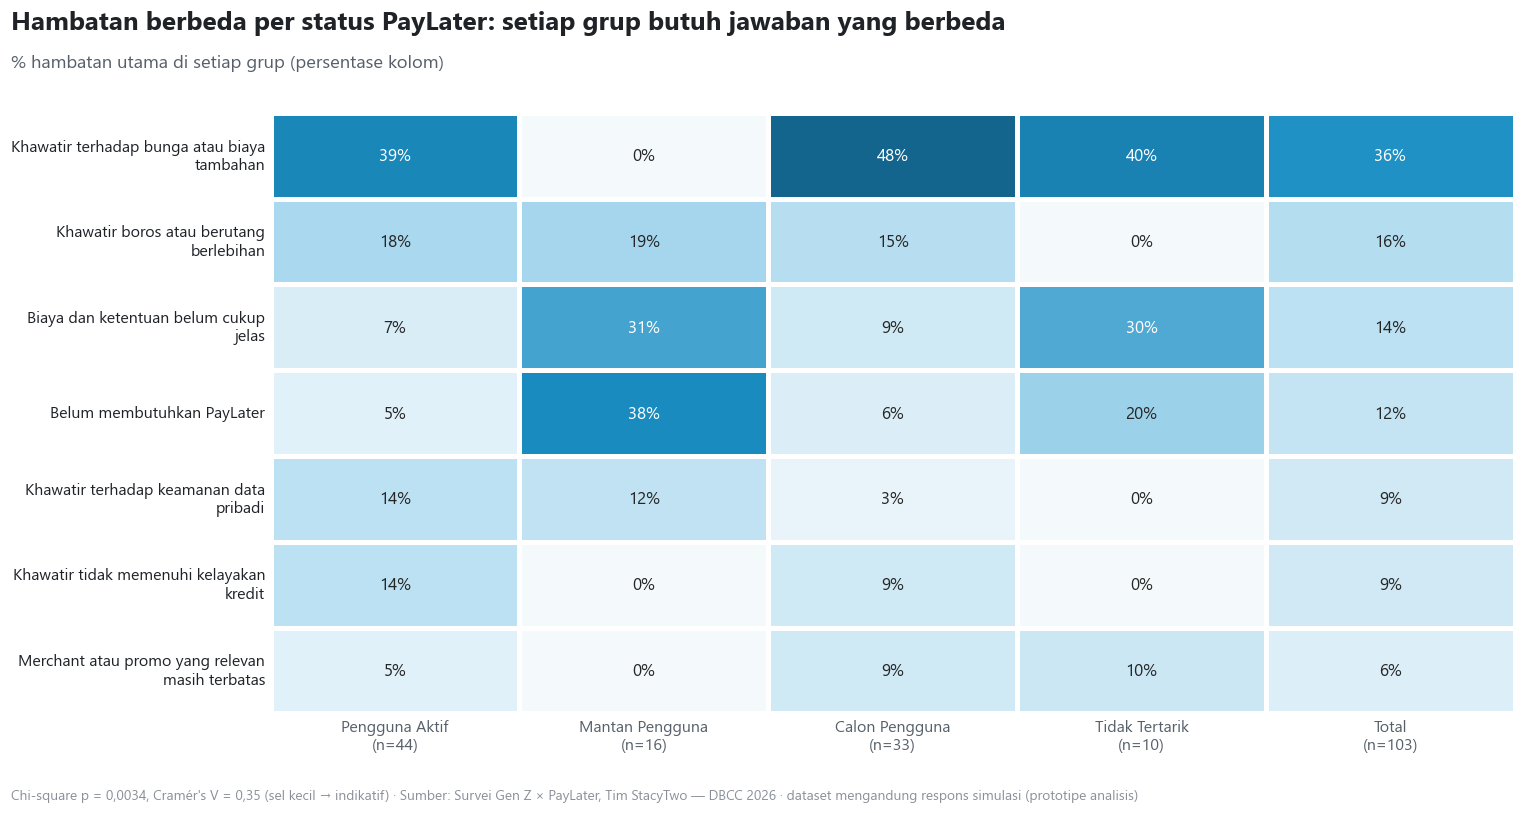

In [26]:
hg = pd.crosstab(df['hambatan'], df['grup_pengguna'], normalize='columns').reindex(columns=ORDER['grup_pengguna'])
hg['Total'] = hb
hg = hg.sort_values('Total', ascending=False)
hg.index = [wrap(i, 34) for i in hg.index]
chi_hg = uji_chi('hambatan', 'grup_pengguna')
CV = "Cramér's V"
fig, ax = plt.subplots(figsize=(14, 7.5))
heatmap(ax, hg, vmin=0, vmax=0.55, fs=11)
ax.set_xticklabels([f"{t.get_text()}\n(n={(df.grup_pengguna == t.get_text()).sum() if t.get_text() != 'Total' else N})"
                    for t in ax.get_xticklabels()], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
bingkai(fig, 'Hambatan berbeda per status PayLater: setiap grup butuh jawaban yang berbeda',
        '% hambatan utama di setiap grup (persentase kolom)',
        catatan=f"Chi-square p = {fnum(chi_hg['p-value'], 4)}, Cramér's V = {fnum(chi_hg[CV], 2)} (sel kecil → indikatif)")
simpan(fig, '10b_hambatan_per_grup')

### 10.1 "Diingat ≠ Dipercaya"
Apakah responden yang **sudah mengingat Kredivo sebagai brand pertama** otomatis lebih percaya dan lebih berniat memakai? Jika tidak, maka memperbesar awareness saja tidak cukup — dibutuhkan pilar **Owning the Preference**.

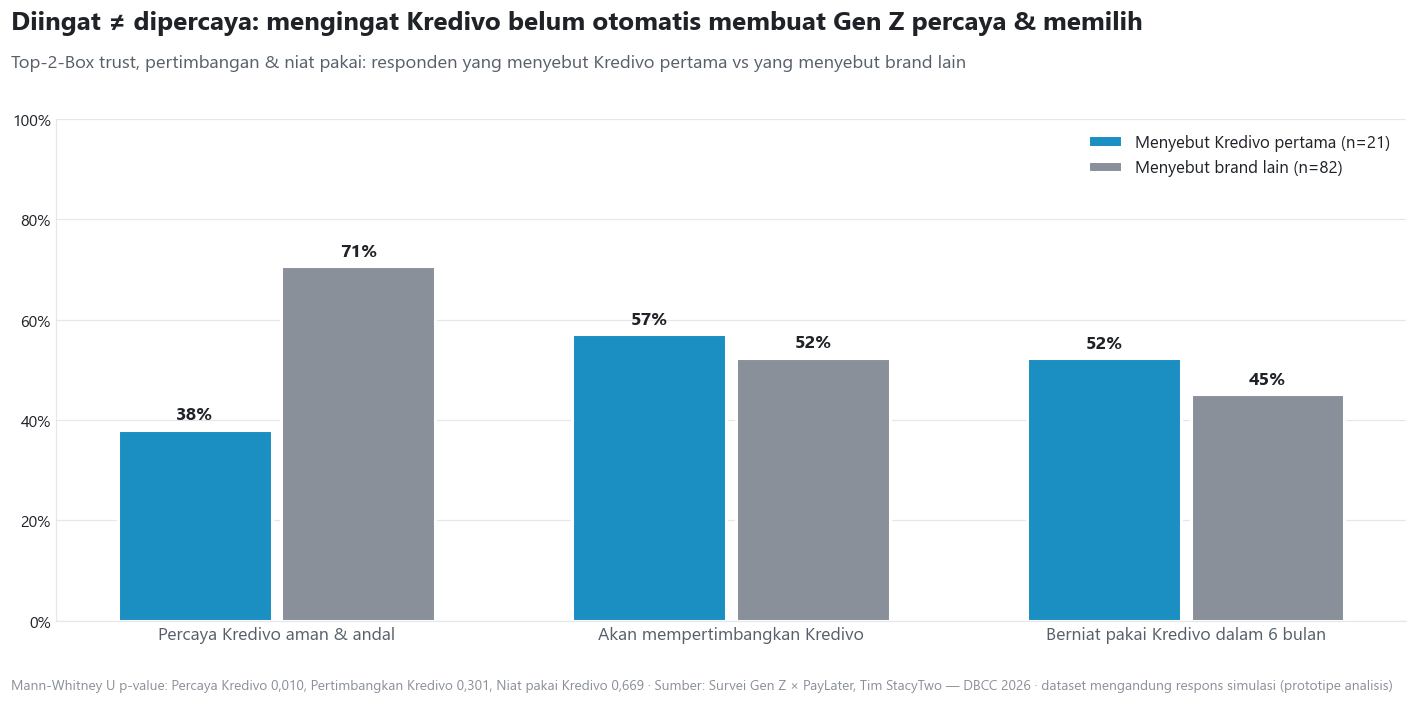

> ### 💡 Insight Preference Gap
>
> - Tema hambatan terbesar adalah **Biaya & Kejelasan (50%)**: khawatir bunga/biaya tambahan (36%) dan ketentuan belum jelas (14%). Ditambah khawatir boros (16%), **65% hambatan bisa dijawab langsung oleh Kredivo Smart Choice**.
> - Pembanding nasional (Laporan PayLater 2024): alasan non-pengguna terbesar adalah *tidak mau menambah utang* (53,7%) dan *takut denda telat bayar* (35,3%) → kekhawatiran finansial adalah pola nasional, bukan hanya di sampel ini.
> - Hambatan berbeda per grup: **Calon Pengguna** paling khawatir bunga/biaya (48%) → butuh *Smart Choice*; **Mantan Pengguna** paling banyak menyebut *'Belum membutuhkan PayLater'* (38%) → butuh *Kredivo Fit/NOW* dan *WOW Loop* untuk win-back.
> - **Diingat ≠ dipercaya:** di antara yang menyebut Kredivo pertama, hanya **38%** yang percaya Kredivo aman & andal, dibanding **71%** pada responden lain (Mann-Whitney p = 0,010). Awareness tanpa trust tidak menghasilkan preferensi → **Widening harus selalu dipasangkan dengan Owning** (Smart Choice + Proof).

In [27]:
kel = {'Menyebut Kredivo pertama': df[df.tom_kredivo], 'Menyebut brand lain': df[~df.tom_kredivo]}
metrik = ['k_trust', 'k_consider', 'k_intent']
x = np.arange(len(metrik)); w = 0.36
fig, ax = plt.subplots(figsize=(13, 6.5))
for j, ((nm, d), c) in enumerate(zip(kel.items(), [BIRU, ABU_TUA])):
    vals = [d[f'{m}_t2b'].mean() for m in metrik]
    b = ax.bar(x + (j - 0.5) * w, vals, w * 0.94, color=c, label=f'{nm} (n={len(d)})', edgecolor='white', linewidth=2)
    ax.bar_label(b, [fpct(v) for v in vals], padding=4, fontsize=12, fontweight='bold')
ax.set_xticks(x, [LABEL[m] for m in metrik], fontsize=11.5)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'y'); ax.legend(loc='upper right', fontsize=11)
mw = {m: stats.mannwhitneyu(kel['Menyebut Kredivo pertama'][m], kel['Menyebut brand lain'][m]).pvalue for m in metrik}
bingkai(fig, 'Diingat ≠ dipercaya: mengingat Kredivo belum otomatis membuat Gen Z percaya & memilih',
        'Top-2-Box trust, pertimbangan & niat pakai: responden yang menyebut Kredivo pertama vs yang menyebut brand lain',
        catatan='Mann-Whitney U p-value: ' + ', '.join(f'{LABEL_PENDEK[m]} {fnum(p, 3)}' for m, p in mw.items()))
simpan(fig, '10c_diingat_vs_dipercaya')

trust_tom, trust_lain = kel['Menyebut Kredivo pertama'].k_trust_t2b.mean(), kel['Menyebut brand lain'].k_trust_t2b.mean()
mantan = df[df.grup_pengguna == 'Mantan Pengguna']
calon = df[df.grup_pengguna == 'Calon Pengguna']
insight('Insight Preference Gap', [
    f"Tema hambatan terbesar adalah **Biaya & Kejelasan ({fpct(tm.get('Biaya & Kejelasan', 0))})**: khawatir bunga/biaya tambahan ({fpct(hb.get('Khawatir terhadap bunga atau biaya tambahan', 0))}) dan ketentuan belum jelas ({fpct(hb.get('Biaya dan ketentuan belum cukup jelas', 0))}). Ditambah khawatir boros ({fpct(hb.get('Khawatir boros atau berutang berlebihan', 0))}), **{fpct(tm.get('Biaya & Kejelasan', 0) + tm.get('Kontrol Finansial', 0))} hambatan bisa dijawab langsung oleh Kredivo Smart Choice**.",
    f"Pembanding nasional (Laporan PayLater 2024): alasan non-pengguna terbesar adalah *tidak mau menambah utang* (53,7%) dan *takut denda telat bayar* (35,3%) → kekhawatiran finansial adalah pola nasional, bukan hanya di sampel ini.",
    f"Hambatan berbeda per grup: **Calon Pengguna** paling khawatir bunga/biaya ({fpct(calon.hambatan.eq('Khawatir terhadap bunga atau biaya tambahan').mean())}) → butuh *Smart Choice*; **Mantan Pengguna** paling banyak menyebut *'{mantan.hambatan.value_counts().index[0]}'* ({fpct(mantan.hambatan.value_counts(normalize=True).iloc[0])}) → butuh *Kredivo Fit/NOW* dan *WOW Loop* untuk win-back.",
    f"**Diingat ≠ dipercaya:** di antara yang menyebut Kredivo pertama, hanya **{fpct(trust_tom)}** yang percaya Kredivo aman & andal, dibanding **{fpct(trust_lain)}** pada responden lain (Mann-Whitney p = {fnum(mw['k_trust'], 3)}). Awareness tanpa trust tidak menghasilkan preferensi → **Widening harus selalu dipasangkan dengan Owning** (Smart Choice + Proof).",
])

## 11. ACTIVATION GAP — Dari Preferensi ke Transaksi
Jika Gen Z sudah mengenal dan mempertimbangkan Kredivo, apa yang menahan mereka untuk bertransaksi? Bagian ini menguji dua root cause: **Promotion-Dependent Trial** dan **Disconnected Transaction Moments**.

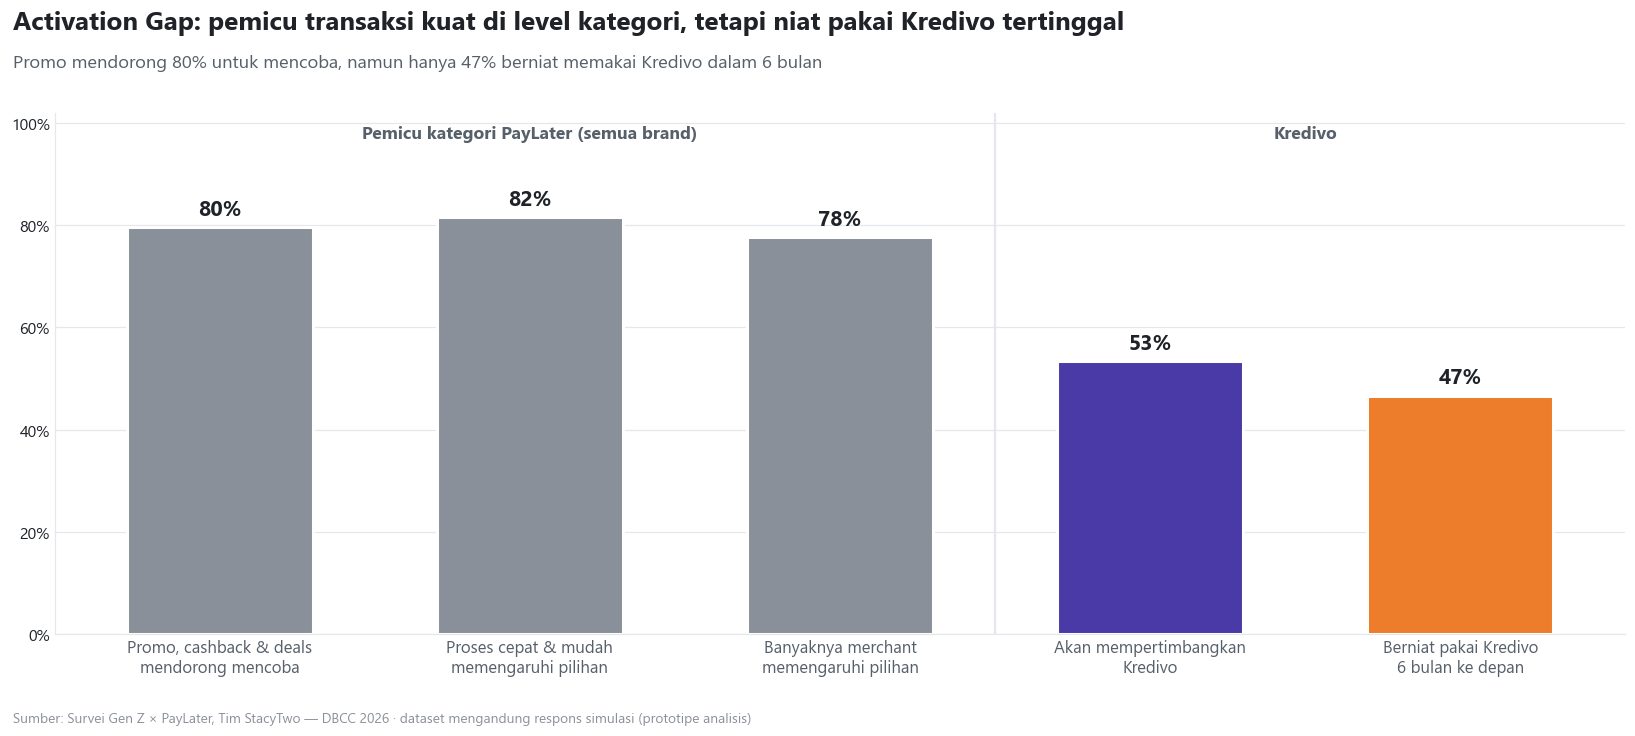

In [28]:
pendorong = pd.Series({
    'Promo, cashback & deals\nmendorong mencoba': T2B['promo'],
    'Proses cepat & mudah\nmemengaruhi pilihan': T2B['cepat'],
    'Banyaknya merchant\nmemengaruhi pilihan': T2B['merchant'],
    'Akan mempertimbangkan\nKredivo': T2B['k_consider'],
    'Berniat pakai Kredivo\n6 bulan ke depan': T2B['k_intent'],
})
fig, ax = plt.subplots(figsize=(15, 6.8))
b = ax.bar(range(len(pendorong)), pendorong.values, color=[ABU_TUA] * 3 + [UNGU, ORANYE], width=0.6, edgecolor='white', linewidth=2)
ax.bar_label(b, [fpct(v) for v in pendorong.values], padding=5, fontsize=14, fontweight='bold')
ax.set_xticks(range(len(pendorong)), pendorong.index, fontsize=11)
ax.axvline(2.5, color=GRID, linewidth=1.5)
ax.text(1, 0.97, 'Pemicu kategori PayLater (semua brand)', ha='center', fontsize=11.5, color=TEKS2, fontweight='bold')
ax.text(3.5, 0.97, 'Kredivo', ha='center', fontsize=11.5, color=TEKS2, fontweight='bold')
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'y')
bingkai(fig, 'Activation Gap: pemicu transaksi kuat di level kategori, tetapi niat pakai Kredivo tertinggal',
        f"Promo mendorong {fpct(T2B['promo'])} untuk mencoba, namun hanya {fpct(T2B['k_intent'])} berniat memakai Kredivo dalam 6 bulan")
simpan(fig, '11a_activation_gap')

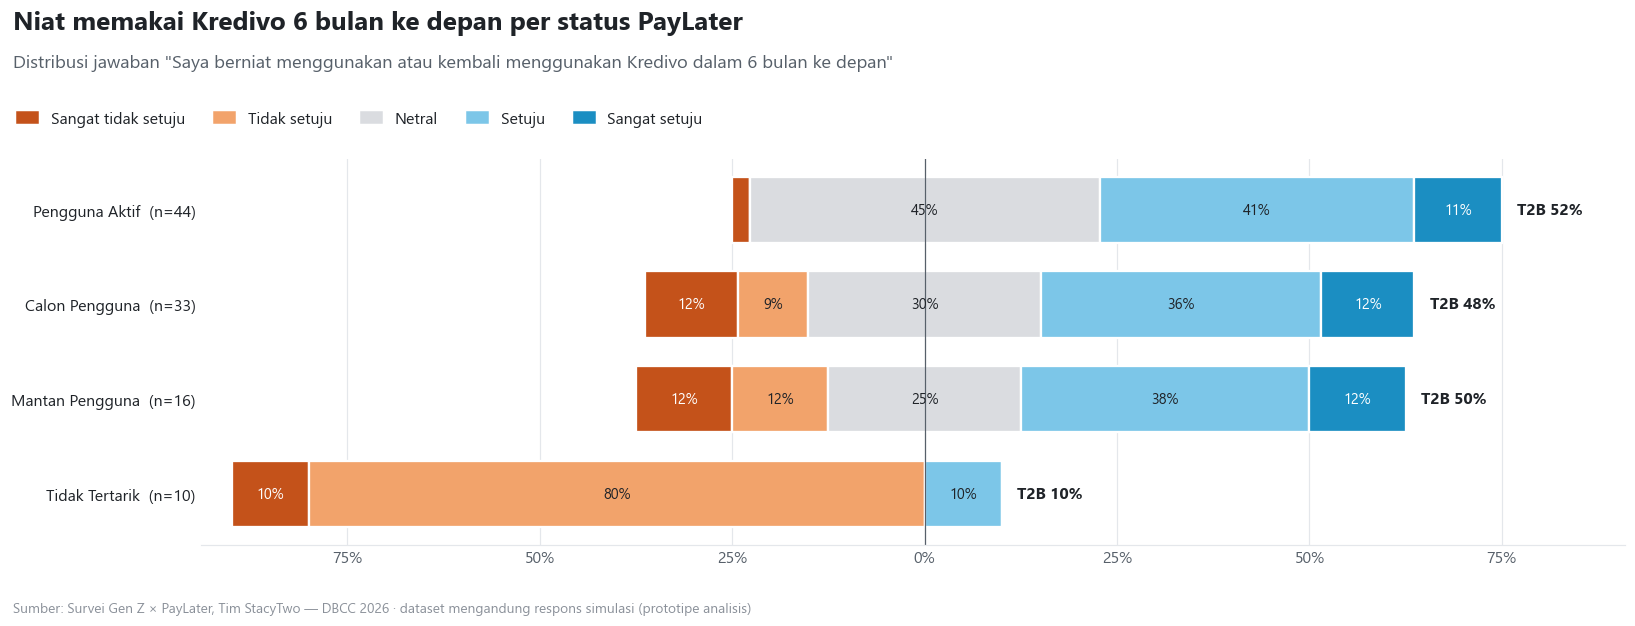

In [29]:
fig, ax = plt.subplots(figsize=(15, 5.8))
_, handles = likert_diverging(ax, {f'{g}  (n={(df.grup_pengguna == g).sum()})': df.loc[df.grup_pengguna == g, 'k_intent']
                                   for g in ORDER['grup_pengguna']}, lebar=34)
bingkai(fig, 'Niat memakai Kredivo 6 bulan ke depan per status PayLater',
        'Distribusi jawaban "Saya berniat menggunakan atau kembali menggunakan Kredivo dalam 6 bulan ke depan"',
        legend=handles)
simpan(fig, '11b_niat_per_grup')

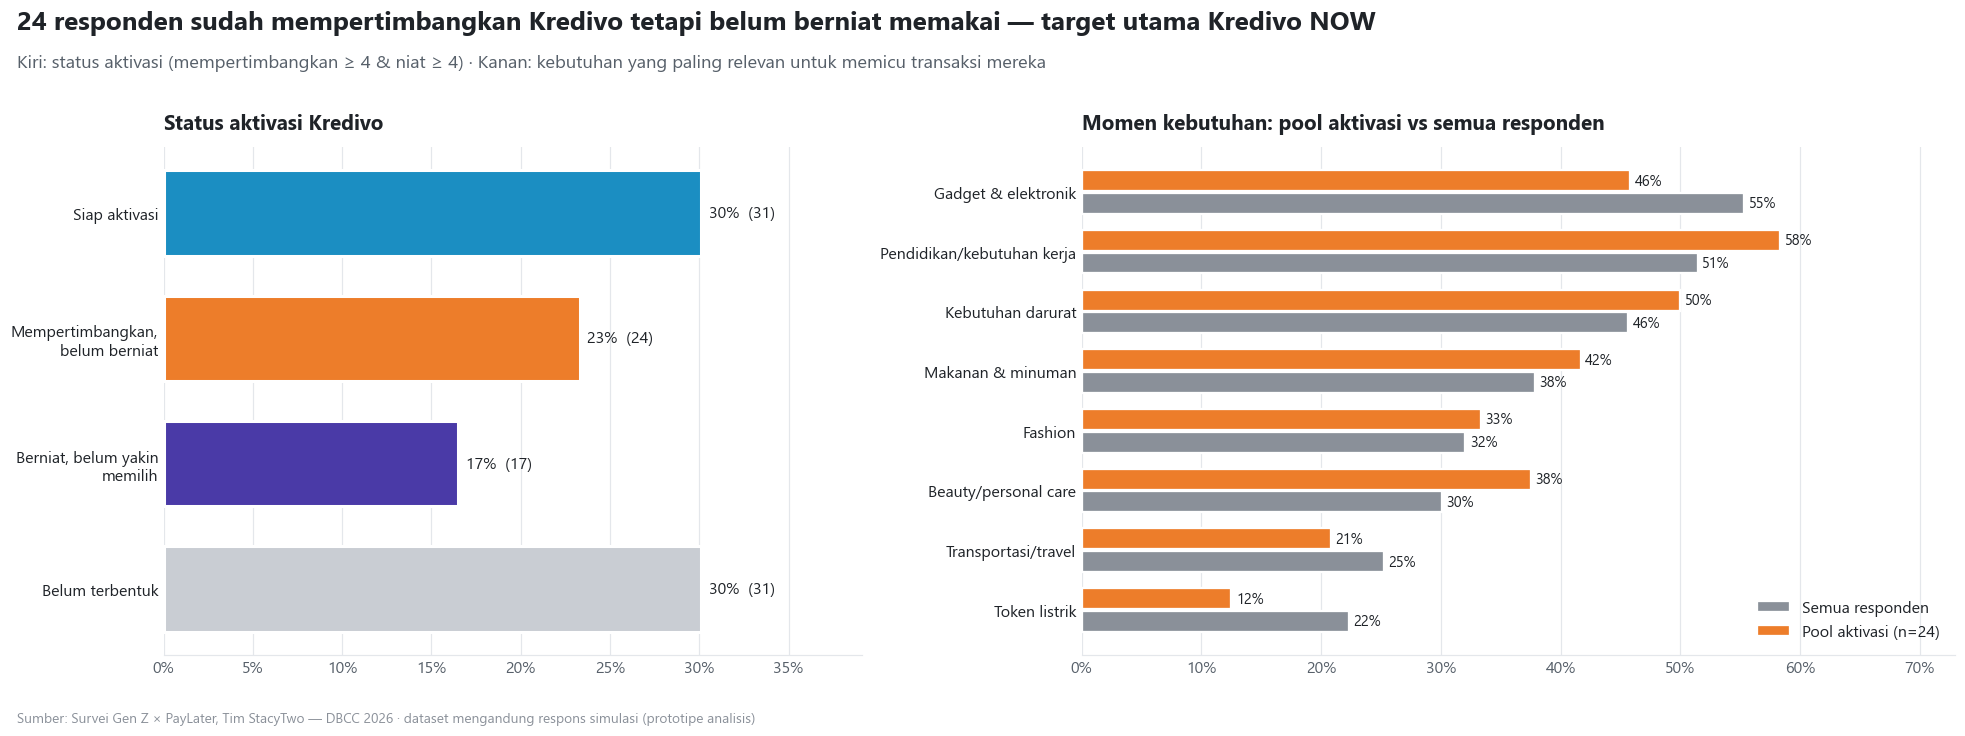

> ### 💡 Insight Activation Gap
>
> - Pemicu kategori sangat kuat (promo 80%, proses cepat 82%, merchant 78%), tetapi hanya **47%** berniat memakai Kredivo → pemicu ini dinikmati **semua** brand PayLater, bukan khusus Kredivo.
> - Niat pakai di antara yang sangat terdorong promo (48%) tidak jauh berbeda dengan yang tidak (43%) → **promo generik tidak cukup** untuk mengaktivasi; yang dibutuhkan adalah **penawaran kontekstual di momen yang tepat** (Kredivo NOW + Deals), bukan diskon massal.
> - **24 responden (23%)** sudah mempertimbangkan Kredivo tetapi belum berniat memakai → *low-hanging fruit* untuk **Kredivo NOW**. Kebutuhan utama mereka: **Pendidikan/kebutuhan kerja** (58%), **Kebutuhan darurat** (50%), **Gadget & elektronik** (46%).
> - **Mantan pengguna** (16 orang) memiliki skor niat rata-rata 3,25 dan **Calon pengguna** 3,27 → **WOW Loop** (relevant next offer, reward, referral) diperlukan agar transaksi pertama berlanjut menjadi repeat.

In [30]:
def status_aktivasi(r):
    if r.k_consider >= 4 and r.k_intent >= 4: return 'Siap aktivasi'
    if r.k_consider >= 4: return 'Mempertimbangkan, belum berniat'
    if r.k_intent >= 4: return 'Berniat, belum yakin memilih'
    return 'Belum terbentuk'
AKT_ORDER = ['Siap aktivasi', 'Mempertimbangkan, belum berniat', 'Berniat, belum yakin memilih', 'Belum terbentuk']
AKT_WARNA = {'Siap aktivasi': BIRU, 'Mempertimbangkan, belum berniat': ORANYE, 'Berniat, belum yakin memilih': UNGU, 'Belum terbentuk': ABU}
df['status_aktivasi'] = df.apply(status_aktivasi, axis=1)
akt = df['status_aktivasi'].value_counts(normalize=True).reindex(AKT_ORDER).fillna(0)
pool = df[df.status_aktivasi == 'Mempertimbangkan, belum berniat']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.8), gridspec_kw={'width_ratios': [1, 1.25]})
bar_h(ax1, akt, n=N, warna=AKT_WARNA, urut=False, lebar=22)
ax1.set_title('Status aktivasi Kredivo')
keb_cmp = pd.DataFrame({'Semua responden': keb_pct, f'Pool aktivasi (n={len(pool)})': KEBUTUHAN.loc[pool.index].mean()}).sort_values('Semua responden')
yy = np.arange(len(keb_cmp)); h = 0.38
for j, (col, c) in enumerate(zip(keb_cmp.columns, [ABU_TUA, ORANYE])):
    b = ax2.barh(yy + (j - 0.5) * h, keb_cmp[col], h * 0.92, color=c, label=col, edgecolor='white', linewidth=1.5)
    ax2.bar_label(b, [fpct(v) for v in keb_cmp[col]], padding=3, fontsize=9.5)
ax2.set_yticks(yy, keb_cmp.index)
ax2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax2.set_xlim(0, keb_cmp.values.max() * 1.25)
gaya(ax2, 'x'); ax2.spines['left'].set_visible(False)
ax2.legend(loc='lower right')
ax2.set_title('Momen kebutuhan: pool aktivasi vs semua responden')
bingkai(fig, f'{len(pool)} responden sudah mempertimbangkan Kredivo tetapi belum berniat memakai — target utama Kredivo NOW',
        'Kiri: status aktivasi (mempertimbangkan ≥ 4 & niat ≥ 4) · Kanan: kebutuhan yang paling relevan untuk memicu transaksi mereka')
simpan(fig, '11c_pool_aktivasi')

promo_intent = df.groupby('promo_t2b')['k_intent_t2b'].mean()
insight('Insight Activation Gap', [
    f"Pemicu kategori sangat kuat (promo {fpct(T2B['promo'])}, proses cepat {fpct(T2B['cepat'])}, merchant {fpct(T2B['merchant'])}), tetapi hanya **{fpct(T2B['k_intent'])}** berniat memakai Kredivo → pemicu ini dinikmati **semua** brand PayLater, bukan khusus Kredivo.",
    f"Niat pakai di antara yang sangat terdorong promo ({fpct(promo_intent.get(True, np.nan))}) {'tidak jauh berbeda' if abs(promo_intent.get(True, 0) - promo_intent.get(False, 0)) < 0.15 else 'berbeda'} dengan yang tidak ({fpct(promo_intent.get(False, np.nan))}) → **promo generik tidak cukup** untuk mengaktivasi; yang dibutuhkan adalah **penawaran kontekstual di momen yang tepat** (Kredivo NOW + Deals), bukan diskon massal.",
    f"**{len(pool)} responden ({fpct(len(pool) / N)})** sudah mempertimbangkan Kredivo tetapi belum berniat memakai → *low-hanging fruit* untuk **Kredivo NOW**. Kebutuhan utama mereka: " + ', '.join(f"**{k}** ({fpct(v)})" for k, v in KEBUTUHAN.loc[pool.index].mean().nlargest(3).items()) + '.',
    f"**Mantan pengguna** ({len(mantan)} orang) memiliki skor niat rata-rata {fnum(mantan.k_intent.mean())} dan **Calon pengguna** {fnum(calon.k_intent.mean())} → **WOW Loop** (relevant next offer, reward, referral) diperlukan agar transaksi pertama berlanjut menjadi repeat.",
])

## 12. Analisis Hubungan & Key Driver (Pendekatan Data Science)
Sampai di sini kita melihat *apa* yang terjadi. Bagian ini mencoba menjawab *apa yang berhubungan dengan niat memakai Kredivo* menggunakan:
1. **Matriks korelasi Spearman** (cocok untuk data ordinal Likert),
2. **Key driver analysis** — korelasi setiap variabel dengan *niat pakai Kredivo 6 bulan*,
3. **Importance–Performance Analysis (IPA)** — membandingkan *importance yang dinyatakan* (T2B) dengan *importance turunan* (korelasi dengan niat),
4. **Uji statistik** untuk memvalidasi setiap gap.

> ⚠️ Ingat catatan Bagian 2.4: korelasi antar item pada dataset ini sangat lemah, sehingga hasil Bagian 12–13 dibaca sebagai **indikatif**. Metodenya tetap valid dan akan memberi sinyal yang lebih kuat ketika dijalankan ulang dengan respons riil.

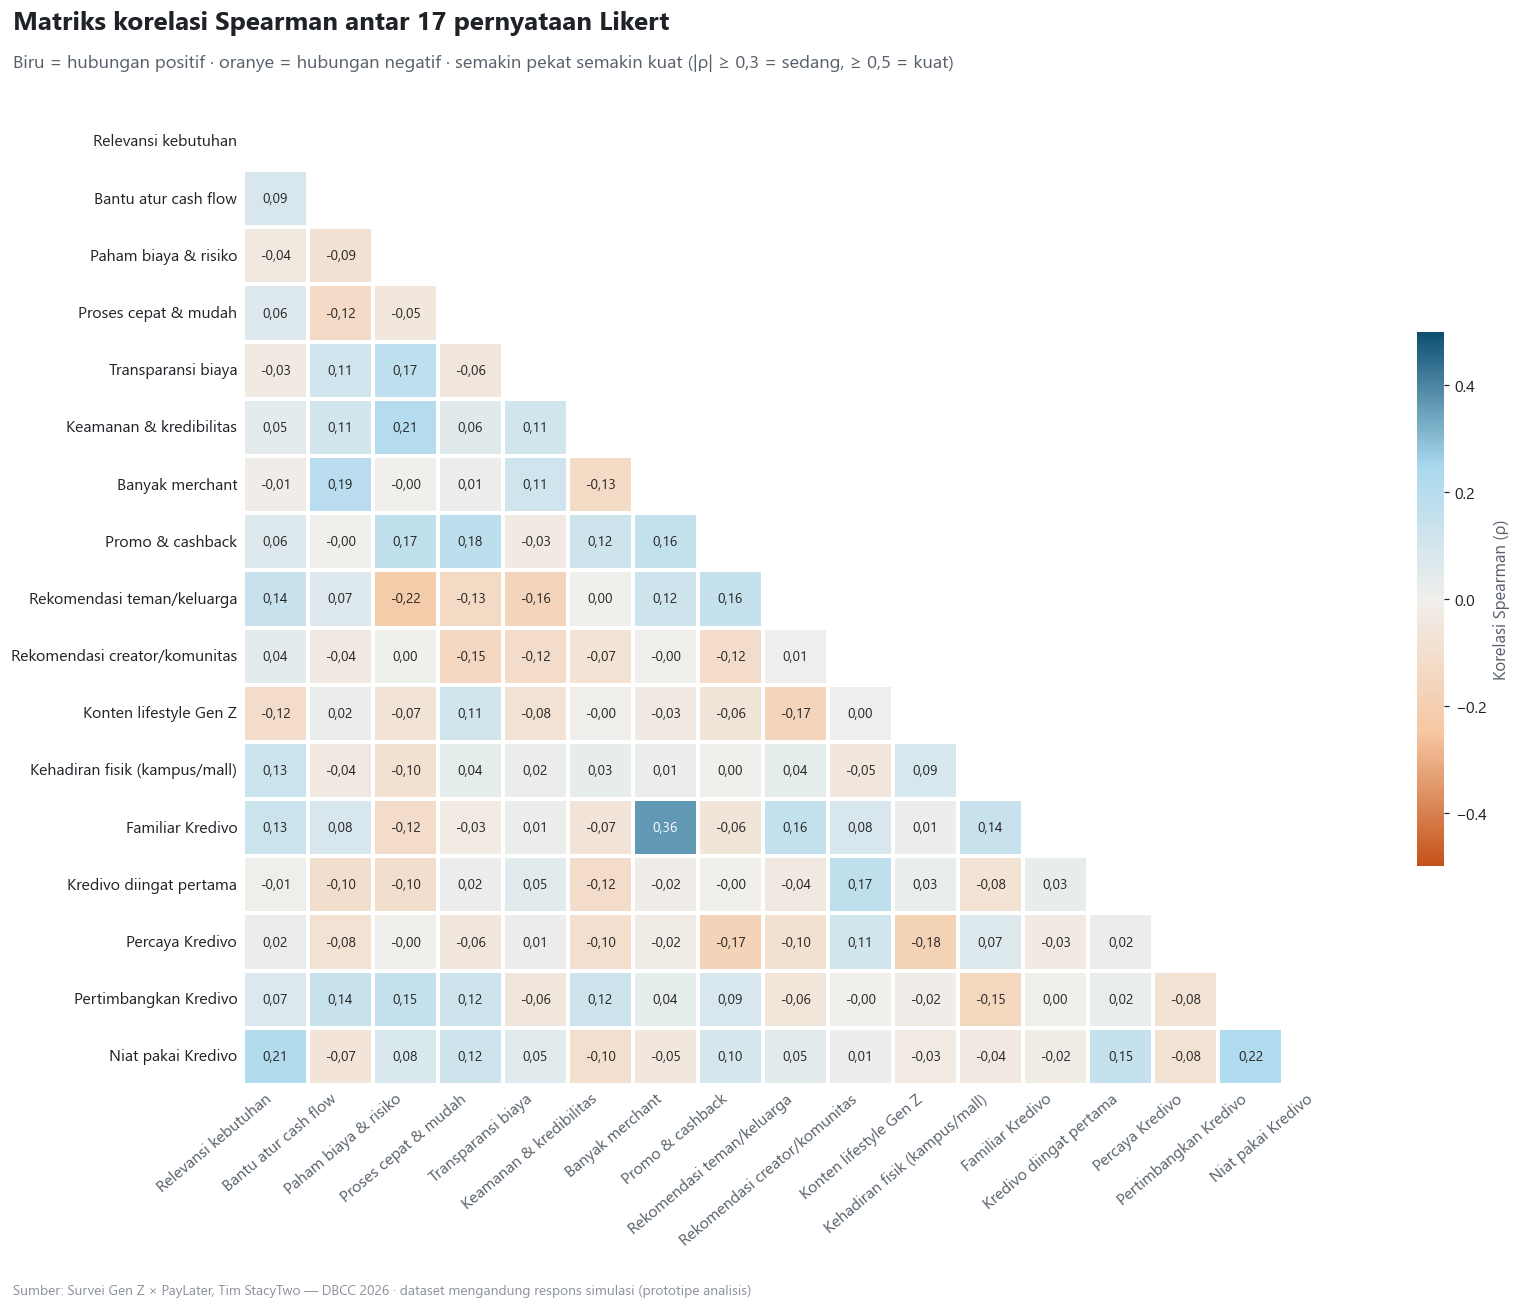

In [31]:
kor = df[LIKERT].corr('spearman')
kor.index = kor.columns = [LABEL_PENDEK[c] for c in LIKERT]
mask = np.triu(np.ones_like(kor, bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(kor, mask=mask, cmap=CMAP_DIV, vmin=-0.5, vmax=0.5, center=0, annot=kor.map(lambda v: fnum(v, 2)), fmt='',
            linewidths=1.5, linecolor='white', cbar_kws={'shrink': 0.55, 'label': 'Korelasi Spearman (ρ)'},
            ax=ax, annot_kws={'fontsize': 9})
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')
ax.tick_params(length=0)
bingkai(fig, 'Matriks korelasi Spearman antar 17 pernyataan Likert',
        'Biru = hubungan positif · oranye = hubungan negatif · semakin pekat semakin kuat (|ρ| ≥ 0,3 = sedang, ≥ 0,5 = kuat)')
simpan(fig, '12a_matriks_korelasi')

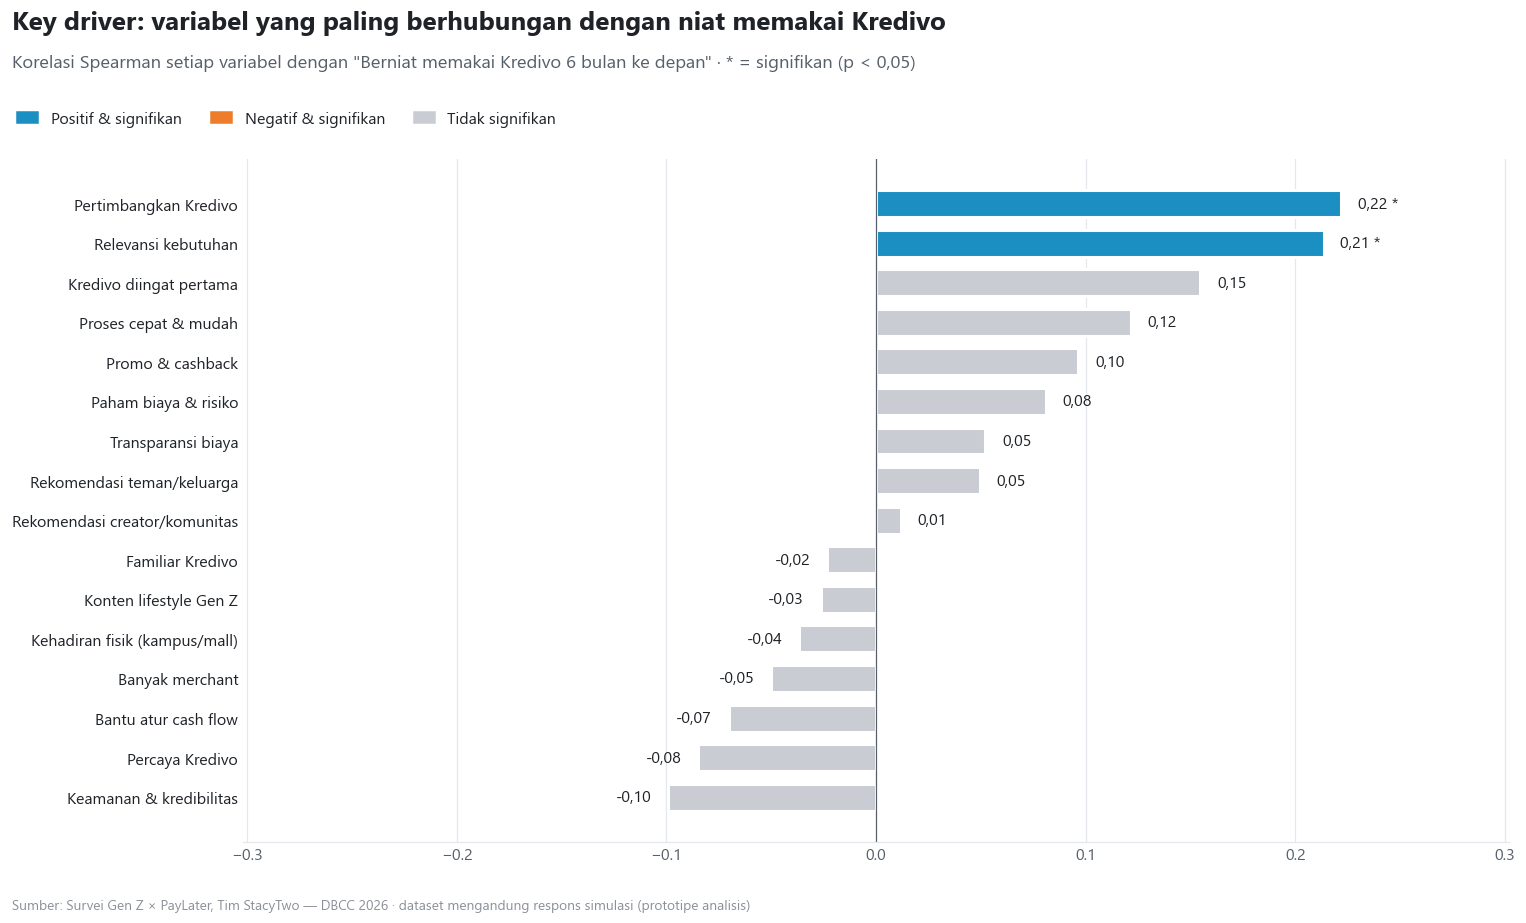

In [32]:
TARGET = 'k_intent'
kd = []
for c in LIKERT:
    if c == TARGET:
        continue
    r, p = stats.spearmanr(df[c], df[TARGET])
    kd.append({'kode': c, 'Variabel': LABEL_PENDEK[c], 'rho': r, 'p': p})
kd = pd.DataFrame(kd).sort_values('rho').reset_index(drop=True)
warna_kd = [BIRU if (p < 0.05 and r > 0) else ORANYE if (p < 0.05 and r < 0) else ABU for r, p in zip(kd.rho, kd.p)]
fig, ax = plt.subplots(figsize=(14, 8.5))
b = ax.barh(kd.index, kd.rho, color=warna_kd, height=0.68, edgecolor='white', linewidth=2)
for i, (r, p) in enumerate(zip(kd.rho, kd.p)):
    ax.text(r + (0.008 if r >= 0 else -0.008), i, f"{fnum(r, 2)}{' *' if p < 0.05 else ''}", va='center',
            ha='left' if r >= 0 else 'right', fontsize=10.5)
ax.set_yticks(kd.index, kd.Variabel)
ax.axvline(0, color=TEKS2, linewidth=0.8)
lim = max(0.3, kd.rho.abs().max() + 0.08)
ax.set_xlim(-lim, lim)
gaya(ax, 'x'); ax.spines['left'].set_visible(False)
signif = kd[(kd.p < 0.05) & (kd.rho > 0)].sort_values('rho', ascending=False)
bingkai(fig, 'Key driver: variabel yang paling berhubungan dengan niat memakai Kredivo',
        'Korelasi Spearman setiap variabel dengan "Berniat memakai Kredivo 6 bulan ke depan" · * = signifikan (p < 0,05)',
        legend=[Patch(color=BIRU, label='Positif & signifikan'), Patch(color=ORANYE, label='Negatif & signifikan'),
                Patch(color=ABU, label='Tidak signifikan')])
simpan(fig, '12b_key_driver_niat')

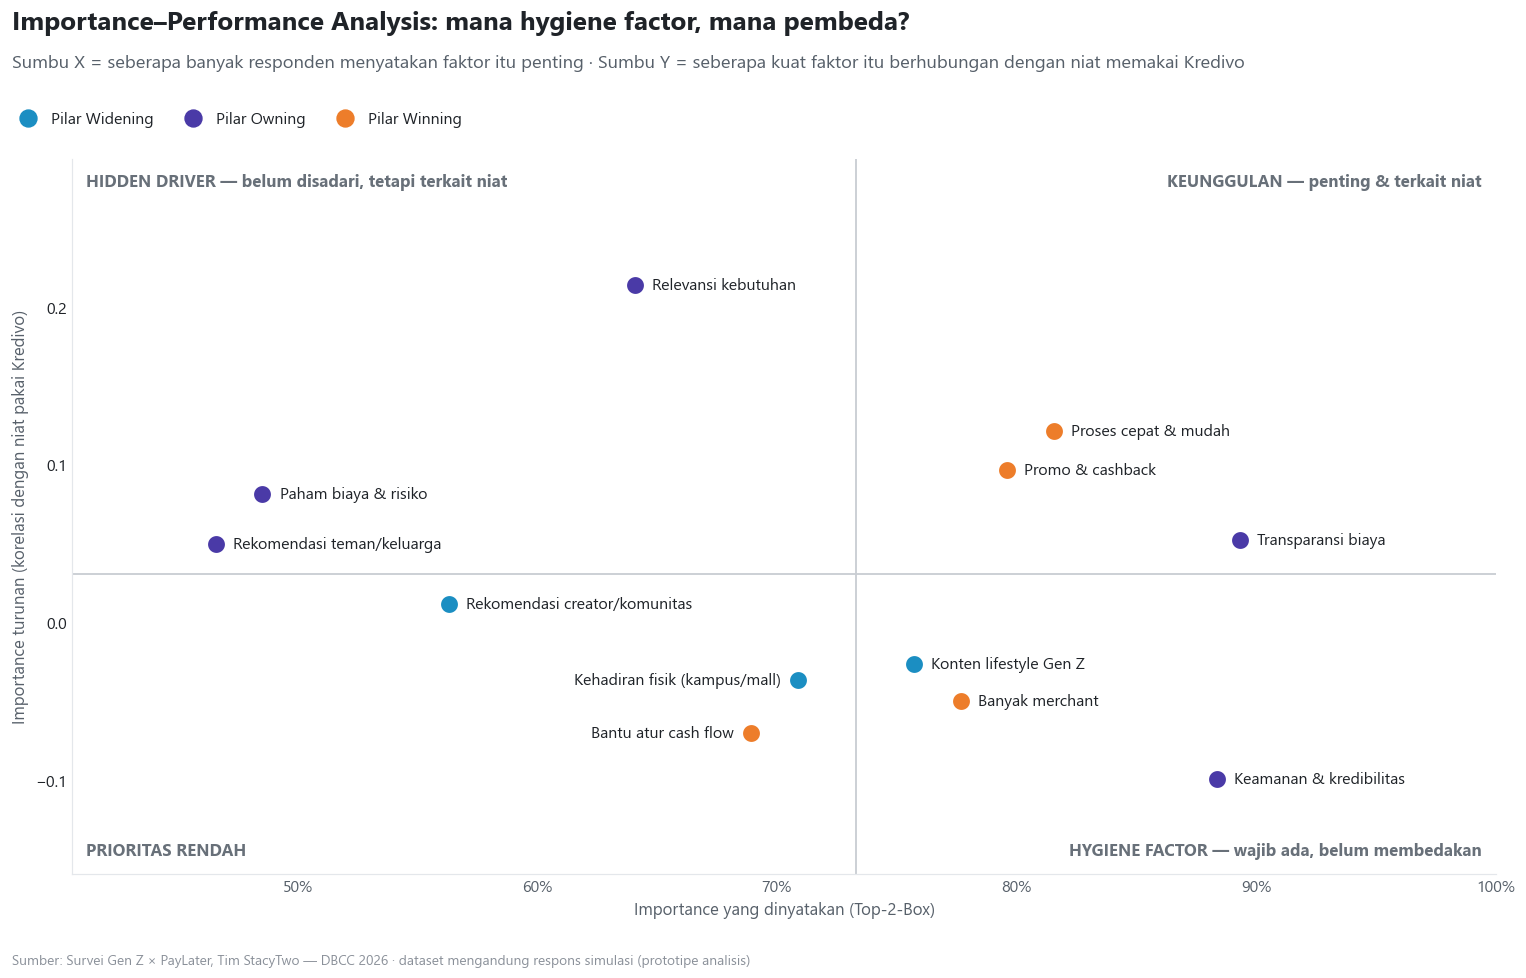

In [33]:
def label_sebar(ax, xs, ys, teks, jarak=0.045, dx=0.012, **kw):
    """Label titik scatter tanpa saling bertumpuk (geser vertikal sederhana)."""
    ax_pts = ax.transAxes.inverted().transform(ax.transData.transform(np.c_[xs, ys]))
    urut = np.argsort(ax_pts[:, 1])
    posisi = {}
    for i in urut:
        x, y = ax_pts[i]
        tetangga_kanan = any(0 < ax_pts[j, 0] - x < 0.2 and abs(ax_pts[j, 1] - y) < 0.05
                             for j in range(len(ax_pts)) if j != i)
        sisi = 'kiri' if tetangga_kanan else 'kanan'
        ly = y
        for _ in range(50):
            tabrak = [py for j, (px, py, s) in posisi.items()
                      if s == sisi and abs(px - x) < 0.22 and abs(py - ly) < jarak]
            if not tabrak:
                break
            ly = max(tabrak) + jarak
        posisi[i] = (x, ly, sisi)
        ax.annotate(teks[i], xy=(xs[i], ys[i]), xytext=(x + dx if sisi == 'kanan' else x - dx, ly),
                    textcoords='axes fraction', va='center', ha='left' if sisi == 'kanan' else 'right',
                    arrowprops=dict(arrowstyle='-', color=ABU, linewidth=0.8) if abs(ly - y) > 0.012 else None, **kw)

ipa = pd.DataFrame({'kode': LIKERT_SIKAP,
                    'x': [T2B[c] for c in LIKERT_SIKAP],
                    'y': [stats.spearmanr(df[c], df[TARGET])[0] for c in LIKERT_SIKAP]})
ipa['pilar'] = ipa.kode.map(WOW_MAP)
mx, my = ipa.x.median(), ipa.y.median()
fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(ipa.x.min() - 0.06, 1.0)
ax.set_ylim(ipa.y.min() - 0.06, ipa.y.max() + 0.08)
ax.axvline(mx, color=ABU, linewidth=1.2); ax.axhline(my, color=ABU, linewidth=1.2)
for pilar, c in PILAR_WARNA.items():
    d = ipa[ipa.pilar == pilar]
    ax.scatter(d.x, d.y, s=170, color=c, edgecolor='white', linewidth=2, zorder=3, label=f'Pilar {pilar}')
label_sebar(ax, ipa.x.values, ipa.y.values, [LABEL_PENDEK[c] for c in ipa.kode], fontsize=10.5, color=TEKS)
kw = dict(transform=ax.transAxes, fontsize=11, fontweight='bold', color=TEKS2, alpha=0.9)
ax.text(0.99, 0.98, 'KEUNGGULAN — penting & terkait niat', ha='right', va='top', **kw)
ax.text(0.99, 0.02, 'HYGIENE FACTOR — wajib ada, belum membedakan', ha='right', va='bottom', **kw)
ax.text(0.01, 0.98, 'HIDDEN DRIVER — belum disadari, tetapi terkait niat', ha='left', va='top', **kw)
ax.text(0.01, 0.02, 'PRIORITAS RENDAH', ha='left', va='bottom', **kw)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('Importance yang dinyatakan (Top-2-Box)')
ax.set_ylabel('Importance turunan (korelasi dengan niat pakai Kredivo)')
gaya(ax, None)
bingkai(fig, 'Importance–Performance Analysis: mana hygiene factor, mana pembeda?',
        'Sumbu X = seberapa banyak responden menyatakan faktor itu penting · Sumbu Y = seberapa kuat faktor itu berhubungan dengan niat memakai Kredivo',
        legend=[Line2D([], [], marker='o', linestyle='', markersize=11, color=c, label=f'Pilar {p}') for p, c in PILAR_WARNA.items()])
simpan(fig, '12c_importance_performance')

### 12.1 Uji statistik untuk memvalidasi gap
Setiap gap diuji dengan uji statistik yang sesuai jenis datanya: **Wilcoxon signed-rank** (membandingkan dua pernyataan pada responden yang sama), **Mann-Whitney U** (dua kelompok independen), **Kruskal-Wallis** (lebih dari dua kelompok), **Chi-square** (dua variabel kategorik) dan **Spearman** (hubungan ordinal).

In [34]:
def baris_uji(hipotesis, uji, stat, p, wow):
    return {'Hipotesis': hipotesis, 'Uji': uji, 'Statistik': fnum(stat, 3), 'p-value': p,
            'Kesimpulan (α = 0,05)': 'Signifikan ✔' if p < 0.05 else 'Belum signifikan', 'Relevansi WOW': wow}

hasil = []
w = stats.wilcoxon(df.k_familiar, df.k_recall)
hasil.append(baris_uji('Familiar > diingat pertama (Salience Gap)', 'Wilcoxon signed-rank', w.statistic, w.pvalue, 'Widening'))
w = stats.wilcoxon(df.transparan, df.paham)
hasil.append(baris_uji('Transparansi penting > paham biaya (Clarity Gap)', 'Wilcoxon signed-rank', w.statistic, w.pvalue, 'Owning — Smart Choice'))
w = stats.wilcoxon(df.k_trust, df.k_intent)
hasil.append(baris_uji('Percaya > niat pakai (trust belum jadi aksi)', 'Wilcoxon signed-rank', w.statistic, w.pvalue, 'Winning'))
w = stats.wilcoxon(df.promo, df.k_intent)
hasil.append(baris_uji('Dorongan promo > niat pakai Kredivo (Activation Gap)', 'Wilcoxon signed-rank', w.statistic, w.pvalue, 'Winning — NOW & Deals'))
m = stats.mannwhitneyu(df.loc[df.tom_kredivo, 'k_trust'], df.loc[~df.tom_kredivo, 'k_trust'])
hasil.append(baris_uji('Trust berbeda: ingat Kredivo pertama vs tidak', 'Mann-Whitney U', m.statistic, m.pvalue, 'Widening + Owning'))
k = stats.kruskal(*[df.loc[df.grup_pengguna == g, 'k_intent'] for g in ORDER['grup_pengguna']])
hasil.append(baris_uji('Niat pakai Kredivo berbeda antar status PayLater', 'Kruskal-Wallis', k.statistic, k.pvalue, 'Winning — targeting'))
m = stats.mannwhitneyu(df.loc[df.target_inti, 'k_consider'], df.loc[~df.target_inti, 'k_consider'])
hasil.append(baris_uji('Pertimbangan Kredivo berbeda: Target Inti vs lainnya', 'Mann-Whitney U', m.statistic, m.pvalue, 'Owning — targeting Raka'))
c = uji_chi('hambatan', 'grup_pengguna')
hasil.append(baris_uji('Hambatan utama berbeda antar status PayLater', 'Chi-square', c['chi2'], c['p-value'], 'Owning + Winning'))
c = uji_chi('tom_kredivo', 'status')
hasil.append(baris_uji('Top-of-mind Kredivo berbeda antar status pekerjaan', 'Chi-square', c['chi2'], c['p-value'], 'Widening — targeting'))
r = stats.spearmanr(df.relevan, df.k_intent)
hasil.append(baris_uji('Relevansi kebutuhan berhubungan dengan niat pakai', 'Spearman', r.statistic, r.pvalue, 'Owning — Kredivo Fit'))
uji_df = pd.DataFrame(hasil)
uji_df['p-value'] = uji_df['p-value'].map(lambda p: '< 0,001' if p < 0.001 else fnum(p, 3))
display(uji_df.style.hide(axis='index'))

insight('Insight analisis hubungan', [
    ('Variabel yang berhubungan positif & signifikan dengan niat pakai Kredivo: ' + ', '.join(f"**{r.Variabel}** (ρ = {fnum(r.rho, 2)})" for _, r in signif.iterrows()) + '.')
    if len(signif) else 'Belum ada variabel yang berhubungan signifikan dengan niat pakai — konsisten dengan catatan integritas data.',
    f"**Relevansi kebutuhan** adalah driver sikap terkuat untuk niat pakai (ρ = {fnum(ipa.set_index('kode').loc['relevan', 'y'], 2)}) → Kredivo harus terasa *relevan secara personal*, bukan sekadar ada di mana-mana: ini peran **Kredivo Fit** dan **Kredivo NOW**.",
    'Faktor dengan T2B tinggi tetapi korelasi rendah dengan niat (' + ', '.join(f"**{LABEL_PENDEK[c].lower()}**" for c in ipa[(ipa.x >= mx) & (ipa.y < my)].kode) + ') berada di kuadran **hygiene factor**: wajib dipenuhi untuk masuk *consideration set*, tetapi tidak cukup untuk memenangkan preferensi → mendukung root cause **Low Functional Differentiation**.',
    ('Uji Wilcoxon menunjukkan tiga kesenjangan utama (**familiar vs diingat**, **transparansi vs pemahaman**, **dorongan promo vs niat pakai**) signifikan secara statistik — fondasi kuantitatif untuk Salience, Preference dan Activation Gap.'
     if all(stats.wilcoxon(df[a], df[b]).pvalue < 0.05 for a, b in [('k_familiar', 'k_recall'), ('transparan', 'paham'), ('promo', 'k_intent')])
     else 'Belum semua kesenjangan utama signifikan secara statistik — periksa tabel uji di atas sebelum mengklaim gap di pitch deck.'),
])

Hipotesis,Uji,Statistik,p-value,"Kesimpulan (α = 0,05)",Relevansi WOW
Familiar > diingat pertama (Salience Gap),Wilcoxon signed-rank,"388,500","< 0,001",Signifikan ✔,Widening
Transparansi penting > paham biaya (Clarity Gap),Wilcoxon signed-rank,"293,000","< 0,001",Signifikan ✔,Owning — Smart Choice
Percaya > niat pakai (trust belum jadi aksi),Wilcoxon signed-rank,"895,500","0,004",Signifikan ✔,Winning
Dorongan promo > niat pakai Kredivo (Activation Gap),Wilcoxon signed-rank,"510,000","< 0,001",Signifikan ✔,Winning — NOW & Deals
Trust berbeda: ingat Kredivo pertama vs tidak,Mann-Whitney U,"562,500","0,010",Signifikan ✔,Widening + Owning
Niat pakai Kredivo berbeda antar status PayLater,Kruskal-Wallis,"15,324","0,002",Signifikan ✔,Winning — targeting
Pertimbangan Kredivo berbeda: Target Inti vs lainnya,Mann-Whitney U,"849,000","0,002",Signifikan ✔,Owning — targeting Raka
Hambatan utama berbeda antar status PayLater,Chi-square,"38,410","0,003",Signifikan ✔,Owning + Winning
Top-of-mind Kredivo berbeda antar status pekerjaan,Chi-square,"8,600","0,035",Signifikan ✔,Widening — targeting
Relevansi kebutuhan berhubungan dengan niat pakai,Spearman,"0,213","0,030",Signifikan ✔,Owning — Kredivo Fit


> ### 💡 Insight analisis hubungan
>
> - Variabel yang berhubungan positif & signifikan dengan niat pakai Kredivo: **Pertimbangkan Kredivo** (ρ = 0,22), **Relevansi kebutuhan** (ρ = 0,21).
> - **Relevansi kebutuhan** adalah driver sikap terkuat untuk niat pakai (ρ = 0,21) → Kredivo harus terasa *relevan secara personal*, bukan sekadar ada di mana-mana: ini peran **Kredivo Fit** dan **Kredivo NOW**.
> - Faktor dengan T2B tinggi tetapi korelasi rendah dengan niat (**keamanan & kredibilitas**, **banyak merchant**, **konten lifestyle gen z**) berada di kuadran **hygiene factor**: wajib dipenuhi untuk masuk *consideration set*, tetapi tidak cukup untuk memenangkan preferensi → mendukung root cause **Low Functional Differentiation**.
> - Uji Wilcoxon menunjukkan tiga kesenjangan utama (**familiar vs diingat**, **transparansi vs pemahaman**, **dorongan promo vs niat pakai**) signifikan secara statistik — fondasi kuantitatif untuk Salience, Preference dan Activation Gap.

## 13. Segmentasi Responden (K-Means Clustering)
Tujuan: menemukan **kelompok Gen Z dengan pola sikap yang mirip** terhadap PayLater, sehingga WOW Strategy bisa dieksekusi dengan pesan yang berbeda untuk setiap kelompok.

**Metode:** 12 pernyataan sikap distandardisasi (z-score) → K-Means dengan *k* = 2–7 dievaluasi memakai *elbow (inertia)* dan *silhouette score* → dipilih **k = 4** karena paling mudah diinterpretasikan menjadi persona yang dapat dieksekusi. Nama segmen diberikan berdasarkan ciri pembeda utama tiap cluster.

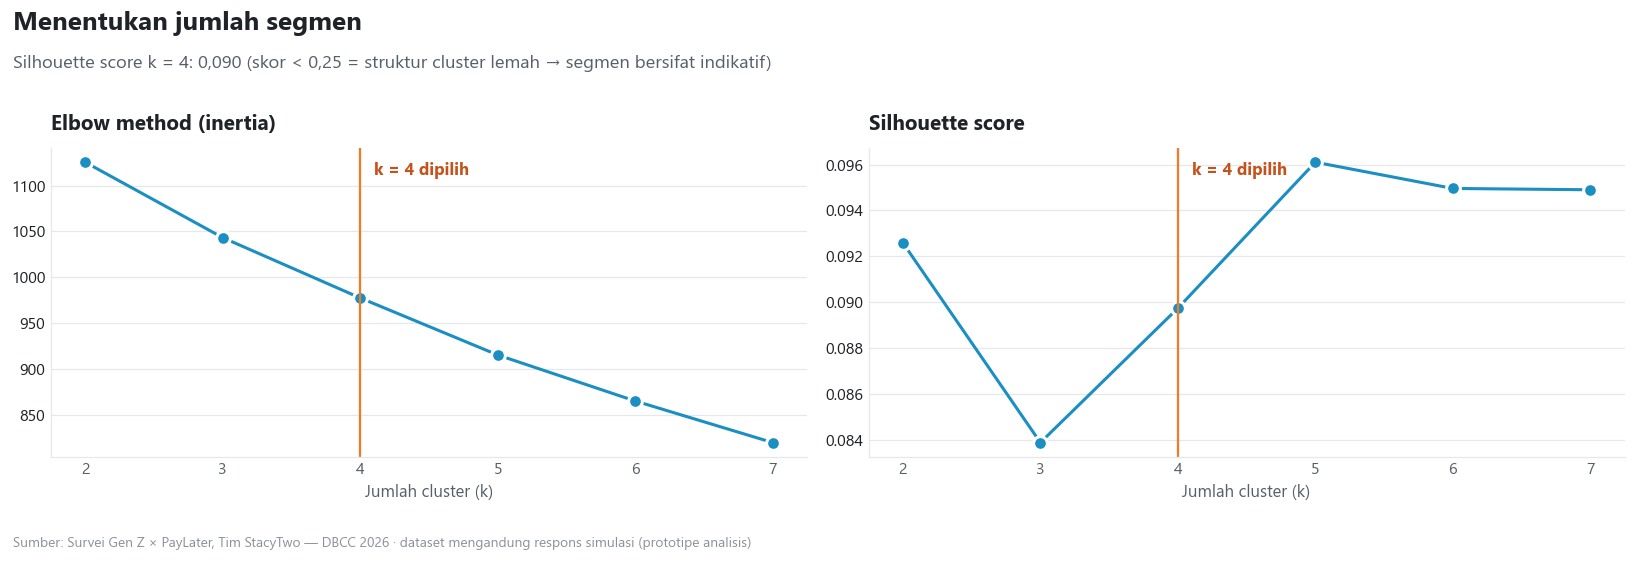

In [35]:
X = StandardScaler().fit_transform(df[LIKERT_SIKAP])
ks = list(range(2, 8))
inertia, sil = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    inertia.append(km_k.inertia_); sil.append(silhouette_score(X, km_k.labels_))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, val, judul in [(ax1, inertia, 'Elbow method (inertia)'), (ax2, sil, 'Silhouette score')]:
    ax.plot(ks, val, color=BIRU, linewidth=2, marker='o', markersize=9, markeredgecolor='white', markeredgewidth=2)
    ax.axvline(4, color=ORANYE, linewidth=1.5)
    ax.text(4.1, max(val), 'k = 4 dipilih', color=ORANYE_TUA, fontweight='bold', va='top')
    ax.set_xticks(ks); ax.set_xlabel('Jumlah cluster (k)'); ax.set_title(judul)
    gaya(ax, 'y')
bingkai(fig, 'Menentukan jumlah segmen', f'Silhouette score k = 4: {fnum(sil[ks.index(4)], 3)} (skor < 0,25 = struktur cluster lemah → segmen bersifat indikatif)')
simpan(fig, '13a_pemilihan_k')

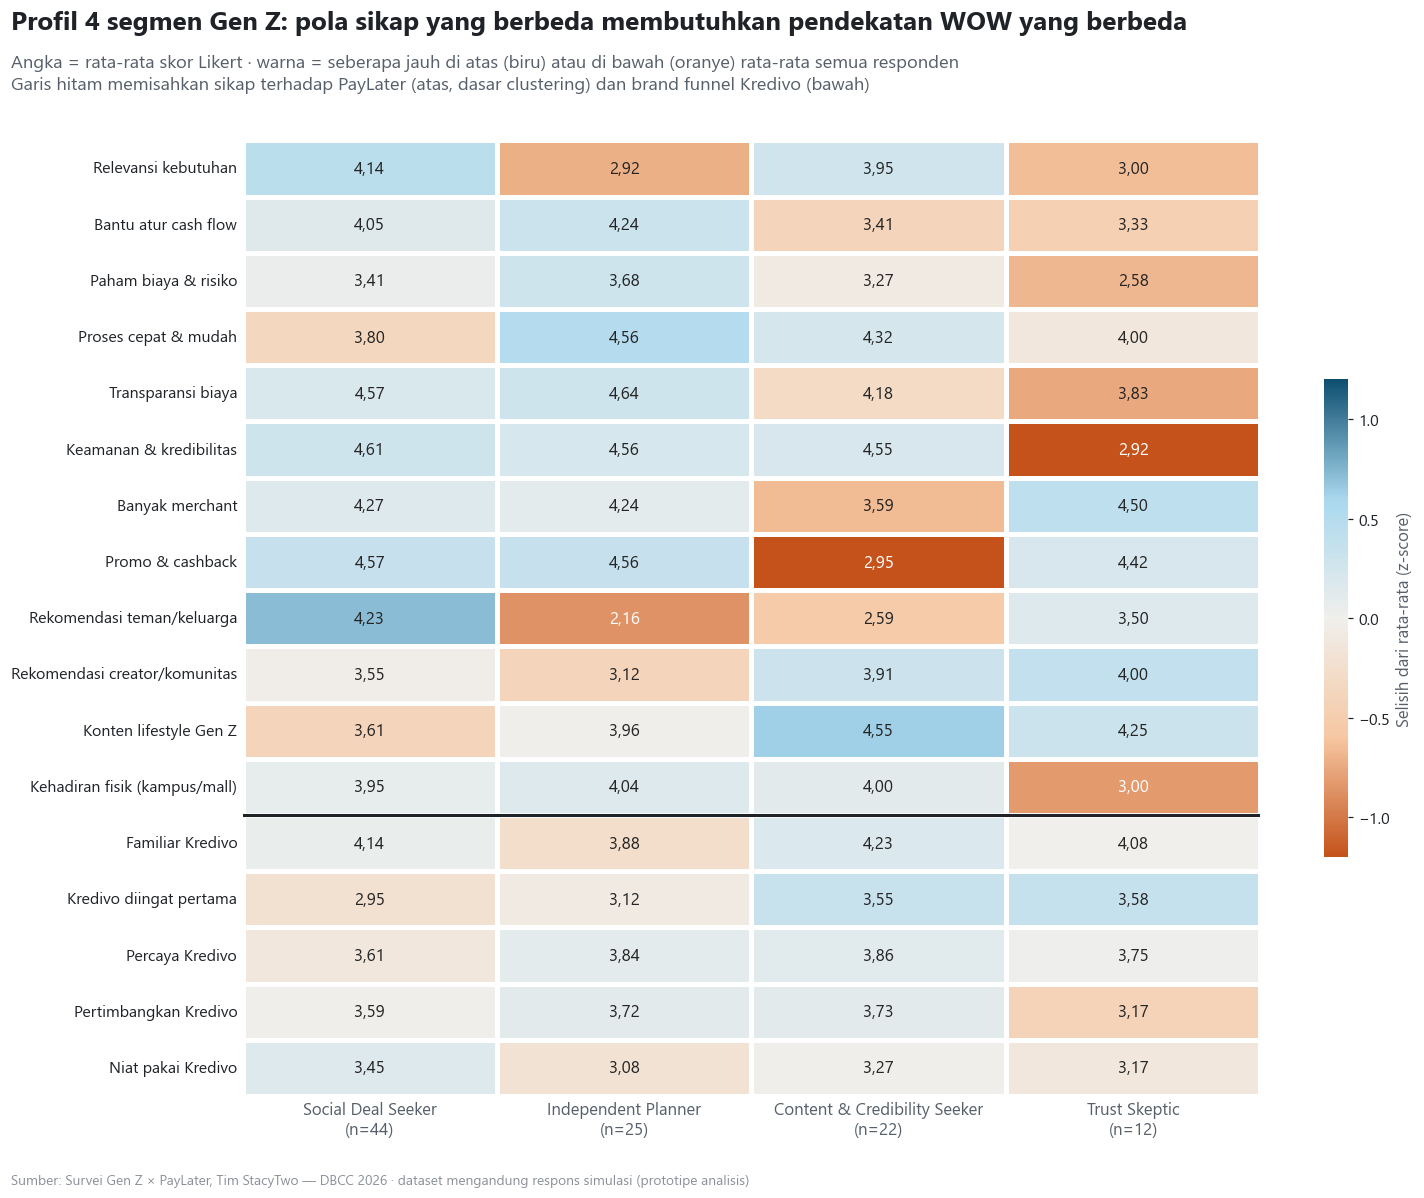

In [36]:
K_SEGMEN = 4
km = KMeans(n_clusters=K_SEGMEN, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_
prof = df.groupby('cluster')[LIKERT_SIKAP].mean()

nama, sisa_cl = {}, list(prof.index)
for kolom, fungsi, label in [('teman', 'idxmax', 'Social Deal Seeker'), ('aman', 'idxmin', 'Trust Skeptic'),
                             ('promo', 'idxmin', 'Content & Credibility Seeker')]:
    c = getattr(prof.loc[sisa_cl, kolom], fungsi)(); nama[c] = label; sisa_cl.remove(c)
nama[sisa_cl[0]] = 'Independent Planner'
df['segmen'] = df['cluster'].map(nama)
SEG_ORDER = ['Social Deal Seeker', 'Independent Planner', 'Content & Credibility Seeker', 'Trust Skeptic']
SEG_WARNA = dict(zip(SEG_ORDER, KATEGORI))
SEG_MARKER = dict(zip(SEG_ORDER, ['o', 's', '^', 'D']))
SEG_WOW = {
    'Social Deal Seeker': 'Winning — Kredivo Deals + WOW Loop (referral) · Widening — Kredivo Community',
    'Independent Planner': 'Owning — Smart Choice · Winning — Kredivo NOW di momen cash flow',
    'Content & Credibility Seeker': 'Widening — WOW Content + Kredivo Spots · Owning — Kredivo Proof',
    'Trust Skeptic': 'Owning — Kredivo Proof + Smart Choice (edukasi biaya & keamanan)',
}

prof_all = df.groupby('segmen')[LIKERT].mean().reindex(SEG_ORDER).T
z = df.groupby('segmen')[LIKERT].mean().reindex(SEG_ORDER)
z = ((z - df[LIKERT].mean()) / df[LIKERT].std()).T
prof_all.index = z.index = [LABEL_PENDEK[c] for c in LIKERT]
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(z, cmap=CMAP_DIV, center=0, vmin=-1.2, vmax=1.2, annot=prof_all.map(lambda v: fnum(v, 2)), fmt='',
            linewidths=2, linecolor='white', cbar_kws={'shrink': 0.5, 'label': 'Selisih dari rata-rata (z-score)'},
            ax=ax, annot_kws={'fontsize': 11})
ax.axhline(len(LIKERT_SIKAP), color=TEKS, linewidth=2)
ax.set_xticklabels([f"{s}\n(n={(df.segmen == s).sum()})" for s in SEG_ORDER], rotation=0, fontsize=11)
ax.tick_params(length=0); ax.set_xlabel(''); ax.set_ylabel('')
bingkai(fig, 'Profil 4 segmen Gen Z: pola sikap yang berbeda membutuhkan pendekatan WOW yang berbeda',
        'Angka = rata-rata skor Likert · warna = seberapa jauh di atas (biru) atau di bawah (oranye) rata-rata semua responden\n'
        'Garis hitam memisahkan sikap terhadap PayLater (atas, dasar clustering) dan brand funnel Kredivo (bawah)')
simpan(fig, '13b_profil_segmen')

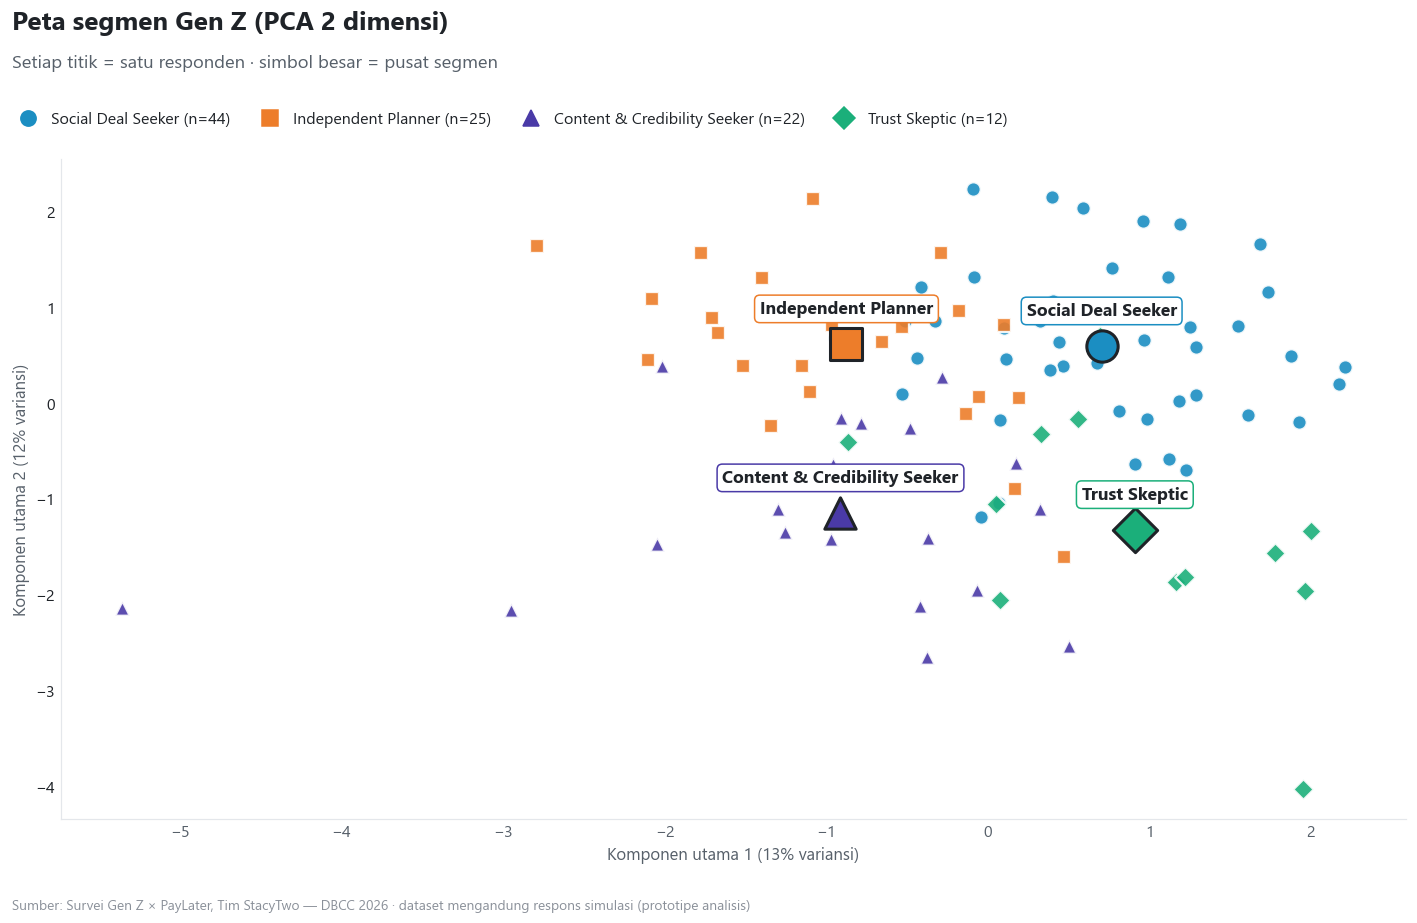

In [37]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(13, 8.5))
for s in SEG_ORDER:
    m = (df.segmen == s).values
    ax.scatter(P[m, 0], P[m, 1], s=90, marker=SEG_MARKER[s], color=SEG_WARNA[s], edgecolor='white', linewidth=1.5,
               alpha=0.9, label=f'{s} (n={m.sum()})', zorder=3)
    cx, cy = P[m, 0].mean(), P[m, 1].mean()
    ax.scatter(cx, cy, s=420, marker=SEG_MARKER[s], color=SEG_WARNA[s], edgecolor=TEKS, linewidth=2, zorder=4)
    ax.annotate(s, (cx, cy), xytext=(0, 20), textcoords='offset points', ha='center', fontsize=11.5, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=SEG_WARNA[s]), zorder=5)
ax.set_xlabel(f'Komponen utama 1 ({pca.explained_variance_ratio_[0]:.0%} variansi)')
ax.set_ylabel(f'Komponen utama 2 ({pca.explained_variance_ratio_[1]:.0%} variansi)')
gaya(ax, None)
bingkai(fig, 'Peta segmen Gen Z (PCA 2 dimensi)', 'Setiap titik = satu responden · simbol besar = pusat segmen',
        legend=[Line2D([], [], marker=SEG_MARKER[s], linestyle='', markersize=10, color=SEG_WARNA[s],
                       label=f'{s} (n={(df.segmen == s).sum()})') for s in SEG_ORDER])
simpan(fig, '13c_peta_segmen_pca')

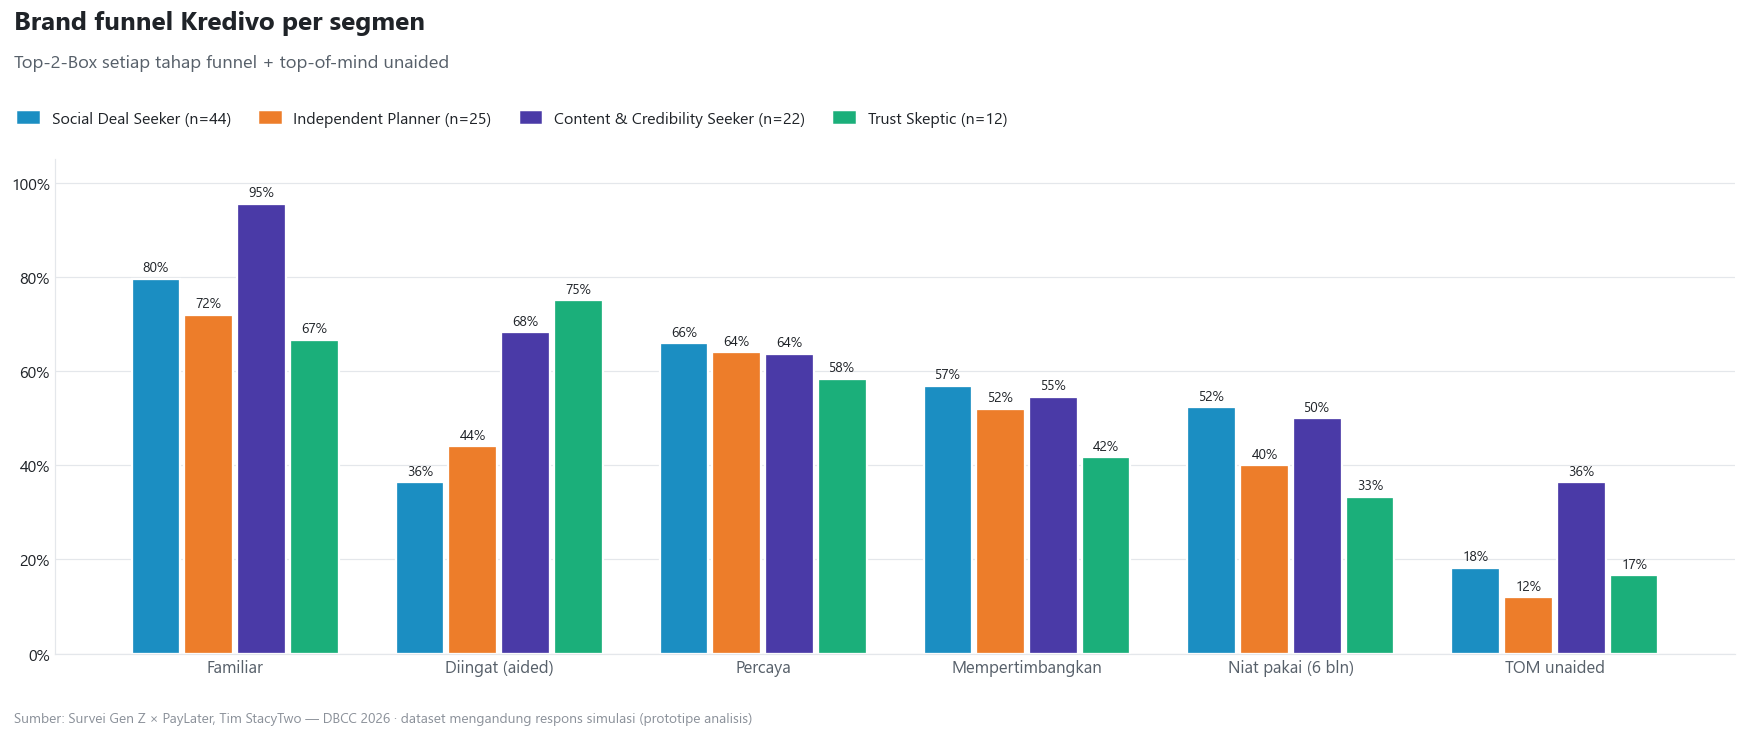

In [38]:
x = np.arange(len(FUNNEL) + 1); w = 0.2
fig, ax = plt.subplots(figsize=(16, 6.8))
for j, s in enumerate(SEG_ORDER):
    d = df[df.segmen == s]
    vals = [d[f'{k}_t2b'].mean() for k, _, _, _ in FUNNEL] + [d.tom_kredivo.mean()]
    b = ax.bar(x + (j - 1.5) * w, vals, w * 0.92, color=SEG_WARNA[s], edgecolor='white', linewidth=1.5)
    ax.bar_label(b, [fpct(v) for v in vals], padding=3, fontsize=9)
ax.set_xticks(x, [t for _, t, _, _ in FUNNEL] + ['TOM unaided'], fontsize=11)
ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'y')
bingkai(fig, 'Brand funnel Kredivo per segmen', 'Top-2-Box setiap tahap funnel + top-of-mind unaided',
        legend=[Patch(color=SEG_WARNA[s], label=f'{s} (n={(df.segmen == s).sum()})') for s in SEG_ORDER])
simpan(fig, '13d_funnel_per_segmen')

In [39]:
zs = df.groupby('segmen')[LIKERT_SIKAP].mean().reindex(SEG_ORDER)
zs = (zs - df[LIKERT_SIKAP].mean()) / df[LIKERT_SIKAP].std()
persona = []
for s in SEG_ORDER:
    d = df[df.segmen == s]
    persona.append({
        'Segmen': s, 'n': len(d), '% sampel': fpct(len(d) / N),
        'Paling menonjol (di atas rata-rata)': ', '.join(LABEL_PENDEK[c] for c in zs.loc[s].nlargest(3).index),
        'Paling lemah (di bawah rata-rata)': ', '.join(LABEL_PENDEK[c] for c in zs.loc[s].nsmallest(2).index),
        'Status dominan': d.status.value_counts().index[0],
        '% Target Inti': fpct(d.target_inti.mean()),
        'TOM Kredivo': fpct(d.tom_kredivo.mean()),
        'Niat pakai (T2B)': fpct(d.k_intent_t2b.mean()),
        'Hambatan utama': d.hambatan.value_counts().index[0],
        'Kebutuhan utama': KEBUTUHAN.loc[d.index].mean().idxmax(),
        'Pendekatan WOW': SEG_WOW[s],
    })
persona_df = pd.DataFrame(persona)
display(persona_df.style.hide(axis='index'))

terbesar = persona_df.sort_values('n', ascending=False).iloc[0]
insight('Insight segmentasi', [
    f"Empat segmen sikap teridentifikasi; segmen terbesar adalah **{terbesar.Segmen}** ({terbesar['% sampel']} sampel).",
    '**Social Deal Seeker** → digerakkan teman & promo: aktivasi lewat **Kredivo Deals** dan referral di **WOW Loop**, diperkuat **Community**.',
    '**Independent Planner** → rasional, fokus cash flow & transparansi, tidak ikut-ikutan: menang lewat **Smart Choice** (simulasi tenor & total biaya) dan penawaran **Kredivo NOW** di momen cash-flow.',
    '**Content & Credibility Seeker** → tidak tergerak promo, tetapi responsif pada konten & kredibilitas: sasaran utama **WOW Content** dan **Kredivo Spots**, dengan **Proof** sebagai penguat.',
    '**Trust Skeptic** → ragu keamanan & belum paham biaya: tidak akan bergerak tanpa **Kredivo Proof** dan edukasi **Smart Choice**; jangan diserang dengan promo agresif.',
    f"Karena silhouette score rendah ({fnum(sil[ks.index(4)], 3)}), segmen ini dipakai sebagai **kerangka persona untuk pesan & kanal**, bukan pembagian pasar yang kaku.",
])

Segmen,n,% sampel,Paling menonjol (di atas rata-rata),Paling lemah (di bawah rata-rata),Status dominan,% Target Inti,TOM Kredivo,Niat pakai (T2B),Hambatan utama,Kebutuhan utama,Pendekatan WOW
Social Deal Seeker,44,43%,"Rekomendasi teman/keluarga, Relevansi kebutuhan, Promo & cashback","Konten lifestyle Gen Z, Proses cepat & mudah",Pelajar/Mahasiswa,36%,18%,52%,Khawatir terhadap bunga atau biaya tambahan,Gadget & elektronik,Winning — Kredivo Deals + WOW Loop (referral) · Widening — Kredivo Community
Independent Planner,25,24%,"Proses cepat & mudah, Promo & cashback, Bantu atur cash flow","Rekomendasi teman/keluarga, Relevansi kebutuhan",Karyawan,40%,12%,40%,Khawatir terhadap bunga atau biaya tambahan,Pendidikan/kebutuhan kerja,Owning — Smart Choice · Winning — Kredivo NOW di momen cash flow
Content & Credibility Seeker,22,21%,"Konten lifestyle Gen Z, Rekomendasi creator/komunitas, Relevansi kebutuhan","Promo & cashback, Banyak merchant",Pelajar/Mahasiswa,50%,36%,50%,Khawatir terhadap bunga atau biaya tambahan,Gadget & elektronik,Widening — WOW Content + Kredivo Spots · Owning — Kredivo Proof
Trust Skeptic,12,12%,"Banyak merchant, Rekomendasi creator/komunitas, Konten lifestyle Gen Z","Keamanan & kredibilitas, Kehadiran fisik (kampus/mall)",Karyawan,42%,17%,33%,Khawatir terhadap bunga atau biaya tambahan,Gadget & elektronik,Owning — Kredivo Proof + Smart Choice (edukasi biaya & keamanan)


> ### 💡 Insight segmentasi
>
> - Empat segmen sikap teridentifikasi; segmen terbesar adalah **Social Deal Seeker** (43% sampel).
> - **Social Deal Seeker** → digerakkan teman & promo: aktivasi lewat **Kredivo Deals** dan referral di **WOW Loop**, diperkuat **Community**.
> - **Independent Planner** → rasional, fokus cash flow & transparansi, tidak ikut-ikutan: menang lewat **Smart Choice** (simulasi tenor & total biaya) dan penawaran **Kredivo NOW** di momen cash-flow.
> - **Content & Credibility Seeker** → tidak tergerak promo, tetapi responsif pada konten & kredibilitas: sasaran utama **WOW Content** dan **Kredivo Spots**, dengan **Proof** sebagai penguat.
> - **Trust Skeptic** → ragu keamanan & belum paham biaya: tidak akan bergerak tanpa **Kredivo Proof** dan edukasi **Smart Choice**; jangan diserang dengan promo agresif.
> - Karena silhouette score rendah (0,090), segmen ini dipakai sebagai **kerangka persona untuk pesan & kanal**, bukan pembagian pasar yang kaku.

## 14. Deep Dive Target Inti — Gen Z Surabaya yang Mulai Mandiri Finansial (Persona Raka)
WOW Strategy menargetkan **Gen Z Surabaya yang sedang memasuki kemandirian finansial** (persona *Raka, 22 tahun, mahasiswa tingkat akhir & intern*). Dalam survei, kelompok ini kami definisikan sebagai responden **berdomisili di Surabaya dengan penghasilan pribadi ≥ Rp1 juta/bulan**. Bagian ini membandingkan mereka dengan responden lain untuk menguji: *apakah target ini memang tepat, dan apa yang paling mereka butuhkan?*

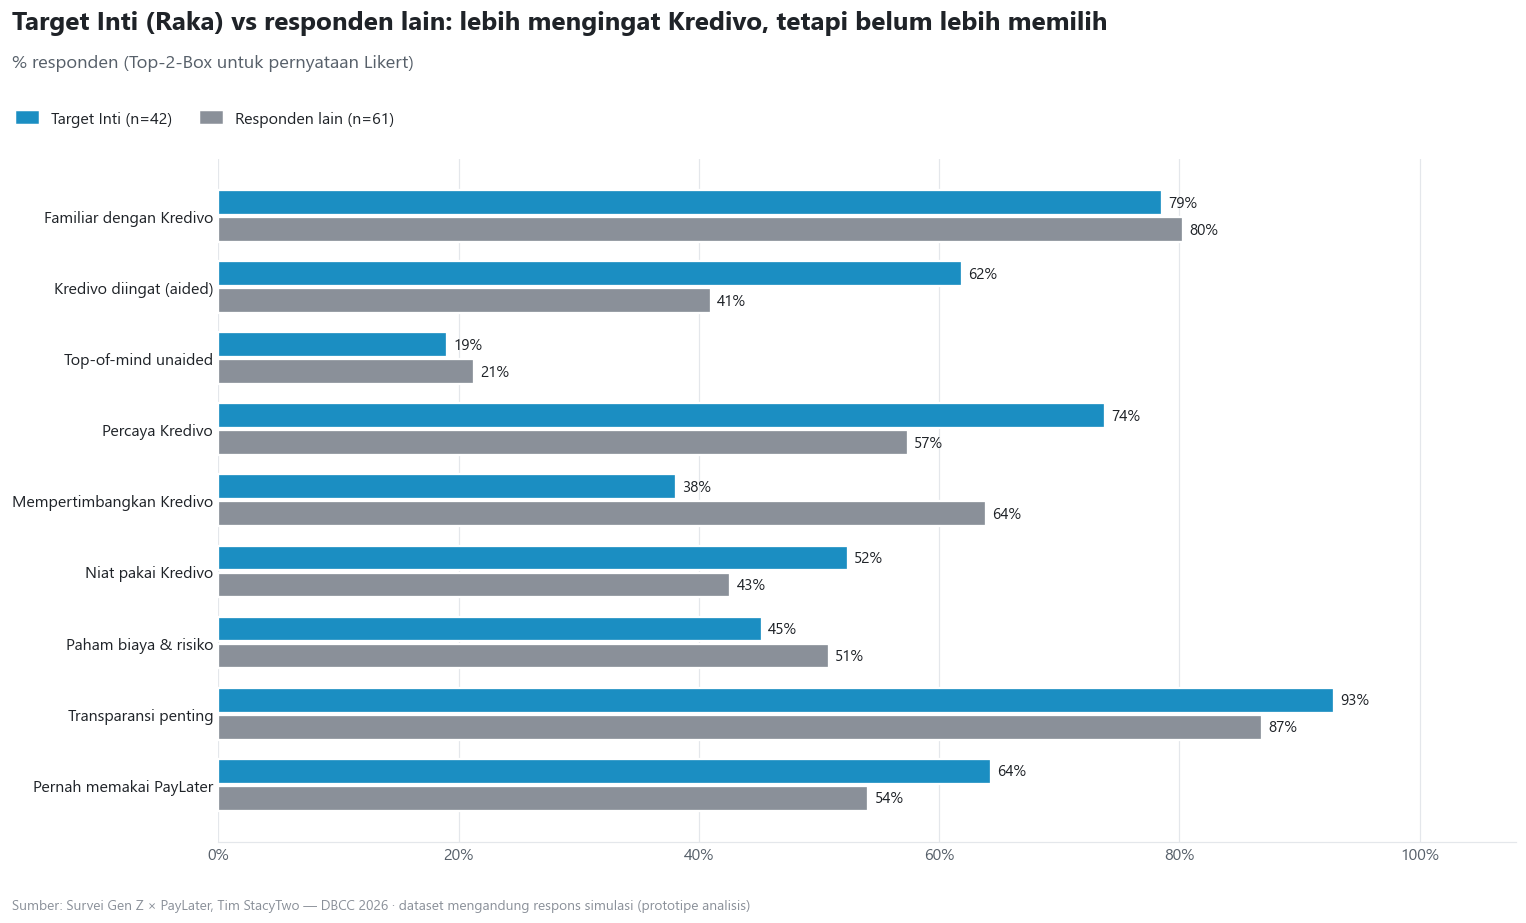

In [40]:
ti, lain = df[df.target_inti], df[~df.target_inti]
metrik_ti = {
    'Familiar dengan Kredivo': 'k_familiar_t2b', 'Kredivo diingat (aided)': 'k_recall_t2b', 'Top-of-mind unaided': 'tom_kredivo',
    'Percaya Kredivo': 'k_trust_t2b', 'Mempertimbangkan Kredivo': 'k_consider_t2b', 'Niat pakai Kredivo': 'k_intent_t2b',
    'Paham biaya & risiko': 'paham_t2b', 'Transparansi penting': 'transparan_t2b', 'Pernah memakai PayLater': 'pernah_pakai',
}
cmp_ti = pd.DataFrame({f'Target Inti (n={len(ti)})': {k: ti[v].mean() for k, v in metrik_ti.items()},
                       f'Responden lain (n={len(lain)})': {k: lain[v].mean() for k, v in metrik_ti.items()}}).iloc[::-1]
fig, ax = plt.subplots(figsize=(14, 8.5))
yy = np.arange(len(cmp_ti)); h = 0.38
for j, (col, c) in enumerate(zip(cmp_ti.columns[::-1], [ABU_TUA, BIRU])):
    b = ax.barh(yy + (j - 0.5) * h, cmp_ti[col], h * 0.92, color=c, label=col, edgecolor='white', linewidth=1.5)
    ax.bar_label(b, [fpct(v) for v in cmp_ti[col]], padding=4, fontsize=10)
ax.set_yticks(yy, cmp_ti.index)
ax.set_xlim(0, 1.08); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
gaya(ax, 'x'); ax.spines['left'].set_visible(False)
bingkai(fig, 'Target Inti (Raka) vs responden lain: lebih mengingat Kredivo, tetapi belum lebih memilih',
        '% responden (Top-2-Box untuk pernyataan Likert)',
        legend=[Patch(color=BIRU, label=cmp_ti.columns[0]), Patch(color=ABU_TUA, label=cmp_ti.columns[1])])
simpan(fig, '14a_target_inti_vs_lain')

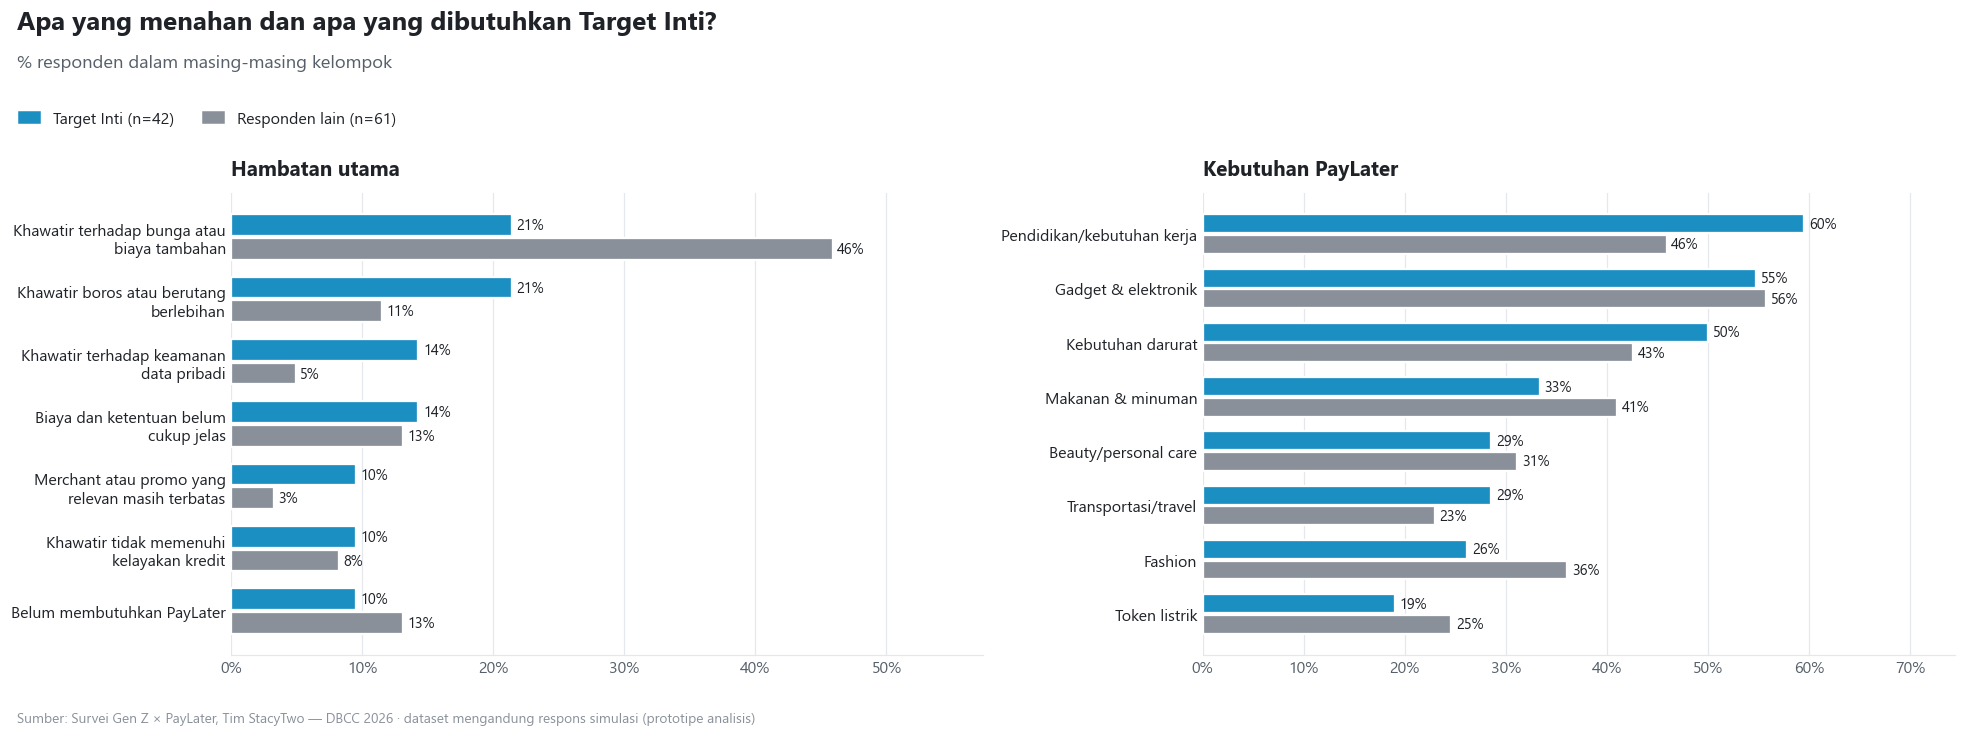

> ### 💡 Insight Target Inti (Persona Raka)
>
> - Target Inti mencakup **42 responden (41%)** — cukup besar untuk dianalisis dan sesuai logika *financially emerging Gen Z* yang *eligible* kredit.
> - Target Inti **lebih mengingat** Kredivo (aided recall 62% vs 41%), namun **pertimbangan** memakai Kredivo justru lebih rendah (38% vs 64%) → untuk Raka, masalah utamanya adalah **Preference Gap**: dikenal & diingat, tetapi belum menjadi pilihan.
> - Clarity Gap Target Inti **48 pp** (transparansi penting 93% vs paham 45%) — lebih lebar dari rata-rata (41 pp) → **Smart Choice** paling relevan untuk persona Raka.
> - Hambatan teratas Target Inti: **Khawatir terhadap bunga atau biaya tambahan** (21%), **Khawatir boros atau berutang berlebihan** (21%), **Khawatir terhadap keamanan data pribadi** (14%) → sesuai pain point Raka: khawatir bunga, overspending, dan keamanan. Pesan yang tepat: **"fleksibel, tapi tetap terkendali"** (*Responsible Financial Flexibility*).

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.8))
for ax, data_fn, judul in [
    (ax1, lambda d: d.hambatan.value_counts(normalize=True), 'Hambatan utama'),
    (ax2, lambda d: KEBUTUHAN.loc[d.index].mean(), 'Kebutuhan PayLater'),
]:
    t = pd.DataFrame({'Target Inti': data_fn(ti), 'Responden lain': data_fn(lain)}).fillna(0).sort_values('Target Inti')
    yy = np.arange(len(t)); h = 0.38
    for j, (col, c) in enumerate(zip(['Responden lain', 'Target Inti'], [ABU_TUA, BIRU])):
        b = ax.barh(yy + (j - 0.5) * h, t[col], h * 0.92, color=c, edgecolor='white', linewidth=1.5)
        ax.bar_label(b, [fpct(v) for v in t[col]], padding=3, fontsize=9.5)
    ax.set_yticks(yy, [wrap(i, 30) for i in t.index])
    ax.set_xlim(0, t.values.max() * 1.25); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    gaya(ax, 'x'); ax.spines['left'].set_visible(False); ax.set_title(judul)
bingkai(fig, 'Apa yang menahan dan apa yang dibutuhkan Target Inti?', '% responden dalam masing-masing kelompok',
        legend=[Patch(color=BIRU, label=f'Target Inti (n={len(ti)})'), Patch(color=ABU_TUA, label=f'Responden lain (n={len(lain)})')])
simpan(fig, '14b_target_inti_hambatan_kebutuhan')

hb_ti = ti.hambatan.value_counts(normalize=True)
insight('Insight Target Inti (Persona Raka)', [
    f"Target Inti mencakup **{len(ti)} responden ({fpct(len(ti) / N)})** — cukup besar untuk dianalisis dan sesuai logika *financially emerging Gen Z* yang *eligible* kredit.",
    f"Target Inti **lebih mengingat** Kredivo (aided recall {fpct(ti.k_recall_t2b.mean())} vs {fpct(lain.k_recall_t2b.mean())}), namun **pertimbangan** memakai Kredivo justru {'lebih rendah' if ti.k_consider_t2b.mean() < lain.k_consider_t2b.mean() else 'tidak jauh berbeda'} ({fpct(ti.k_consider_t2b.mean())} vs {fpct(lain.k_consider_t2b.mean())}) → untuk Raka, masalah utamanya adalah **Preference Gap**: dikenal & diingat, tetapi belum menjadi pilihan.",
    f"Clarity Gap Target Inti **{(ti.transparan_t2b.mean() - ti.paham_t2b.mean()) * 100:.0f} pp** (transparansi penting {fpct(ti.transparan_t2b.mean())} vs paham {fpct(ti.paham_t2b.mean())}) — lebih lebar dari rata-rata ({gap_clarity * 100:.0f} pp) → **Smart Choice** paling relevan untuk persona Raka.",
    'Hambatan teratas Target Inti: ' + ', '.join(f"**{k}** ({fpct(v)})" for k, v in hb_ti.head(3).items()) + ' → sesuai pain point Raka: khawatir bunga, overspending, dan keamanan. Pesan yang tepat: **"fleksibel, tapi tetap terkendali"** (*Responsible Financial Flexibility*).',
])

## 15. Kata yang Paling Sering Muncul
Survei ini didominasi pertanyaan tertutup, sehingga word cloud dibangun dari **kosakata jawaban yang dipilih responden** (alasan, kebutuhan, hambatan) dan **jawaban top-of-mind**. Frasa penting (misalnya *cash flow*, *data pribadi*, *biaya tambahan*) dipertahankan sebagai satu kesatuan dan kata sambung dibuang.

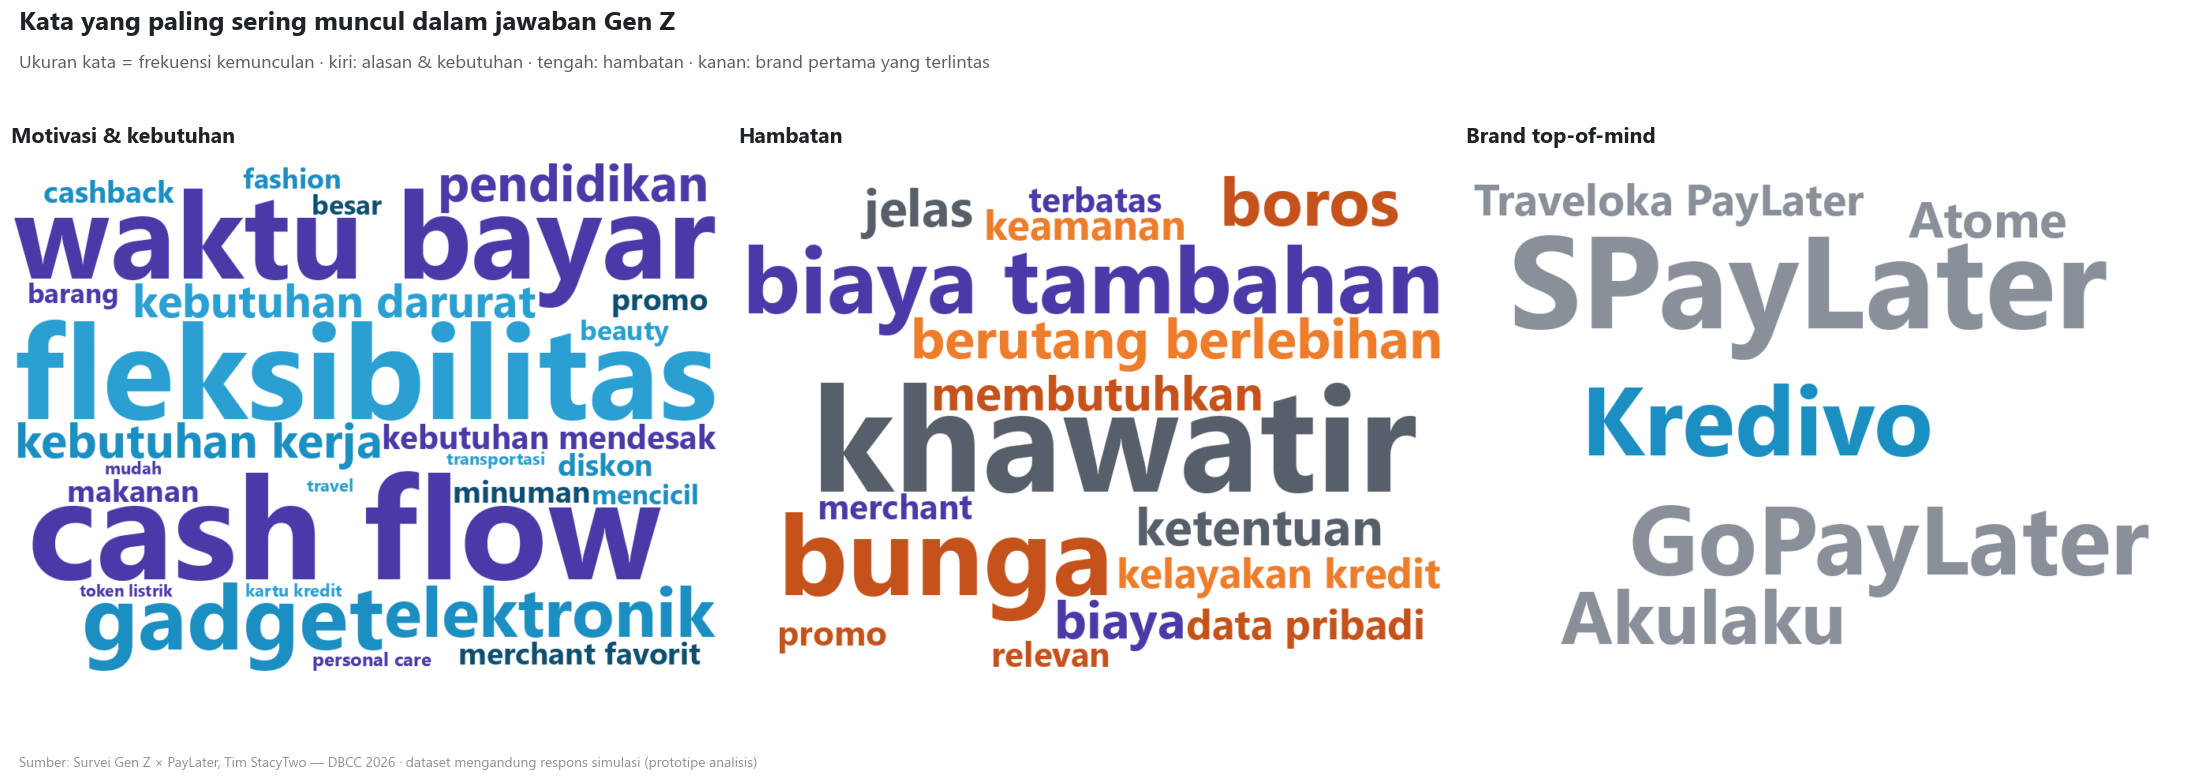

In [42]:
STOPWORDS_ID = set('yang dan atau di ke dari untuk dengan saya terhadap belum masih lebih cukup daripada ada tidak '
                   'sudah pernah tetapi ini itu per yg dalam pada bernilai mengatur memenuhi tersedia paylater'.split())
FRASA = ['cash flow', 'kartu kredit', 'data pribadi', 'biaya tambahan', 'kelayakan kredit', 'personal care',
         'token listrik', 'waktu bayar', 'waktu pembayaran', 'kebutuhan mendesak', 'kebutuhan darurat', 'kebutuhan kerja',
         'berutang berlebihan', 'merchant favorit']

def hitung_kata(teks_list):
    c = Counter()
    for t in teks_list:
        t = str(t).lower()
        for f in FRASA:
            t = t.replace(f, f.replace(' ', '_'))
        for tok in re.findall(r'[a-z_&]+', t):
            if tok not in STOPWORDS_ID and len(tok) > 2:
                c[tok.replace('_', ' ')] += 1
    return c

korpus_motivasi = [a for l in df.alasan for a in l if a != 'Belum tertarik PayLater'] + [k for l in df.kebutuhan for k in l]
kata_motivasi = hitung_kata(korpus_motivasi)
kata_hambatan = hitung_kata(df.hambatan)
kata_brand = Counter(df.tom)

FONT_PATH = next((p for p in ['C:/Windows/Fonts/segoeuib.ttf', 'C:/Windows/Fonts/arialbd.ttf'] if Path(p).exists()), None)
def pewarna(palet):
    return lambda word, **kw: palet[sum(map(ord, word)) % len(palet)]

fig, axes = plt.subplots(1, 3, figsize=(20, 7.2))
awan = [
    (kata_motivasi, 'Motivasi & kebutuhan', pewarna([BIRU, BIRU_TUA, '#2A9FD2', UNGU])),
    (kata_hambatan, 'Hambatan', pewarna([ORANYE, ORANYE_TUA, UNGU, TEKS2])),
    (kata_brand, 'Brand top-of-mind', lambda word, **kw: BIRU if word == 'Kredivo' else ABU_TUA),
]
for ax, (freq, judul, cf) in zip(axes, awan):
    wc = WordCloud(width=900, height=650, background_color='white', font_path=FONT_PATH, color_func=cf,
                   prefer_horizontal=0.95, max_words=40, relative_scaling=0.5, margin=6, random_state=7)
    wc.generate_from_frequencies(freq)
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(judul, fontsize=14)
bingkai(fig, 'Kata yang paling sering muncul dalam jawaban Gen Z',
        'Ukuran kata = frekuensi kemunculan · kiri: alasan & kebutuhan · tengah: hambatan · kanan: brand pertama yang terlintas')
simpan(fig, '15a_word_cloud')

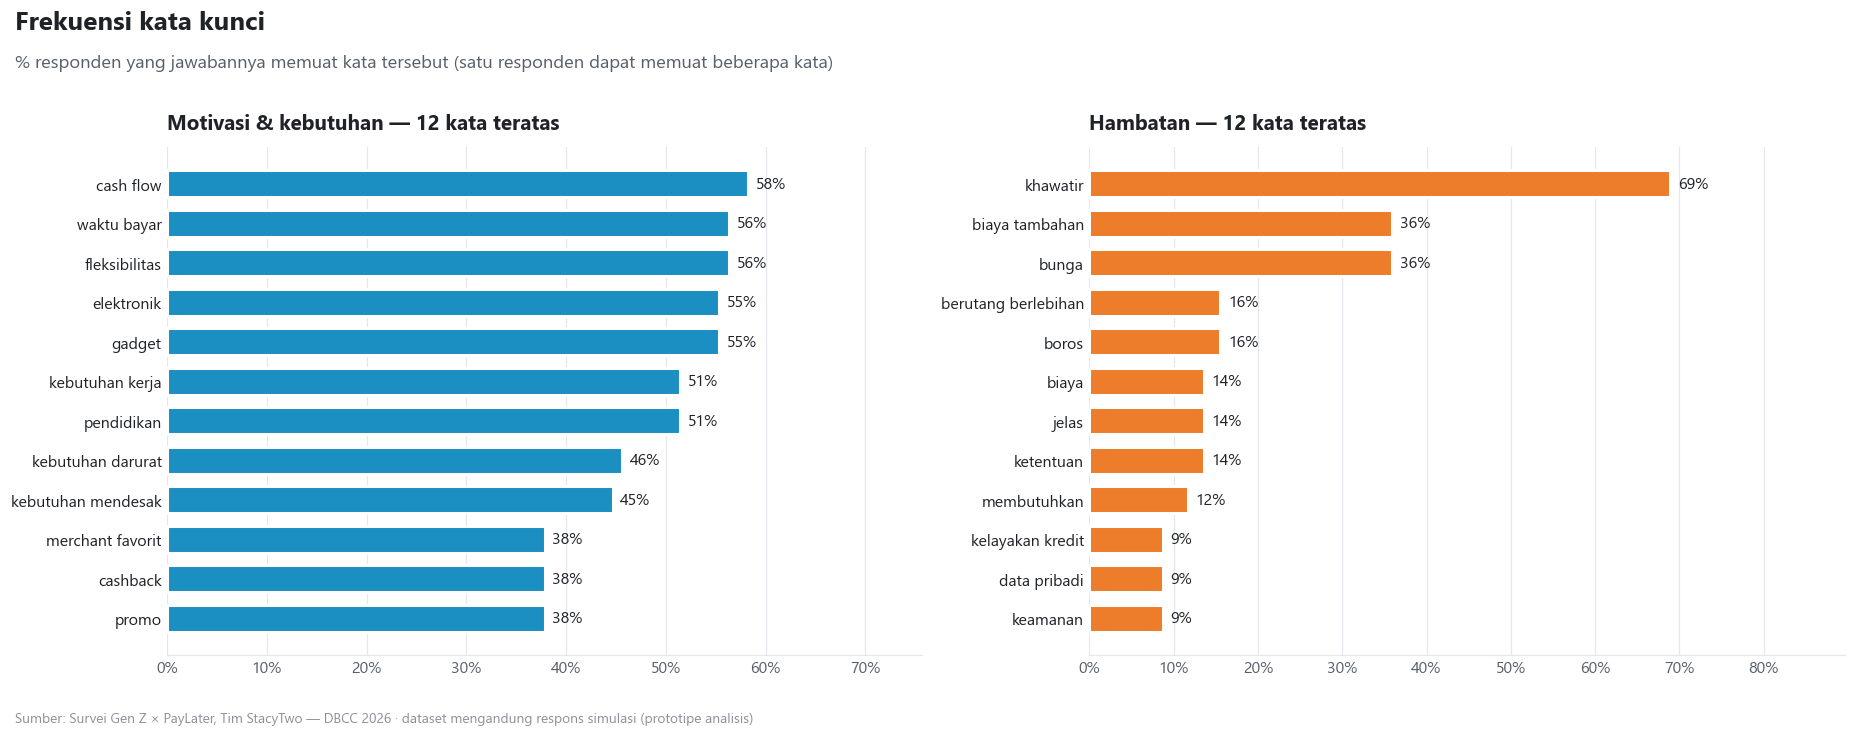

> ### 💡 Insight kata yang sering muncul
>
> - Kosakata motivasi didominasi **cash flow**, **fleksibilitas**, **waktu bayar**, **gadget**, **elektronik** → bahasa yang dekat dengan Gen Z adalah **kebutuhan, fleksibilitas & cash flow**, bukan "belanja lebih banyak".
> - Kosakata hambatan didominasi **khawatir**, **bunga**, **biaya tambahan**, **boros**, **berutang berlebihan** → emosi utama adalah **kekhawatiran** terhadap biaya/bunga. Copywriting Kredivo sebaiknya menjawab kekhawatiran ini secara langsung: *"tahu total biayanya sebelum bayar"*.
> - Pada top-of-mind, **SPayLater** tampil paling besar; Kredivo baru 20% → visual ini ringkas untuk slide *The Paradox*.

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.8))
for ax, freq, warna, judul, total in [(ax1, kata_motivasi, BIRU, 'Motivasi & kebutuhan — 12 kata teratas', len(df)),
                                      (ax2, kata_hambatan, ORANYE, 'Hambatan — 12 kata teratas', len(df))]:
    s = pd.Series(dict(freq.most_common(12))) / total
    bar_h(ax, s, warna=warna, lebar=22)
    ax.set_title(judul)
bingkai(fig, 'Frekuensi kata kunci', '% responden yang jawabannya memuat kata tersebut (satu responden dapat memuat beberapa kata)')
simpan(fig, '15b_frekuensi_kata')

insight('Insight kata yang sering muncul', [
    'Kosakata motivasi didominasi ' + ', '.join(f"**{k}**" for k, _ in kata_motivasi.most_common(5)) + ' → bahasa yang dekat dengan Gen Z adalah **kebutuhan, fleksibilitas & cash flow**, bukan "belanja lebih banyak".',
    'Kosakata hambatan didominasi ' + ', '.join(f"**{k}**" for k, _ in kata_hambatan.most_common(5)) + ' → emosi utama adalah **kekhawatiran** terhadap biaya/bunga. Copywriting Kredivo sebaiknya menjawab kekhawatiran ini secara langsung: *"tahu total biayanya sebelum bayar"*.',
    f"Pada top-of-mind, **{pemimpin_tom}** tampil paling besar; Kredivo baru {fpct(tom_share.get('Kredivo', 0))} → visual ini ringkas untuk slide *The Paradox*.",
])

## 16. WOW Strategy Evidence Board
Satu halaman yang merangkum **bukti survei → gap → solusi WOW → KPI**. Board ini dirancang agar bisa langsung dipakai sebagai slide *"Who exactly are we winning + Consumer Research"* atau lampiran pitch deck.

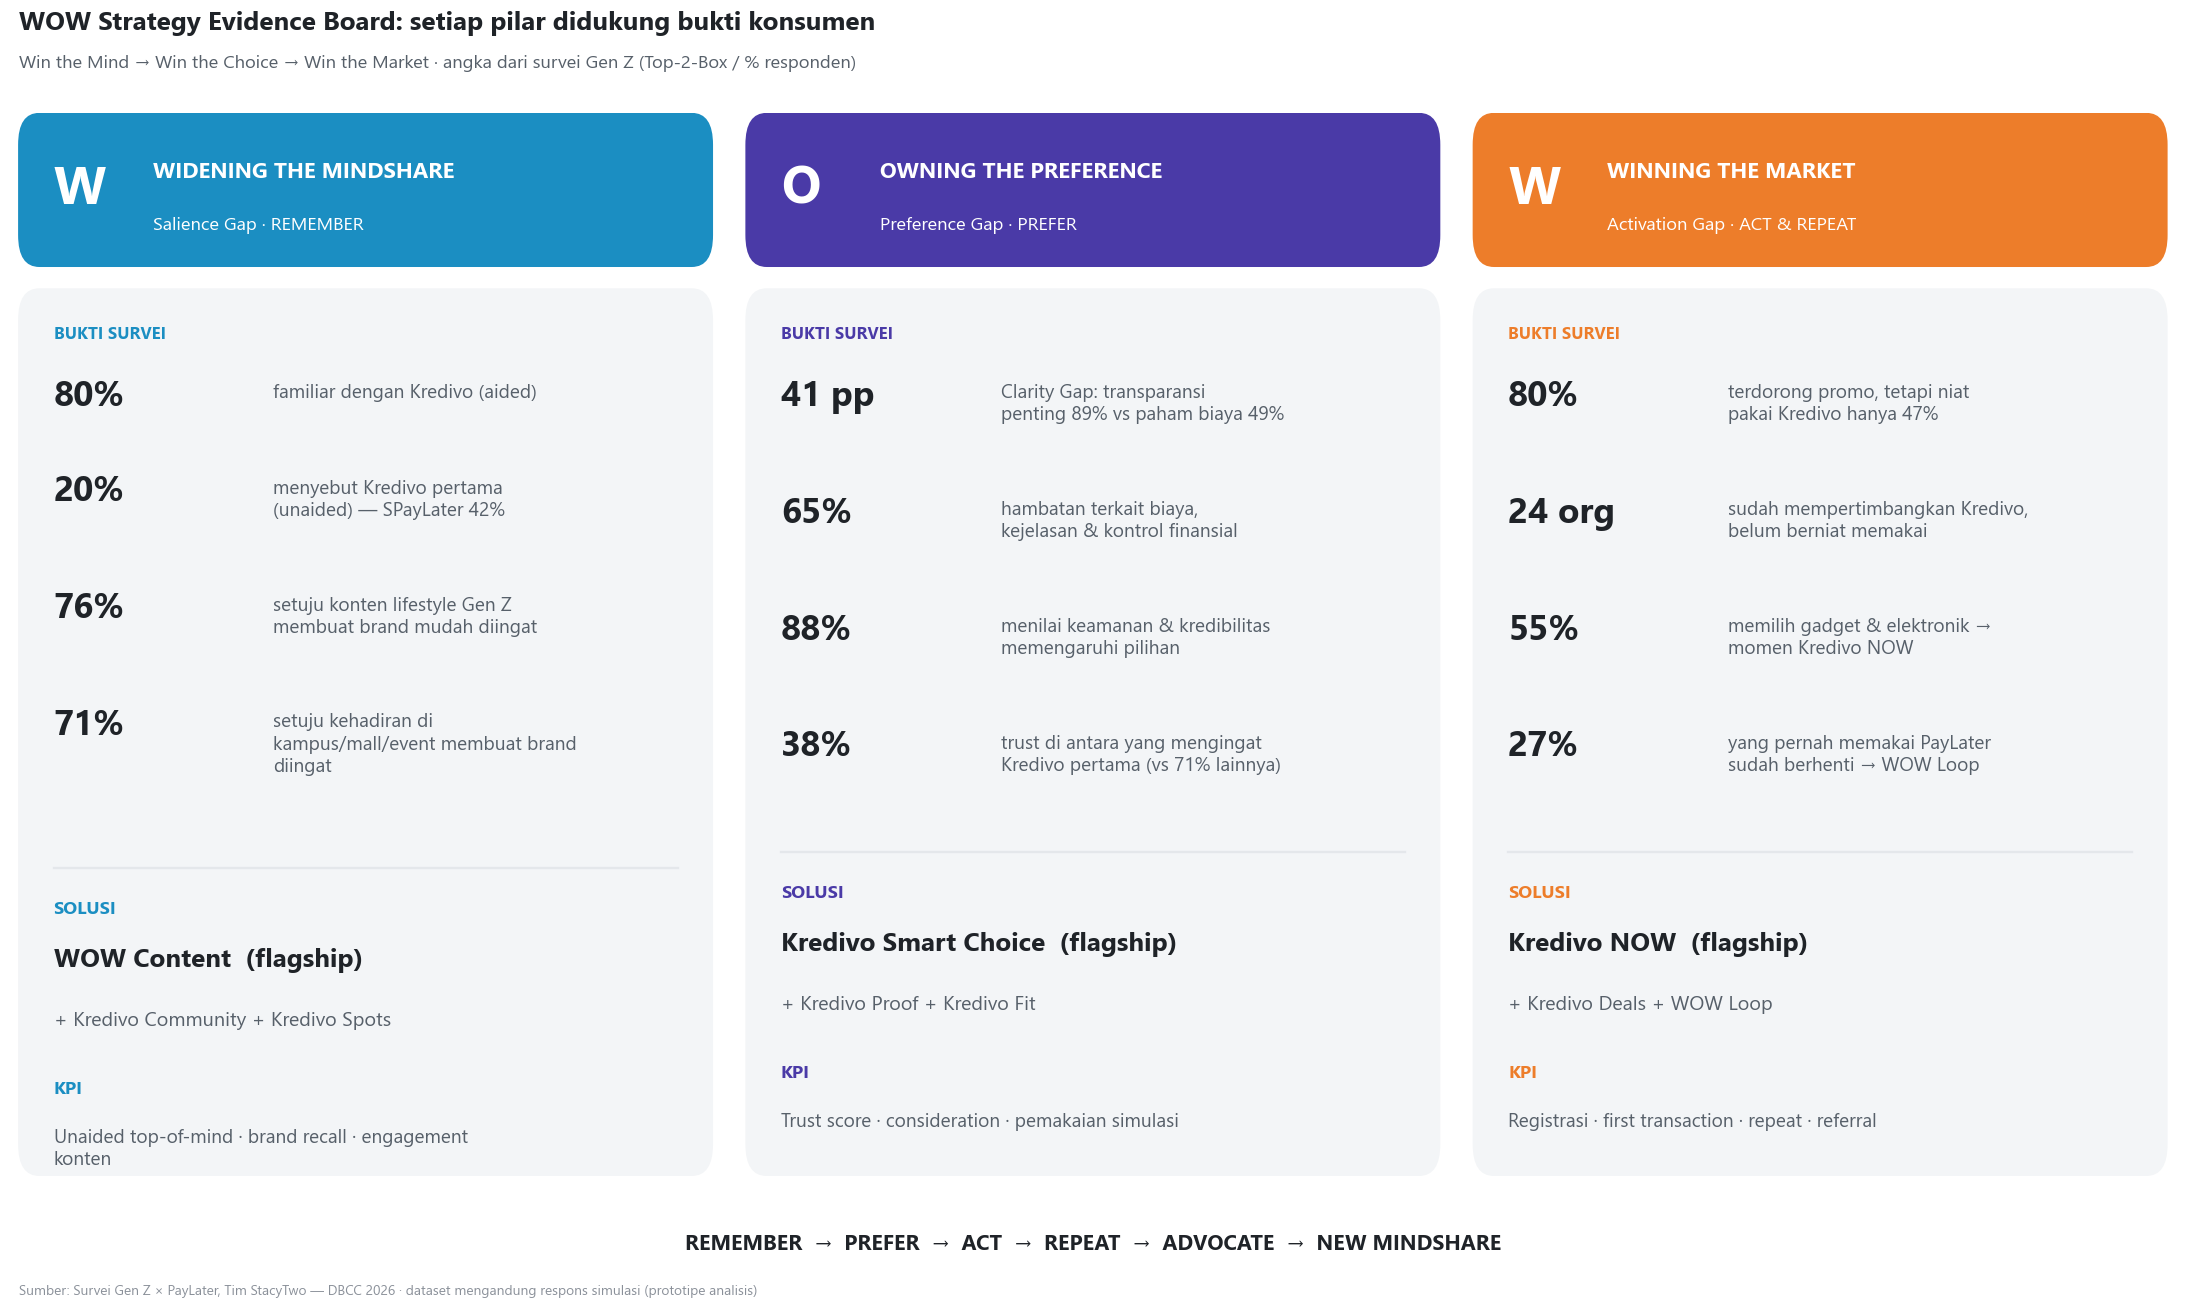

In [44]:
tema_sc = tm.get('Biaya & Kejelasan', 0) + tm.get('Kontrol Finansial', 0)
top_keb = keb_pct.idxmax()
board = [
    ('W', 'WIDENING THE MINDSHARE', 'Salience Gap · REMEMBER', 'Widening', [
        (fpct(T2B['k_familiar']), 'familiar dengan Kredivo (aided)'),
        (fpct(tom_share.get('Kredivo', 0)), f"menyebut Kredivo pertama (unaided) — {pemimpin_tom} {fpct(tom_share.iloc[0])}"),
        (fpct(T2B['konten']), 'setuju konten lifestyle Gen Z membuat brand mudah diingat'),
        (fpct(T2B['fisik']), 'setuju kehadiran di kampus/mall/event membuat brand diingat'),
    ], 'WOW Content', 'Kredivo Community + Kredivo Spots', 'Unaided top-of-mind · brand recall · engagement konten'),
    ('O', 'OWNING THE PREFERENCE', 'Preference Gap · PREFER', 'Owning', [
        (f"{gap_clarity * 100:.0f} pp", f"Clarity Gap: transparansi penting {fpct(T2B['transparan'])} vs paham biaya {fpct(T2B['paham'])}"),
        (fpct(tema_sc), 'hambatan terkait biaya, kejelasan & kontrol finansial'),
        (fpct(T2B['aman']), 'menilai keamanan & kredibilitas memengaruhi pilihan'),
        (fpct(trust_tom), f"trust di antara yang mengingat Kredivo pertama (vs {fpct(trust_lain)} lainnya)"),
    ], 'Kredivo Smart Choice', 'Kredivo Proof + Kredivo Fit', 'Trust score · consideration · pemakaian simulasi'),
    ('W', 'WINNING THE MARKET', 'Activation Gap · ACT & REPEAT', 'Winning', [
        (fpct(T2B['promo']), f"terdorong promo, tetapi niat pakai Kredivo hanya {fpct(T2B['k_intent'])}"),
        (f"{len(pool)} org", 'sudah mempertimbangkan Kredivo, belum berniat memakai'),
        (fpct(keb_pct.max()), f"memilih {top_keb.lower()} → momen Kredivo NOW"),
        (fpct(churn), 'yang pernah memakai PayLater sudah berhenti → WOW Loop'),
    ], 'Kredivo NOW', 'Kredivo Deals + WOW Loop', 'Registrasi · first transaction · repeat · referral'),
]
fig, axes = plt.subplots(1, 3, figsize=(20, 12))
for ax, (huruf, pilar, gap, kunci, bukti, flagship, support, kpi) in zip(axes, board):
    c = PILAR_WARNA[kunci]
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    ax.add_patch(FancyBboxPatch((0.01, 0.855), 0.98, 0.145, boxstyle='round,pad=0,rounding_size=0.03', facecolor=c, edgecolor='none'))
    ax.text(0.06, 0.928, huruf, fontsize=34, fontweight='bold', color='white', va='center')
    ax.text(0.20, 0.945, pilar, fontsize=14.5, fontweight='bold', color='white', va='center')
    ax.text(0.20, 0.895, gap, fontsize=12, color='white', va='center')
    ax.add_patch(FancyBboxPatch((0.01, 0.0), 0.98, 0.835, boxstyle='round,pad=0,rounding_size=0.03', facecolor=ABU_MUDA, edgecolor='none'))
    y = 0.80
    ax.text(0.06, y, 'BUKTI SURVEI', fontsize=11, fontweight='bold', color=c, va='top'); y -= 0.05
    for angka, ket in bukti:
        baris_ket = wrap(ket, 32)
        ax.text(0.06, y, angka, fontsize=23, fontweight='bold', color=TEKS, va='top')
        ax.text(0.37, y - 0.004, baris_ket, fontsize=12.5, color=TEKS2, va='top', linespacing=1.3)
        y -= max(0.09, 0.035 * (baris_ket.count('\n') + 1) + 0.04)
    y -= 0.005
    ax.plot([0.06, 0.94], [y, y], color=GRID, linewidth=1.5); y -= 0.03
    ax.text(0.06, y, 'SOLUSI', fontsize=12, fontweight='bold', color=c, va='top'); y -= 0.045
    ax.text(0.06, y, f'{flagship}  (flagship)', fontsize=17, fontweight='bold', color=TEKS, va='top'); y -= 0.06
    ax.text(0.06, y, f'+ {support}', fontsize=13, color=TEKS2, va='top'); y -= 0.065
    ax.text(0.06, y, 'KPI', fontsize=12, fontweight='bold', color=c, va='top'); y -= 0.045
    ax.text(0.06, y, wrap(kpi, 52), fontsize=12.5, color=TEKS2, va='top', linespacing=1.3)
fig.text(0.5, 0.045, 'REMEMBER  →  PREFER  →  ACT  →  REPEAT  →  ADVOCATE  →  NEW MINDSHARE', ha='center',
         fontsize=14, fontweight='bold', color=TEKS)
bingkai(fig, 'WOW Strategy Evidence Board: setiap pilar didukung bukti konsumen',
        'Win the Mind → Win the Choice → Win the Market · angka dari survei Gen Z (Top-2-Box / % responden)')
fig.subplots_adjust(bottom=0.1)
simpan(fig, '16_wow_evidence_board')

In [45]:
evidence_map = pd.DataFrame([
    ['Kredivo dikenal tetapi jarang diingat pertama', f"Familiar {fpct(T2B['k_familiar'])} vs TOM {fpct(tom_share.get('Kredivo', 0))}", 'Salience Gap', 'Widening', 'WOW Content', 'Unaided TOM, brand recall'],
    ['Konten & kehadiran fisik membantu brand diingat', f"Konten {fpct(T2B['konten'])} · fisik {fpct(T2B['fisik'])}", 'Salience Gap', 'Widening', 'Community + Spots', 'Engagement, footfall booth'],
    ['Gen Z menuntut transparansi tetapi belum paham biaya', f"{fpct(T2B['transparan'])} vs {fpct(T2B['paham'])}", 'Preference Gap', 'Owning', 'Smart Choice', '% user memakai simulasi'],
    ['Hambatan terbesar: biaya, kejelasan & kontrol', f"{fpct(tema_sc)} responden", 'Preference Gap', 'Owning', 'Smart Choice + Proof', 'Trust score, consideration'],
    ['Mengingat Kredivo ≠ mempercayai Kredivo', f"Trust {fpct(trust_tom)} vs {fpct(trust_lain)}", 'Preference Gap', 'Owning', 'Kredivo Proof', 'Trust score'],
    ['Relevansi kebutuhan paling terkait dengan niat pakai', f"ρ = {fnum(ipa.set_index('kode').loc['relevan', 'y'], 2)}", 'Preference Gap', 'Owning', 'Kredivo Fit', 'Consideration per segmen'],
    ['Promo tinggi tetapi niat pakai rendah', f"Promo {fpct(T2B['promo'])} vs niat {fpct(T2B['k_intent'])}", 'Activation Gap', 'Winning', 'Kredivo NOW + Deals', 'First transaction'],
    ['Pool mempertimbangkan tapi belum berniat', f"{len(pool)} responden ({fpct(len(pool) / N)})", 'Activation Gap', 'Winning', 'Kredivo NOW', 'Conversion rate'],
    ['Churn pengguna PayLater', f"{fpct(churn)} berhenti", 'Activation Gap', 'Winning', 'WOW Loop', 'Repeat rate, referral'],
], columns=['Insight', 'Bukti survei', 'Gap', 'Pilar WOW', 'Mekanisme', 'KPI'])
display(evidence_map.style.hide(axis='index'))

Insight,Bukti survei,Gap,Pilar WOW,Mekanisme,KPI
Kredivo dikenal tetapi jarang diingat pertama,Familiar 80% vs TOM 20%,Salience Gap,Widening,WOW Content,"Unaided TOM, brand recall"
Konten & kehadiran fisik membantu brand diingat,Konten 76% · fisik 71%,Salience Gap,Widening,Community + Spots,"Engagement, footfall booth"
Gen Z menuntut transparansi tetapi belum paham biaya,89% vs 49%,Preference Gap,Owning,Smart Choice,% user memakai simulasi
"Hambatan terbesar: biaya, kejelasan & kontrol",65% responden,Preference Gap,Owning,Smart Choice + Proof,"Trust score, consideration"
Mengingat Kredivo ≠ mempercayai Kredivo,Trust 38% vs 71%,Preference Gap,Owning,Kredivo Proof,Trust score
Relevansi kebutuhan paling terkait dengan niat pakai,"ρ = 0,21",Preference Gap,Owning,Kredivo Fit,Consideration per segmen
Promo tinggi tetapi niat pakai rendah,Promo 80% vs niat 47%,Activation Gap,Winning,Kredivo NOW + Deals,First transaction
Pool mempertimbangkan tapi belum berniat,24 responden (23%),Activation Gap,Winning,Kredivo NOW,Conversion rate
Churn pengguna PayLater,27% berhenti,Activation Gap,Winning,WOW Loop,"Repeat rate, referral"


## 17. Kesimpulan, Angka Siap Pakai & Keterbatasan

### 17.1 Angka siap pakai untuk pitch deck
Tabel berikut juga diekspor ke `outputs/ringkasan_angka_pitchdeck.csv`. Kolom *Slide* merujuk alur pitch deck semifinal di master context.

In [46]:
ringkas = pd.DataFrame([
    ['The Paradox', 'Familiar dengan Kredivo (T2B)', fpct(T2B['k_familiar'], 1), N, 'Widening'],
    ['The Paradox', 'Top-of-mind unaided Kredivo', fpct(tom_share.get('Kredivo', 0), 1), N, 'Widening'],
    ['The Paradox', f'Top-of-mind unaided {pemimpin_tom} (pemimpin)', fpct(tom_share.iloc[0], 1), N, 'Widening'],
    ['Consumer Research', 'Pernah memakai PayLater', fpct(df.pernah_pakai.mean(), 1), N, '-'],
    ['Consumer Research', 'Non-pengguna tertarik mencoba', fpct(minat_nonuser, 1), len(belum), 'Winning'],
    ['Consumer Research', 'Pengguna PayLater yang berhenti (churn)', fpct(churn, 1), len(pernah), 'Winning'],
    ['Consumer Research', 'Mulai mandiri finansial (≥ Rp1 jt)', fpct(df.mandiri_finansial.mean(), 1), N, '-'],
    ['Root Cause', 'Transparansi memengaruhi trust (T2B)', fpct(T2B['transparan'], 1), N, 'Owning'],
    ['Root Cause', 'Paham biaya, bunga & risiko (T2B)', fpct(T2B['paham'], 1), N, 'Owning'],
    ['Root Cause', 'Clarity Gap', f"{gap_clarity * 100:.1f} pp".replace('.', ','), N, 'Owning'],
    ['Root Cause', 'Hambatan biaya & kejelasan', fpct(tm.get('Biaya & Kejelasan', 0), 1), N, 'Owning'],
    ['Root Cause', 'Promo mendorong mencoba (T2B)', fpct(T2B['promo'], 1), N, 'Winning'],
    ['Brand Funnel', 'Percaya Kredivo (T2B)', fpct(T2B['k_trust'], 1), N, 'Owning'],
    ['Brand Funnel', 'Mempertimbangkan Kredivo (T2B)', fpct(T2B['k_consider'], 1), N, 'Owning'],
    ['Brand Funnel', 'Niat pakai Kredivo 6 bln (T2B)', fpct(T2B['k_intent'], 1), N, 'Winning'],
    ['Brand Funnel', 'Lolos seluruh funnel (kumulatif)', fpct(kum.iloc[-1], 1), N, 'WOW'],
    ['Widening', 'Konten lifestyle membuat brand diingat (T2B)', fpct(T2B['konten'], 1), N, 'Widening'],
    ['Widening', 'Kehadiran fisik membuat brand diingat (T2B)', fpct(T2B['fisik'], 1), N, 'Widening'],
    ['Owning', 'Trust Kredivo: yang mengingat Kredivo pertama', fpct(trust_tom, 1), int(df.tom_kredivo.sum()), 'Owning'],
    ['Winning', f'Kebutuhan teratas: {top_keb}', fpct(keb_pct.max(), 1), N, 'Winning'],
    ['Winning', 'Pool aktivasi (pertimbangkan, belum berniat)', f'{len(pool)} responden', N, 'Winning'],
    ['Persona Raka', 'Target Inti (Surabaya + penghasilan ≥ Rp1 jt)', f'{len(ti)} responden', N, 'Semua'],
], columns=['Slide', 'Metrik', 'Nilai', 'Basis (n)', 'Pilar WOW'])
label_sumber = f"Primary Survey StacyTwo, n = {N}, Gen Z, 2026" + (' — SIMULASI, jangan dipresentasikan sebagai data riil' if DATA_MENGANDUNG_SIMULASI else '')
ringkas['Label sumber'] = label_sumber
ringkas.to_csv(OUT_DIR / 'ringkasan_angka_pitchdeck.csv', index=False, encoding='utf-8-sig')

olah = df.drop(columns=['alasan_raw', 'kebutuhan_raw']).copy()
olah['alasan'] = olah['alasan'].str.join('; ')
olah['kebutuhan'] = olah['kebutuhan'].str.join('; ')
olah.to_csv(OUT_DIR / 'dataset_olah.csv', index=False, encoding='utf-8-sig')
persona_df.to_csv(OUT_DIR / 'persona_segmen.csv', index=False, encoding='utf-8-sig')

display(ringkas.drop(columns='Label sumber').style.hide(axis='index'))
print(f"Diekspor ke {OUT_DIR.resolve()}:")
for f in ['ringkasan_angka_pitchdeck.csv', 'dataset_olah.csv', 'persona_segmen.csv']:
    print('  -', f)
print(f"  - {len(list(FIG_DIR.glob('*.png')))} grafik PNG di folder figures/")

Slide,Metrik,Nilai,Basis (n),Pilar WOW
The Paradox,Familiar dengan Kredivo (T2B),"79,6%",103,Widening
The Paradox,Top-of-mind unaided Kredivo,"20,4%",103,Widening
The Paradox,Top-of-mind unaided SPayLater (pemimpin),"41,7%",103,Widening
Consumer Research,Pernah memakai PayLater,"58,3%",103,-
Consumer Research,Non-pengguna tertarik mencoba,"76,7%",43,Winning
Consumer Research,Pengguna PayLater yang berhenti (churn),"26,7%",60,Winning
Consumer Research,Mulai mandiri finansial (≥ Rp1 jt),"73,8%",103,-
Root Cause,Transparansi memengaruhi trust (T2B),"89,3%",103,Owning
Root Cause,"Paham biaya, bunga & risiko (T2B)","48,5%",103,Owning
Root Cause,Clarity Gap,"40,8 pp",103,Owning


Diekspor ke C:\Users\ASUS\xStyNWx\Documents\BINUS University\Competition\2026\00. Bersama Stacy\03. DBCC\Repo\data-analysis\outputs:
  - ringkasan_angka_pitchdeck.csv
  - dataset_olah.csv
  - persona_segmen.csv
  - 37 grafik PNG di folder figures/


### 17.2 Kesimpulan utama

In [47]:
KATA = "terindikasi (data prototipe)" if DATA_MENGANDUNG_SIMULASI else "terkonfirmasi"
display(Markdown(f"""
**1. SALIENCE GAP {KATA} — Kredivo dikenal, tetapi tidak diingat pertama.**
{fpct(T2B['k_familiar'])} Gen Z familiar dengan Kredivo, tetapi hanya {fpct(tom_share.get('Kredivo', 0))} yang menyebutnya pertama kali; {pemimpin_tom} memimpin dengan {fpct(tom_share.iloc[0])}. Kesenjangan paling tajam justru di segmen berpenghasilan (Karyawan {fpct(df[df.status == 'Karyawan'].tom_kredivo.mean())}). Konten lifestyle ({fpct(T2B['konten'])}) dan kehadiran fisik ({fpct(T2B['fisik'])}) diakui efektif membangun ingatan → **Widening the Mindshare: WOW Content + Community + Spots.**

**2. PREFERENCE GAP {KATA} — trust & kejelasan biaya adalah medan pertempuran utama.**
Transparansi ({fpct(T2B['transparan'])}) dan keamanan ({fpct(T2B['aman'])}) adalah driver nomor satu, tetapi hanya {fpct(T2B['paham'])} yang paham biaya & risiko (Clarity Gap {gap_clarity * 100:.0f} pp). {fpct(tema_sc)} hambatan berkaitan dengan biaya, kejelasan & kontrol. Mengingat Kredivo tidak otomatis membuat percaya ({fpct(trust_tom)} vs {fpct(trust_lain)}) → **Owning the Preference: Smart Choice + Proof + Fit.**

**3. ACTIVATION GAP {KATA} — pemicu kategori kuat, aktivasi Kredivo lemah.**
Promo ({fpct(T2B['promo'])}), kecepatan ({fpct(T2B['cepat'])}) dan merchant ({fpct(T2B['merchant'])}) adalah hygiene factor kategori, sementara niat memakai Kredivo baru {fpct(T2B['k_intent'])}. Funnel kumulatif hanya menyisakan {fpct(kum.iloc[-1], 1)} hingga niat pakai; {len(pool)} responden sudah mempertimbangkan tetapi belum berniat; {fpct(churn)} pengguna PayLater berhenti → **Winning the Market: Kredivo NOW + Deals + WOW Loop.**

**4. Positioning yang tepat: Responsible Financial Flexibility.**
Alasan utama Gen Z memakai PayLater adalah *mengatur cash flow* ({fpct(alasan_pct['Mengatur cash flow'])}) dan *fleksibilitas waktu bayar* ({fpct(alasan_pct['Fleksibilitas waktu bayar'])}), bukan promo ({fpct(alasan_pct['Promo, cashback, diskon'])}). Gen Z tidak butuh *lebih banyak daya beli* — mereka butuh **fleksibilitas yang tepat, di momen yang tepat, dengan kejelasan & kontrol.**

**5. Target Inti (Persona Raka) relevan.** {len(ti)} responden ({fpct(len(ti) / N)}) adalah Gen Z Surabaya yang mulai mandiri finansial; mereka lebih mengingat Kredivo tetapi Clarity Gap-nya lebih lebar → Smart Choice adalah kunci memenangkan Raka.

> **One-liner untuk pitch deck:** *Kredivo is seen, but not yet remembered, chosen, and used. WOW Strategy closes all three gaps — Win the Mind, Win the Choice, Win the Market.*
"""))


**1. SALIENCE GAP terindikasi (data prototipe) — Kredivo dikenal, tetapi tidak diingat pertama.**
80% Gen Z familiar dengan Kredivo, tetapi hanya 20% yang menyebutnya pertama kali; SPayLater memimpin dengan 42%. Kesenjangan paling tajam justru di segmen berpenghasilan (Karyawan 10%). Konten lifestyle (76%) dan kehadiran fisik (71%) diakui efektif membangun ingatan → **Widening the Mindshare: WOW Content + Community + Spots.**

**2. PREFERENCE GAP terindikasi (data prototipe) — trust & kejelasan biaya adalah medan pertempuran utama.**
Transparansi (89%) dan keamanan (88%) adalah driver nomor satu, tetapi hanya 49% yang paham biaya & risiko (Clarity Gap 41 pp). 65% hambatan berkaitan dengan biaya, kejelasan & kontrol. Mengingat Kredivo tidak otomatis membuat percaya (38% vs 71%) → **Owning the Preference: Smart Choice + Proof + Fit.**

**3. ACTIVATION GAP terindikasi (data prototipe) — pemicu kategori kuat, aktivasi Kredivo lemah.**
Promo (80%), kecepatan (82%) dan merchant (78%) adalah hygiene factor kategori, sementara niat memakai Kredivo baru 47%. Funnel kumulatif hanya menyisakan 7,8% hingga niat pakai; 24 responden sudah mempertimbangkan tetapi belum berniat; 27% pengguna PayLater berhenti → **Winning the Market: Kredivo NOW + Deals + WOW Loop.**

**4. Positioning yang tepat: Responsible Financial Flexibility.**
Alasan utama Gen Z memakai PayLater adalah *mengatur cash flow* (58%) dan *fleksibilitas waktu bayar* (56%), bukan promo (38%). Gen Z tidak butuh *lebih banyak daya beli* — mereka butuh **fleksibilitas yang tepat, di momen yang tepat, dengan kejelasan & kontrol.**

**5. Target Inti (Persona Raka) relevan.** 42 responden (41%) adalah Gen Z Surabaya yang mulai mandiri finansial; mereka lebih mengingat Kredivo tetapi Clarity Gap-nya lebih lebar → Smart Choice adalah kunci memenangkan Raka.

> **One-liner untuk pitch deck:** *Kredivo is seen, but not yet remembered, chosen, and used. WOW Strategy closes all three gaps — Win the Mind, Win the Choice, Win the Market.*


### 17.3 Keterbatasan & langkah selanjutnya
1. **Asal-usul data.** Lihat Bagian 2.4 — selama `DATA_MENGANDUNG_SIMULASI = True`, angka di notebook ini hanya untuk prototipe analisis, latihan storytelling dan desain chart. Jangan mencantumkannya sebagai hasil survei riil di pitch deck. Setelah respons asli terkumpul, cukup ganti `dataset.csv` (struktur kolom sama) lalu *Run All*.
2. **Ukuran & komposisi sampel.** n = 103 memberi margin of error sekitar ±9,7 pp (95%, proporsi 50%). Beberapa subsegmen (misalnya *Sedang mencari kerja*, n = 9) terlalu kecil untuk disimpulkan sendiri. Untuk data riil, targetkan kuota minimal ±30 responden per segmen utama dan mayoritas dari Surabaya.
3. **Self-reported & non-probability sampling.** Jawaban mengukur persepsi dan niat, bukan perilaku transaksi aktual; penyebaran Google Form cenderung menjangkau jaringan tim. Validasi lanjutan idealnya memakai data internal Kredivo (registrasi, transaksi, repeat) saat pilot.
4. **Pertanyaan tertutup.** Word cloud dibangun dari opsi jawaban. Menambahkan satu pertanyaan terbuka (*"Apa yang membuat Anda memilih/tidak memilih Kredivo?"*) akan memperkaya analisis teks dan *consumer voice* untuk slide.
5. **Segmentasi & key driver bersifat indikatif** (silhouette dan korelasi rendah). Gunakan sebagai kerangka persona & pesan, lalu uji ulang pada data riil dan pada fase *Validate → Pilot* WOW Strategy.

---
*Notebook ini dibuat oleh Tim StacyTwo untuk DBCC 2026 — seluruh grafik tersedia di `outputs/figures/`.*